# Search Algorithms on OpenStreetMap: Bidirectional Dijkstra, A* and Hill Climbing

This notebook runs and visualizes three search algorithms on real street networks downloaded from OSM:

| Algorithm | Type | Uses heuristic? | Complete | Optimal |
|---|---|---|---|---|
| **Bidirectional Dijkstra** | uninformed, two-sided uniform-cost | no | yes | yes |
| **A\*** | informed, best-first | yes (straight-line distance) | yes | yes (admissible *h*) |
| **Hill Climbing** | informed, local search | yes (straight-line distance) | no | no |

It is completely place-agnostic: change the `PLACE` string in the configuration cell to any town on Earth and the notebook handles downloading, scaling, animating and comparing.

**Structure:** sections 1-11 build the pipeline and animate one algorithm (`ALGORITHM`); sections 12-14 are the lab report: **Design**, **Implementation**, **Result** (comparison of all three algorithms, figures saved to `results/`, and a generated `RESULTS.md`).

### 1. Setup & Environment
Checks for required libraries and imports them. Fails clearly if geo-dependencies are missing.

In [1]:
# --- 1. Install anything that is missing (pip only runs if a package is absent) ---
import importlib.util
import subprocess
import sys

_REQUIRED = {               # import name -> pip requirement
    "osmnx": "osmnx>=2.0",
    "networkx": "networkx>=3.0",
    "numpy": "numpy",
    "shapely": "shapely>=2.0",
    "PIL": "pillow>=10.1",
    "imageio_ffmpeg": "imageio-ffmpeg",   # ships its own ffmpeg binary (no system ffmpeg needed)
    "matplotlib": "matplotlib",           # only used for its bundled DejaVu fonts in the MP4 renderer
}
_missing = [req for mod, req in _REQUIRED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("Installing missing packages:", ", ".join(_missing))
    # Equivalent to `%pip install ...` but also works when the cells are run as a script.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])
    importlib.invalidate_caches()

# --- 2. Import the geo stack; stop with a clear message if it is broken on this Python ---
try:
    import osmnx as ox
    import geopandas  # noqa: F401  (imported to verify the geo stack works)
    import pyproj     # noqa: F401
    import shapely
except Exception as exc:  # pragma: no cover - environment problem, not a code problem
    raise ImportError(
        f"osmnx or one of its geo dependencies failed to import on Python {sys.version.split()[0]}:\n"
        f"    {type(exc).__name__}: {exc}\n"
        "Please run this notebook in a Python 3.11 or 3.12 virtual environment (see README.md)."
    ) from exc

if int(ox.__version__.split(".")[0]) < 2:
    raise ImportError(f"osmnx >= 2.0 is required (found {ox.__version__}). Run: pip install -U osmnx")

# --- 3. Standard imports used throughout the notebook ---
import hashlib
import heapq
import html
import json
import math
import random
import re
import statistics
import time
from dataclasses import dataclass, field
from pathlib import Path
from typing import Callable, Optional

import networkx as nx
import numpy as np
from IPython.display import HTML, Video, display

print(f"Python {sys.version.split()[0]} | osmnx {ox.__version__} | networkx {nx.__version__} "
      f"| shapely {shapely.__version__} | numpy {np.__version__}")


Python 3.12.0 | osmnx 2.1.1 | networkx 3.7 | shapely 2.1.2 | numpy 2.5.3


### 2. Configuration
The only cell you need to edit. Defines place, network type, seed, and visual styles.

In [2]:
# =============================================================================
#  CONFIGURATION — the ONLY cell you need to edit.
#  Change PLACE to any town / neighbourhood on Earth and "Run All".
# =============================================================================
PLACE = "Centro Storico, Lucca, Italy"
NETWORK_TYPE = "walk"              # "walk", "bike", "drive", or "all"
SEED = 42                          # controls the random choice of A and B
MAX_NODES = 15000                  # size guard: bigger graphs are re-fetched smaller
FALLBACK_RADIUS_M = 1200           # radius used when PLACE geocodes to a point
MIN_AB_DISTANCE_FRACTION = 0.5     # A-B straight-line distance, as a fraction of the map diagonal
TARGET_ANIMATION_SECONDS = 8       # total animation length (search + path draw + final hold)
ASPECT = "auto"                    # "auto" (from the map's shape), "portrait" (9:16) or "square"

ALGORITHM = "Bidirectional Dijkstra"   # animated in sections 6-10: "Bidirectional Dijkstra", "A*" or "Hill Climbing"

# --- Lab report / comparison (sections 12-14) ---
COMPARE_ALGORITHMS = ["Bidirectional Dijkstra", "A*", "Hill Climbing"]
RESULTS_DIR = "results"            # figures are written here; RESULTS.md is written next to the notebook
N_RANDOM_PAIRS = 200               # random A-B pairs for the statistical comparison
TIMING_REPEATS = 20                # clean runs per algorithm; the median is reported
EXPORT_ALL_ANIMATIONS = True       # also write JSON/HTML (and MP4 if RENDER_MP4) for every compared algorithm

# --- Colours (match the reference video) ---
COLORS = {
    "background": "#04060f",          # near-black navy
    "base": "#1f3a8f",                # unexplored streets
    "explored": "#2ea8ff",            # explored streets (forward search)
    "explored_secondary": "#b66cff",  # backward search colour, for future bidirectional algorithms
    "leading": "#a8e0ff",             # brighter tint for the leading edge of the wave
    "path": "#ffffff",                # final shortest path
    "start": "#22e06b",               # A
    "end": "#ff4040",                 # B
    "title": "#a9a9c8",               # algorithm name (top-left)
    "complexity": "#8a8aa0",          # "TC: ..." (top-right)
    "stats": "#ffffff",               # "Nodes: ...  Time: ..." (top-right)
    "place": "#5f6f93",               # place name (bottom)
    "credit": "#3c4763",              # OSM attribution (bottom)
}
BASE_OPACITY = 0.75                # opacity of the unexplored street layer

# --- Glow (sizes are in px on a 720 px wide frame; everything scales with the canvas) ---
GLOW = {
    "explored_blur": 4.0,      # blur radius of the explored-street glow layer
    "explored_strength": 0.7,  # opacity of that glow layer
    "path_blur": 3.0,          # glow around the final path
    "marker_halo": 2.4,        # halo radius around A/B, as a multiple of the dot radius
    "lead_seconds": 0.3,       # how long a newly explored street stays "extra bright"
}

# --- Python-side MP4 export (works even when the viewer blocks JavaScript) ---
RENDER_MP4 = True
MP4_FPS = 30
MP4_HEIGHT = 1280                  # width follows the canvas aspect ratio (portrait -> 720x1280)

# --- Optional smoke test (no animations; checks the pipeline on other towns) ---
RUN_SMOKE_TEST = True
SMOKE_TEST_PLACES = [
    "Bruges, Belgium",           # large municipality -> exercises the size guard
    "Chefchaouen, Morocco",      # hillside medina, irregular lanes
    "Sidi Bou Said, Tunisia",    # small coastal village
    "Hallstatt, Austria",        # long, thin town squeezed between lake and mountain
]


### 3. Place-Agnostic Graph Loading
Fetches OSM data robustly: polygon geocoding -> size guard -> local caching -> projection.

In [3]:
# -----------------------------------------------------------------------------
# Graph loading: geocode -> polygon download (or radius fallback) -> size guard
# -> local file cache -> projection + cleaning. Nothing here knows about any town.
# -----------------------------------------------------------------------------
VALID_NETWORK_TYPES = ("walk", "bike", "drive", "drive_service", "all", "all_public")
CACHE_DIR = Path("osm_cache")
CACHE_DIR.mkdir(exist_ok=True)
ox.settings.use_cache = True                         # cache raw Overpass/Nominatim responses
ox.settings.cache_folder = str(CACHE_DIR / "http")
ox.settings.log_console = False
ox.settings.requests_timeout = 180

# Heuristic used only to avoid downloading obviously huge areas: urban street
# networks essentially never have fewer than this many nodes per km², so a place
# polygon bigger than MAX_NODES / this value would almost surely exceed MAX_NODES.
_MIN_PLAUSIBLE_NODES_PER_KM2 = 400
_MAX_SHRINK_ATTEMPTS = 6


class PipelineError(RuntimeError):
    """Raised with a human-readable explanation when a pipeline step fails."""


def slugify(text: str) -> str:
    """File-system-safe, collision-resistant key for a free-text string."""
    slug = re.sub(r"[^a-z0-9]+", "-", text.lower()).strip("-")[:50] or "place"
    return f"{slug}-{hashlib.md5(text.encode('utf-8')).hexdigest()[:6]}"


def _advice(network_type: str) -> str:
    return ("Suggestions: check the spelling of PLACE or make it more specific "
            "(e.g. 'Old Town, City, Country'), or try another NETWORK_TYPE "
            f"(current '{network_type}'; options: {', '.join(VALID_NETWORK_TYPES)}).")


def _graph_radius_m(G) -> float:
    """Approximate 'radius' of an unprojected graph: half its mean bbox side, in metres."""
    lats = [d["y"] for _, d in G.nodes(data=True)]
    lons = [d["x"] for _, d in G.nodes(data=True)]
    h = ox.distance.great_circle(min(lats), min(lons), max(lats), min(lons))
    w = ox.distance.great_circle(min(lats), min(lons), min(lats), max(lons))
    return max(50.0, (h + w) / 4.0)


def fetch_graph(place, network_type, fallback_radius_m, max_nodes, log=print):
    """Download the raw (unprojected) street graph for `place`, applying the size guard."""
    G, method = None, None
    try:
        gdf = ox.geocode_to_gdf(place)
    except Exception as exc:
        gdf = None
        log(f"  - Polygon geocoding failed ({type(exc).__name__}: {exc})")

    if gdf is not None:
        geom_type = gdf.geometry.iloc[0].geom_type
        if geom_type in ("Polygon", "MultiPolygon"):
            area_km2 = float(ox.projection.project_gdf(gdf).geometry.area.iloc[0]) / 1e6
            if area_km2 > max_nodes / _MIN_PLAUSIBLE_NODES_PER_KM2:
                log(f"  - Place polygon covers {area_km2:,.1f} km², far too large for "
                    f"MAX_NODES={max_nodes:,}; using a radius around its centre instead.")
            else:
                try:
                    G = ox.graph_from_place(place, network_type=network_type)
                    method = f"place polygon ({area_km2:,.2f} km²)"
                except Exception as exc:
                    log(f"  - graph_from_place failed ({type(exc).__name__}: {exc})")
        else:
            log(f"  - Geocoder returned a {geom_type}, not a polygon.")

    if G is None:
        log(f"  - Falling back to graph_from_address(dist={fallback_radius_m:,} m).")
        try:
            G = ox.graph_from_address(place, dist=fallback_radius_m, network_type=network_type)
            method = f"address + {fallback_radius_m:,} m radius"
        except Exception as exc:
            raise PipelineError(
                f"Could not download a '{network_type}' street network for PLACE='{place}'.\n"
                f"  Last error: {type(exc).__name__}: {exc}\n  {_advice(network_type)}") from exc

    # --- Size guard: never silently run on a huge graph ---
    radius = fallback_radius_m if method.startswith("address") else _graph_radius_m(G)
    center = None
    for attempt in range(_MAX_SHRINK_ATTEMPTS + 1):
        if len(G) <= max_nodes:
            break
        if attempt == _MAX_SHRINK_ATTEMPTS:
            raise PipelineError(f"Graph still has {len(G):,} nodes after {attempt} shrink attempts. "
                                f"Increase MAX_NODES or pick a smaller PLACE.")
        if center is None:
            center = ox.geocode(place)
        new_radius = max(50.0, radius * math.sqrt(max_nodes / len(G)) * 0.9)
        log(f"  ! SIZE GUARD: graph has {len(G):,} nodes > MAX_NODES={max_nodes:,}. "
            f"Re-fetching with a {new_radius:,.0f} m radius around the place centre "
            f"({center[0]:.5f}, {center[1]:.5f}).")
        G = ox.graph_from_point(center, dist=new_radius, network_type=network_type)
        radius = new_radius
        method = f"size guard: {new_radius:,.0f} m radius around the place centre"
    return G, method


def load_graph(place, network_type, fallback_radius_m, max_nodes, log=print):
    """Return (raw graph, how it was obtained, cache file). Re-runs load from a local GraphML file."""
    if network_type not in VALID_NETWORK_TYPES:
        raise PipelineError(f"NETWORK_TYPE='{network_type}' is not valid. {_advice(network_type)}")
    key = f"{slugify(place)}_{network_type}_r{int(fallback_radius_m)}_n{int(max_nodes)}"
    path = CACHE_DIR / f"{key}.graphml"
    if path.exists():
        G = ox.load_graphml(path)
        return G, f"{G.graph.get('fetch_method', 'unknown')} [loaded from local cache]", path
    G, method = fetch_graph(place, network_type, fallback_radius_m, max_nodes, log)
    G.graph["fetch_method"] = method
    ox.save_graphml(G, path)
    return G, method, path


def clean_graph(G_raw, network_type, log=print):
    """Project to metres, drop self-loops, keep the largest strongly connected component,
    and make sure every edge has a usable 'length' (metres)."""
    if G_raw.number_of_nodes() == 0:
        raise PipelineError(f"The downloaded graph is empty. {_advice(network_type)}")
    G = ox.project_graph(G_raw)                                   # local UTM zone, metres
    loops = list(nx.selfloop_edges(G, keys=True))
    G.remove_edges_from(loops)
    G = ox.truncate.largest_component(G, strongly=True)
    filled = 0
    for u, v, k, d in G.edges(keys=True, data=True):
        try:
            length = float(d.get("length"))
        except (TypeError, ValueError):
            length = float("nan")
        if not math.isfinite(length) or length < 0:
            geom = d.get("geometry")
            length = float(geom.length) if geom is not None else math.dist(
                (G.nodes[u]["x"], G.nodes[u]["y"]), (G.nodes[v]["x"], G.nodes[v]["y"]))
            filled += 1
        d["length"] = length
    if G.number_of_nodes() < 2 or G.number_of_edges() == 0:
        raise PipelineError(f"No usable roads: the largest strongly connected component has "
                            f"{G.number_of_nodes()} node(s). {_advice(network_type)}")
    log(f"  Cleaned graph: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges "
        f"(removed {len(loops)} self-loops, filled {filled} missing lengths, CRS {G.graph['crs']})")
    return G


print(f"Loading the '{NETWORK_TYPE}' network for: {PLACE}")
G_raw, FETCH_METHOD, GRAPH_FILE = load_graph(PLACE, NETWORK_TYPE, FALLBACK_RADIUS_M, MAX_NODES)
print(f"  Source: {FETCH_METHOD}\n  Cache file: {GRAPH_FILE}")
print(f"  Raw graph: {G_raw.number_of_nodes():,} nodes, {G_raw.number_of_edges():,} edges")
G = clean_graph(G_raw, NETWORK_TYPE)


Loading the 'walk' network for: Centro Storico, Lucca, Italy
  Source: address + 1,200 m radius [loaded from local cache]
  Cache file: osm_cache\centro-storico-lucca-italy-e9cb17_walk_r1200_n15000.graphml
  Raw graph: 559 nodes, 1,408 edges
  Cleaned graph: 559 nodes, 1,404 edges (removed 4 self-loops, filled 0 missing lengths, CRS EPSG:32632)


### 4. Random Endpoint Selection
Picks start (A) and end (B) nodes separated by at least a fraction of the bounding-box diagonal.

In [4]:
def pick_endpoints(G, seed, min_fraction, attempts_per_level=300, log=print):
    """Pick start/end nodes with a seeded RNG so that their straight-line distance is at
    least `min_fraction` x the bounding-box diagonal. Relaxes the constraint if impossible."""
    nodes = sorted(G.nodes)
    xy = np.array([(G.nodes[n]["x"], G.nodes[n]["y"]) for n in nodes])
    diag = float(np.hypot(*(xy.max(axis=0) - xy.min(axis=0))))
    rng = random.Random(seed)
    fraction = float(min_fraction)
    while True:
        need = fraction * diag
        for _ in range(attempts_per_level):
            i = rng.randrange(len(nodes))
            d = np.hypot(*(xy - xy[i]).T)
            candidates = np.flatnonzero(d >= need)
            candidates = candidates[candidates != i]
            if candidates.size == 0:
                continue
            j = int(candidates[rng.randrange(candidates.size)])
            a, b = nodes[i], nodes[j]
            if nx.has_path(G, a, b):                     # always confirm a route exists
                return a, b, {"straight_m": float(d[j]), "diag_m": diag, "fraction_used": fraction}
        if fraction == 0.0:
            raise PipelineError("Could not find any connected pair of nodes in this graph.")
        new_fraction = round(fraction * 0.8, 4) if fraction > 0.05 else 0.0
        log(f"  ! No connected pair at least {fraction:.0%} of the diagonal apart after "
            f"{attempts_per_level} tries; relaxing the constraint to {new_fraction:.0%}.")
        fraction = new_fraction


A_NODE, B_NODE, AB_INFO = pick_endpoints(G, SEED, MIN_AB_DISTANCE_FRACTION)
print(f"Start A = OSM node {A_NODE}, end B = OSM node {B_NODE}")
print(f"  Straight-line distance {AB_INFO['straight_m']:,.0f} m "
      f"({AB_INFO['straight_m'] / AB_INFO['diag_m']:.0%} of the {AB_INFO['diag_m']:,.0f} m map diagonal; "
      f"required >= {AB_INFO['fraction_used']:.0%})")


Start A = OSM node 620893001, end B = OSM node 402980103
  Straight-line distance 1,772 m (52% of the 3,385 m map diagonal; required >= 50%)


### 5. Algorithm Registry & Bidirectional Dijkstra
Defines a flexible algorithm framework and implements an instrumented **Bidirectional Dijkstra** (two binary heaps: a forward wave from A and a backward wave from B that stop when they meet). Sections 5b and 5c add A* and Hill Climbing to the same registry.

In [5]:
# -----------------------------------------------------------------------------
# Shared data structures + algorithm registry.
# Every search algorithm has the SAME signature:
#     fn(problem: SearchProblem, source: int, target: int, trace: Trace | None) -> SearchResult
# When `trace` is given, the algorithm appends one event per settled/expanded node:
#     (node_index, segment_ids_scanned, side)   side 0 = forward, 1 = backward (bidirectional)
# The exporter and both renderers only consume these events, so adding A*, BFS,
# Greedy Best-First, Beam Search or bidirectional variants = write fn + register it.
# -----------------------------------------------------------------------------
@dataclass
class SearchProblem:
    """Plain-array view of the street graph, shared by every algorithm and the renderers."""
    node_ids: list        # index -> OSM node id
    index: dict           # OSM node id -> index
    xy: np.ndarray        # (n, 2) projected coordinates in metres (heuristics can use these)
    adj: list             # adj[u] = [(v, length_m), ...]   directed; parallel edges -> shortest
    adj_seg: list         # adj_seg[u] = tuple of visual segment ids, aligned with adj[u]
    seg_uv: list          # visual segment -> (u, v): undirected, de-duplicated street piece
    seg_pts: list         # visual segment -> (k, 2) array of coordinates from u to v
    edge_pts: dict        # directed (u, v) -> coordinates, used to draw the final path
    radj: list = None     # radj[v] = [(u, length_m), ...]: the REVERSED graph (for backward search)
    radj_seg: list = None # radj_seg[v] = tuple of visual segment ids, aligned with radj[v]


@dataclass
class Trace:
    events: list = field(default_factory=list)   # (settled node, scanned segment ids, side)
    times: list = field(default_factory=list)    # seconds since search start, per event


@dataclass
class SearchResult:
    path: list            # node indices from source to target ([] if unreachable)
    distance: float       # path length in metres
    settled: int          # number of nodes settled / expanded
    reached: bool = True  # False if the goal was not reached (unreachable, or stuck in a local optimum)
    generated: int = 0    # nodes inserted into the frontier
    max_frontier: int = 0 # largest frontier size seen
    prev: Optional[list] = None   # predecessor of every discovered node (None for local search)


@dataclass
class AlgorithmSpec:
    name: str
    fn: Callable
    complexity_label: str
    color_scheme: dict    # {"primary": ..., "secondary": optional (backward search), "leading": ...}
    optimal: bool = True  # guarantees the shortest path?


ALGORITHMS: dict = {}


def register_algorithm(name, fn, complexity_label, color_scheme, optimal=True):
    ALGORITHMS[name] = AlgorithmSpec(name, fn, complexity_label, color_scheme, optimal)
    return fn


def _edge_points(data, pu, pv):
    """Coordinates of one directed edge from u to v (curved OSM geometry if available)."""
    geom = data.get("geometry")
    if geom is None:
        return np.array([pu, pv], dtype=float)
    pts = np.asarray(geom.coords, dtype=float)[:, :2]
    if math.dist(pts[0], pu) > math.dist(pts[-1], pu):   # make sure it runs u -> v
        pts = pts[::-1]
    pts = pts.copy()
    pts[0], pts[-1] = pu, pv                              # snap ends exactly onto the nodes
    return pts


def build_problem(G) -> SearchProblem:
    """Convert the cleaned networkx MultiDiGraph into compact adjacency lists."""
    node_ids = list(G.nodes)
    index = {n: i for i, n in enumerate(node_ids)}
    xy = np.array([(G.nodes[n]["x"], G.nodes[n]["y"]) for n in node_ids], dtype=float)

    best = {}                                      # (u, v) -> (length, data): keep shortest parallel edge
    for u, v, d in G.edges(data=True):
        key = (index[u], index[v])
        if key not in best or d["length"] < best[key][0]:
            best[key] = (d["length"], d)

    adj = [[] for _ in node_ids]
    adj_seg = [[] for _ in node_ids]
    seg_of, seg_uv, seg_pts, seg_len, edge_pts = {}, [], [], [], {}
    for (ui, vi), (length, d) in best.items():
        pts = _edge_points(d, xy[ui], xy[vi])
        edge_pts[(ui, vi)] = pts
        und = (ui, vi) if ui < vi else (vi, ui)
        oriented = pts if ui == und[0] else pts[::-1]
        if und not in seg_of:                      # first time we see this street piece
            seg_of[und] = len(seg_uv)
            seg_uv.append(und)
            seg_pts.append(oriented)
            seg_len.append(length)
        elif length < seg_len[seg_of[und]]:        # the other direction is shorter: use its shape
            seg_pts[seg_of[und]] = oriented
            seg_len[seg_of[und]] = length
        adj[ui].append((vi, length))
        adj_seg[ui].append(seg_of[und])
    adj_seg = [tuple(s) for s in adj_seg]
    radj = [[] for _ in node_ids]                  # reversed adjacency: who can reach v in one step?
    radj_seg = [[] for _ in node_ids]
    for u in range(len(adj)):
        for (v, w), s in zip(adj[u], adj_seg[u]):
            radj[v].append((u, w))
            radj_seg[v].append(s)
    radj_seg = [tuple(s) for s in radj_seg]
    return SearchProblem(node_ids, index, xy, adj, adj_seg, seg_uv, seg_pts, edge_pts, radj, radj_seg)


# -----------------------------------------------------------------------------
# Bidirectional Dijkstra (hand-written, two binary heaps via heapq), instrumented.
#   forward search  : Dijkstra from A over the streets            (side 0)
#   backward search : Dijkstra from B over the REVERSED streets   (side 1)
# The two "waves" grow towards each other and stop when they have provably met, so each wave only
# needs about half the radius of a single Dijkstra search (two small circles instead of one big one).
# Stop rule:  top_forward + top_backward >= best  (best = cheapest A->B route found through a meeting node).
# -----------------------------------------------------------------------------
def bidirectional_dijkstra(problem: SearchProblem, source: int, target: int, trace: Optional[Trace] = None) -> SearchResult:
    adjs = (problem.adj, problem.radj)             # side 0 follows streets, side 1 follows them backwards
    n = len(problem.adj)
    dist = ([math.inf] * n, [math.inf] * n)        # dist[0][x] = cost A -> x,  dist[1][x] = cost x -> B
    prev = ([-1] * n, [-1] * n)                    # prev[0][x] = node before x (towards A), prev[1][x] = node after x (towards B)
    done = (bytearray(n), bytearray(n))            # settled flags, one per search
    dist[0][source] = 0.0
    dist[1][target] = 0.0
    heaps = ([(0.0, source)], [(0.0, target)])     # the two frontiers
    best, meet = math.inf, -1                      # cheapest known A -> B cost and the node where the waves touch
    expanded = 0
    generated = max_front = 2
    if trace is not None:
        segs, record, stamp = (problem.adj_seg, problem.radj_seg), trace.events.append, trace.times.append
        clock = time.perf_counter
        t0 = clock()

    while heaps[0] and heaps[1]:
        if heaps[0][0][0] + heaps[1][0][0] >= best:        # the waves have met: no shorter route can exist
            break
        side = 0 if heaps[0][0][0] <= heaps[1][0][0] else 1   # advance the search with the smaller radius
        other = 1 - side
        if len(heaps[0]) + len(heaps[1]) > max_front:
            max_front = len(heaps[0]) + len(heaps[1])
        d, u = heapq.heappop(heaps[side])
        if done[side][u]:
            continue                                       # stale heap entry (lazy deletion)
        done[side][u] = 1
        expanded += 1
        if trace is not None:
            record((u, segs[side][u], side)); stamp(clock() - t0)
        for v, w in adjs[side][u]:
            nd = d + w
            if nd < dist[side][v]:
                dist[side][v] = nd
                prev[side][v] = u
                generated += 1
                heapq.heappush(heaps[side], (nd, v))
            total = dist[side][v] + dist[other][v]         # a route A -> v -> B through this node
            if total < best:
                best, meet = total, v

    if meet < 0:
        return SearchResult([], math.inf, expanded, False, generated, max_front, None)
    left = [meet]                                          # A ... meet, via the forward predecessors
    while left[-1] != source:
        left.append(prev[0][left[-1]])
    left.reverse()
    right, x = [], meet                                    # meet ... B, via the backward "successors"
    while x != target:
        x = prev[1][x]
        right.append(x)
    return SearchResult(left + right, best, expanded, True, generated, max_front, prev)


register_algorithm(
    "Bidirectional Dijkstra", bidirectional_dijkstra, "O((V + E) log V)",
    {"primary": COLORS["explored"], "secondary": COLORS["explored_secondary"], "leading": COLORS["leading"]},
)
# A* and Hill Climbing (next two sections) plug in the same way: write fn + register_algorithm(...).

print("Registered algorithms:", ", ".join(f"{k} [{v.complexity_label}]" for k, v in ALGORITHMS.items()))


Registered algorithms: Bidirectional Dijkstra [O((V + E) log V)]


### 5b. A* Search
A* is a best-first search with a compass. Each frontier node is ranked by **f(n) = g(n) + h(n)**: `g` is the walking distance already travelled from A and `h` is the straight-line distance from the node to B. Streets that lead towards B get a smaller `f` and are explored first, so A* typically settles far fewer intersections than Dijkstra while still returning the *shortest* path (the heuristic never overestimates, so it is admissible; the check is in section 12).

In [6]:
# -----------------------------------------------------------------------------
# Heuristic + A* search (hand-written, binary heap via heapq), instrumented.
#   f(n) = g(n) + h(n)      g = cost of the best known route A -> n
#                           h = straight-line distance n -> B  (admissible: roads are never shorter than a straight line)
# (With h(n) = 0 this would degenerate into plain one-sided Dijkstra.)
# -----------------------------------------------------------------------------
def euclidean_heuristic(problem: SearchProblem, target: int) -> list:
    """h[n] = straight-line distance in metres from every node to the target (projected coordinates)."""
    d = problem.xy - problem.xy[target]
    return np.hypot(d[:, 0], d[:, 1]).tolist()


def astar(problem: SearchProblem, source: int, target: int, trace: Optional[Trace] = None) -> SearchResult:
    adj = problem.adj
    n = len(adj)
    h = euclidean_heuristic(problem, target)
    g = [math.inf] * n             # best known cost from the source
    prev = [-1] * n
    g[source] = 0.0
    heap = [(h[source], 0.0, source)]   # frontier: (f = g + h, g at push time, node)
    expanded, generated, max_front = 0, 1, 1
    if trace is not None:
        adj_seg, record, stamp = problem.adj_seg, trace.events.append, trace.times.append
        clock = time.perf_counter
        t0 = clock()

    reached = False
    while heap:
        if len(heap) > max_front:
            max_front = len(heap)
        f, gu, u = heapq.heappop(heap)             # node with the smallest f
        if gu > g[u]:
            continue                               # stale entry: a cheaper route to u was found later
        expanded += 1
        if u == target:                            # goal popped -> optimal because h never overestimates
            reached = True
            if trace is not None:
                record((u, (), 0)); stamp(clock() - t0)
            break
        if trace is not None:
            record((u, adj_seg[u], 0)); stamp(clock() - t0)
        for v, w in adj[u]:
            ng = gu + w
            if ng < g[v]:                          # better route to v (a closed node may be re-opened)
                g[v] = ng
                prev[v] = u
                generated += 1
                heapq.heappush(heap, (ng + h[v], ng, v))

    if not reached:
        return SearchResult([], math.inf, expanded, False, generated, max_front, prev)
    path = [target]
    while path[-1] != source:
        path.append(prev[path[-1]])
    path.reverse()
    return SearchResult(path, g[target], expanded, True, generated, max_front, prev)


register_algorithm(
    "A*", astar, "O(E log V), usually far fewer nodes",
    {"primary": "#ffb347", "leading": "#ffe2b3"}, optimal=True,
)
print("Registered:", ", ".join(ALGORITHMS))


Registered: Bidirectional Dijkstra, A*


### 5c. Hill Climbing
Steepest-ascent hill climbing keeps **only the current intersection**. At every step it looks at all neighbours, moves to the one that is closest to B in a straight line, and stops as soon as no neighbour is closer. There is no frontier, no explored set and no backtracking: it is extremely cheap but can get stuck in a dead end (a *local optimum*), so it is neither complete nor optimal.

In [7]:
# -----------------------------------------------------------------------------
# Steepest-ascent Hill Climbing (local search), instrumented.
#   objective  = -h(n)  (be as close to B as possible, straight-line)
#   no frontier, no explored set, no memory of the past: from the current node look at ALL
#   neighbours, move to the one with the smallest h, and stop when none is strictly better.
#   It is fast and uses O(1) extra memory, but it is neither complete nor optimal: it halts in a
#   local optimum (dead end, river, wall, a street that first leads away from B).
# -----------------------------------------------------------------------------
def hill_climbing(problem: SearchProblem, source: int, target: int, trace: Optional[Trace] = None) -> SearchResult:
    adj = problem.adj
    h = euclidean_heuristic(problem, target)
    current, path, cost = source, [source], 0.0
    expanded = 0
    if trace is not None:
        adj_seg, record, stamp = problem.adj_seg, trace.events.append, trace.times.append
        clock = time.perf_counter
        t0 = clock()

    while True:
        expanded += 1
        if current == target:
            if trace is not None:
                record((current, (), 0)); stamp(clock() - t0)
            break
        if trace is not None:                      # all neighbours of `current` are evaluated below
            record((current, adj_seg[current], 0)); stamp(clock() - t0)
        best, best_w = -1, 0.0
        for v, w in adj[current]:
            if h[v] < h[current] and (best < 0 or h[v] < h[best]):
                best, best_w = v, w                # steepest ascent = smallest h among improving neighbours
        if best < 0:                               # no neighbour is better -> local optimum, give up
            break
        current = best
        path.append(current)
        cost += best_w

    return SearchResult(path, cost, expanded, current == target, expanded, 1, None)


register_algorithm(
    "Hill Climbing", hill_climbing, "O(b * d), O(1) memory (incomplete)",
    {"primary": "#ff7ab6", "leading": "#ffd0e6"}, optimal=False,
)
print("Registered:", ", ".join(ALGORITHMS))


Registered: Bidirectional Dijkstra, A*, Hill Climbing


### 6. Run Search
Executes the search algorithm, recording events for the animation and timing clean runs for the HUD.

*Note on timing: The search is run multiple times. One instrumented run is used for the animation events. Clean, uninstrumented runs are timed to accurately measure real-world performance for the HUD, avoiding the overhead of tracking events.*

In [8]:
def run_search(problem, algo_name, source, target, timing_repeats=5):
    """Run once instrumented (for the animation) and `timing_repeats` times clean (for the HUD clock)."""
    if algo_name not in ALGORITHMS:
        raise PipelineError(f"ALGORITHM='{algo_name}' is not registered. Available: {list(ALGORITHMS)}")
    fn = ALGORITHMS[algo_name].fn

    trace = Trace()
    t0 = time.perf_counter()
    result = fn(problem, source, target, trace=trace)
    instrumented_ms = (time.perf_counter() - t0) * 1000
    if not result.path:
        raise PipelineError("The search found no path between A and B.")

    clean_runs = []
    for _ in range(max(1, timing_repeats)):
        t0 = time.perf_counter()
        r = fn(problem, source, target)               # no trace -> no instrumentation overhead
        clean_runs.append((time.perf_counter() - t0) * 1000)
        assert r.settled == result.settled and math.isclose(r.distance, result.distance)
    timing = {"clean_ms": statistics.median(clean_runs), "instrumented_ms": instrumented_ms,
              "clean_runs_ms": clean_runs}
    return result, trace, timing


PROBLEM = build_problem(G)
SRC, DST = PROBLEM.index[A_NODE], PROBLEM.index[B_NODE]
RESULT, TRACE, TIMING = run_search(PROBLEM, ALGORITHM, SRC, DST)

print(f"{ALGORITHM} on {len(PROBLEM.adj):,} nodes / {sum(map(len, PROBLEM.adj)):,} directed edges "
      f"({len(PROBLEM.seg_uv):,} drawable street segments)")
print(f"  Nodes visited (settled): {RESULT.settled:,}")
print(f"  Goal reached: {RESULT.reached}")
print(f"  {'Shortest path' if ALGORITHMS[ALGORITHM].optimal else 'Path found'}: {len(RESULT.path):,} nodes, {RESULT.distance:,.1f} m")
print(f"  Compute time: {TIMING['clean_ms']:.1f} ms clean (median of {len(TIMING['clean_runs_ms'])}), "
      f"{TIMING['instrumented_ms']:.1f} ms instrumented")


Bidirectional Dijkstra on 559 nodes / 1,380 directed edges (690 drawable street segments)
  Nodes visited (settled): 257
  Goal reached: True
  Shortest path: 31 nodes, 2,426.5 m
  Compute time: 0.2 ms clean (median of 5), 0.3 ms instrumented


### 7. Validation
Ensures the optimal algorithms (Bidirectional Dijkstra, A*) match `networkx.shortest_path_length` exactly. For Hill Climbing (not optimal) it checks that the walk is real and, if it reached B, that it is no shorter than the true optimum.

In [9]:
def validate(G, problem, a_node, b_node, result, optimal=True):
    """Compare our distance with networkx's reference Dijkstra and check the path is real."""
    reference = nx.shortest_path_length(G, a_node, b_node, weight="length")
    # Re-add the path length edge by edge from the adjacency lists (shortest parallel edge).
    walked = 0.0
    for u, v in zip(result.path, result.path[1:]):
        walked += min(w for x, w in problem.adj[u] if x == v)   # ValueError if the edge doesn't exist
    walk_ok = math.isclose(walked, result.distance, rel_tol=1e-9, abs_tol=1e-6) and result.path[0] == problem.index[a_node]
    if optimal:
        ok = (walk_ok and result.reached and result.path[-1] == problem.index[b_node]
              and math.isclose(result.distance, reference, rel_tol=1e-9, abs_tol=1e-6))
    else:   # local search: any real walk is fine; if it claims to reach B it cannot beat the optimum
        ok = walk_ok and (not result.reached or (result.path[-1] == problem.index[b_node]
                                                 and result.distance >= reference - 1e-6))
    return ok, reference


_OPTIMAL = ALGORITHMS[ALGORITHM].optimal
VALID, REF_DIST = validate(G, PROBLEM, A_NODE, B_NODE, RESULT, optimal=_OPTIMAL)
print(f"Our {ALGORITHM}:            {RESULT.distance:,.6f} m   (goal reached: {RESULT.reached})")
print(f"networkx reference:     {REF_DIST:,.6f} m")
assert VALID, "Mismatch between our search and networkx.shortest_path_length!"
if _OPTIMAL:
    print("PASS: distances match and the path is a valid walk through the graph.")
else:
    print("PASS: the walk is valid (this algorithm is not guaranteed optimal or complete).")


Our Bidirectional Dijkstra:            2,426.489502 m   (goal reached: True)
networkx reference:     2,426.489502 m
PASS: distances match and the path is a valid walk through the graph.


### 8. Export JSON Payload
Compresses geometry, batches frames, and exports a standalone, resolution-independent JSON payload.

In [10]:
# -----------------------------------------------------------------------------
# Export: everything the renderers need, in a compact, place-independent JSON.
# Coordinates live in a logical canvas REF_W units wide (height from ASPECT);
# all style sizes are expressed in the same units, so any output resolution works.
# -----------------------------------------------------------------------------
REF_W = 720.0          # logical canvas width (all sizes below are relative to this)
QUANT = 10             # coordinates stored as integers in 1/10 logical px
DATA_FPS = 60          # nominal animation frames per second used for batching
MAX_JSON_MB = 8.0
EXPORT_DIR = Path("exports")
EXPORT_DIR.mkdir(exist_ok=True)

# HUD layout in logical px (720 px wide frame), mirroring the reference video.
HUD_TOP, HUD_BOTTOM, SIDE_PAD = 150.0, 130.0, 0.05 * REF_W


def short_place_label(place: str) -> str:
    """'Centro Storico, Lucca, Italy' -> 'CENTRO STORICO · LUCCA' (drop the country if 3+ parts)."""
    parts = [p.strip() for p in place.split(",") if p.strip()]
    if len(parts) >= 3:
        parts = parts[:-1]
    label = " · ".join(parts[:2]).upper()
    return label if len(label) <= 36 else parts[0].upper()[:36]


def compute_layout(bounds, aspect):
    """Fit the map (metres) into the logical canvas, preserving its aspect ratio."""
    xmin, ymin, xmax, ymax = bounds
    bw, bh = max(xmax - xmin, 1e-6), max(ymax - ymin, 1e-6)
    W = REF_W
    box_w = W - 2 * SIDE_PAD
    if aspect == "portrait":
        H = W * 16 / 9
    elif aspect == "square":
        H = W
    elif aspect == "auto":
        H = HUD_TOP + box_w * bh / bw + HUD_BOTTOM
        H = min(max(H, 0.75 * W), W * 16 / 9)        # keep it between 4:3 landscape and 9:16
    else:
        raise PipelineError(f"ASPECT must be 'auto', 'portrait' or 'square', not {aspect!r}")
    box_h = H - HUD_TOP - HUD_BOTTOM
    s = min(box_w / bw, box_h / bh)                   # logical px per metre
    ox_ = SIDE_PAD + (box_w - s * bw) / 2
    oy_ = HUD_TOP + (box_h - s * bh) / 2
    return {"W": W, "H": round(H, 1), "scale": s, "ox": ox_, "oy": oy_, "xmin": xmin, "ymax": ymax,
            "map_w": s * bw, "map_h": s * bh}


def build_frames(trace, n_segments, clean_ms, search_seconds):
    """Group search events into ~DATA_FPS * search_seconds frames (constant length for any town)."""
    events, n = trace.events, len(trace.events)
    target_frames = max(1, round(search_seconds * DATA_FPS))
    batch = max(1, math.ceil(n / target_frames))
    lit = bytearray(n_segments)
    frames, frames2, cum_nodes, cum_ms, cum_ms_instr = [], [], [], [], []
    for start in range(0, n, batch):
        fwd, bwd = [], []
        for node, segs, side in events[start:start + batch]:
            out = fwd if side == 0 else bwd
            for s in segs:
                if not lit[s]:                       # a street lights up the first time it is scanned
                    lit[s] = 1
                    out.append(s)
        done = min(start + batch, n)
        frames.append(fwd)
        frames2.append(bwd)
        cum_nodes.append(done)
        cum_ms.append(round(clean_ms * done / n, 2))                 # clean time spread by node count
        cum_ms_instr.append(round(trace.times[done - 1] * 1000, 2))  # raw instrumented clock
    if not any(frames2):
        frames2 = []
    return {"frames": frames, "frames2": frames2, "cum_nodes": cum_nodes, "cum_ms": cum_ms,
            "cum_ms_instrumented": cum_ms_instr, "batch": batch}


def _encode_lines(lines, tol_px):
    """Douglas-Peucker simplify (in canvas px) then quantize. Returns list of int arrays."""
    out = []
    geoms = shapely.simplify(np.array([shapely.LineString(p) for p in lines], dtype=object), tol_px)
    for g, p in zip(geoms, lines):
        c = np.asarray(g.coords) if (g is not None and not g.is_empty) else p[[0, -1]]
        out.append(np.round(c * QUANT).astype(np.int64))
    return out


def build_payload(problem, result, trace, timing, src, dst, algo_name, place, log=print):
    spec = ALGORITHMS[algo_name]
    allpts = np.vstack(problem.seg_pts)
    L = compute_layout((*allpts.min(axis=0), *allpts.max(axis=0)), ASPECT)
    s = L["scale"]

    def to_canvas(p):
        p = np.asarray(p, dtype=float)
        return np.column_stack([L["ox"] + (p[:, 0] - L["xmin"]) * s, L["oy"] + (L["ymax"] - p[:, 1]) * s])

    # --- Density-based line width factor: typical street spacing on screen vs a 12 px reference ---
    total_px = sum(float(np.hypot(*np.diff(p, axis=0).T).sum()) for p in problem.seg_pts) * s
    spacing_px = 2 * L["map_w"] * L["map_h"] / max(total_px, 1e-9)
    density = float(np.clip(spacing_px / 12.0, 0.55, 1.3))

    # --- Timeline (seconds) ---
    T = float(TARGET_ANIMATION_SECONDS)
    path_s = float(np.clip(0.12 * T, 0.6, 1.5))
    hold_s = 0.7
    search_s = max(1.0, T - path_s - hold_s)
    caption_hold = 0.0  # no on-screen caption
    timeline = {"search_s": search_s, "path_s": path_s, "hold_s": hold_s,
                "caption_hold_s": caption_hold, "caption_fade_s": 0.0,
                "lead_s": GLOW["lead_seconds"]}

    fr = build_frames(trace, len(problem.seg_uv), timing["clean_ms"], search_s)
    nodes_q = np.round(to_canvas(problem.xy) * QUANT).astype(np.int64)
    seg_canvas = [to_canvas(p) for p in problem.seg_pts]
    path_canvas = to_canvas(np.vstack([problem.edge_pts[(u, v)][(0 if i == 0 else 1):]
                                       for i, (u, v) in enumerate(zip(result.path, result.path[1:]))]))
    cs = spec.color_scheme
    H = L["H"]
    style = {
        "bg": COLORS["background"], "base": COLORS["base"], "base_alpha": BASE_OPACITY,
        "base_w": round(1.0 * density, 3),
        "explored": cs["primary"], "explored2": cs.get("secondary") or cs["primary"],
        "leading": cs.get("leading", COLORS["leading"]),
        "explored_w": round(1.8 * density, 3), "leading_w": round(2.1 * density, 3),
        "path": COLORS["path"], "path_w": 4.5,
        "start": COLORS["start"], "end": COLORS["end"],
        "marker_r": round(0.007 * REF_W, 2),            # diameter = 1.4 % of the canvas width
        "marker_halo": GLOW["marker_halo"],
        "glow_explored": GLOW["explored_blur"], "glow_explored_alpha": GLOW["explored_strength"],
        "glow_path": 7.0,

        "title": COLORS["title"], "complexity": COLORS["complexity"], "stats": COLORS["stats"],
        "place": COLORS["place"], "credit": COLORS["credit"], "density": round(density, 3),
    }
    hud = {
        "margin_x": round(0.07 * REF_W, 1),
        "title_y": 100, "title_size": 26,
        "cx_y": 88, "cx_size": 15,
        "stats_y": 112, "stats_size": 16,
        "place_y": round(H - 84, 1), "place_size": 13, "place_tracking": 3.6,
        "credit_y": round(H - 62, 1), "credit_size": 10.5,
        "caption_y": round(0.40 * H, 1), "caption_size": 30, "caption_max_w": round(0.58 * REF_W, 1),
        "caption_pad_x": 26, "caption_pad_y": 16, "caption_radius": 20,
    }

    tol_px = 0.35
    while True:
        segs_q = _encode_lines(seg_canvas, tol_px)
        geom, off = [], [0]
        for q in segs_q:
            geom.extend(q[1:-1].ravel().tolist())        # interior points only; ends = node coords
            off.append(len(geom))
        path_q = _encode_lines([path_canvas], tol_px)[0]
        payload = {
            "algorithm": algo_name, "complexity": spec.complexity_label,
            "place_label": short_place_label(place), "credit": "© OpenStreetMap contributors",
            "caption": "", "file_stem": f"{slugify(algo_name)}_{slugify(place)}",
            "canvas": {"w": REF_W, "h": H}, "q": QUANT,
            "nodes": nodes_q.ravel().tolist(),
            "edges": [i for uv in problem.seg_uv for i in uv],
            "geom_off": off, "geom": geom,
            "frames": fr["frames"], "frames2": fr["frames2"],
            "cum_nodes": fr["cum_nodes"], "cum_ms": fr["cum_ms"],
            "cum_ms_instrumented": fr["cum_ms_instrumented"],
            "path_nodes": result.path, "path_xy": path_q.ravel().tolist(),
            "start": src, "end": dst, "path_length_m": round(result.distance, 2),
            "total_settled": result.settled, "timeline": timeline, "style": style, "hud": hud,
        }
        text = json.dumps(payload, separators=(",", ":"), ensure_ascii=False)
        mb = len(text.encode("utf-8")) / 1e6
        if mb <= MAX_JSON_MB or tol_px > 16:
            break
        log(f"  JSON is {mb:.1f} MB > {MAX_JSON_MB} MB: simplifying geometry more (tolerance {tol_px * 2:.2f} px)")
        tol_px *= 2
    info = {"mb": mb, "tol_px": tol_px, "frames": len(fr["frames"]), "batch": fr["batch"],
            "density": density, "canvas": (REF_W, H)}
    return payload, text, info


PAYLOAD, PAYLOAD_JSON, EXPORT_INFO = build_payload(PROBLEM, RESULT, TRACE, TIMING, SRC, DST, ALGORITHM, PLACE)
JSON_FILE = EXPORT_DIR / f"{PAYLOAD['file_stem']}.json"
JSON_FILE.write_text(PAYLOAD_JSON, encoding="utf-8")
print(f"Exported {JSON_FILE} — {EXPORT_INFO['mb']:.2f} MB "
      f"(Douglas-Peucker tolerance {EXPORT_INFO['tol_px']:.2f} px)")
print(f"  Canvas {EXPORT_INFO['canvas'][0]:.0f} x {EXPORT_INFO['canvas'][1]:.0f} logical px | "
      f"{EXPORT_INFO['frames']} frames of {EXPORT_INFO['batch']} settled nodes each | "
      f"line-width density factor {EXPORT_INFO['density']:.2f}")
print(f"  HUD label: '{PAYLOAD['place_label']}' | final counters: "
      f"Nodes {PAYLOAD['cum_nodes'][-1]:,}  Time {PAYLOAD['cum_ms'][-1]:,.1f} ms")


Exported exports\bidirectional-dijkstra-e76453_centro-storico-lucca-italy-e9cb17.json — 0.03 MB (Douglas-Peucker tolerance 0.35 px)
  Canvas 720 x 926 logical px | 257 frames of 1 settled nodes each | line-width density factor 1.30
  HUD label: 'CENTRO STORICO · LUCCA' | final counters: Nodes 257  Time 0.2 ms


### 9. Interactive HTML5 Animation
Builds an interactive, zero-dependency HTML canvas animation and writes it to `exports/`. The player itself is only displayed once, combined for all three algorithms, at the end of the notebook (section 14.4).

In [11]:
# -----------------------------------------------------------------------------
# Interactive animation: vanilla JS + layered <canvas>, embedded in an <iframe srcdoc>.
# No external dependencies (works offline). The JSON payload is injected inline.
# -----------------------------------------------------------------------------
ANIMATION_TEMPLATE = r"""<!DOCTYPE html>
<html><head><meta charset="utf-8">
<style>
  html, body { margin: 0; padding: 0; background: transparent; }
  .wrap { max-width: __MAXW__px; margin: 0 auto; font-family: "Segoe UI", "Helvetica Neue", Arial, sans-serif; }
  .stage { position: relative; width: 100%; aspect-ratio: __CW__ / __CH__; background: __BG__;
           border-radius: 10px; overflow: hidden; }
  .stage canvas { position: absolute; left: 0; top: 0; width: 100%; height: 100%; }
  #cGlow { mix-blend-mode: screen; }
  .bar { display: flex; flex-wrap: wrap; gap: 8px; align-items: center; padding: 8px 2px; color: #9aa3bd; font-size: 13px; }
  .bar button { background: #121831; color: #dfe4f5; border: 1px solid #28304d; border-radius: 6px;
                padding: 5px 11px; cursor: pointer; font-size: 13px; }
  .bar button:hover { background: #1b2343; }
  .bar button:disabled { opacity: .5; cursor: default; }
  .bar input[type=range] { width: 110px; vertical-align: middle; accent-color: #2ea8ff; }
  #rec.on { background: #4a0f1c; border-color: #ff4040; }
  #status { margin-left: auto; font-family: Consolas, monospace; font-size: 12px; color: #7f88a3; }
  #status a { color: #2ea8ff; }
</style></head>
<body>
<div class="wrap" id="wrap">
  <div class="stage" id="stage">
    <canvas id="cBase"></canvas><canvas id="cGlow"></canvas><canvas id="cExp"></canvas>
    <canvas id="cLead"></canvas><canvas id="cPath"></canvas><canvas id="cMark"></canvas><canvas id="cHud"></canvas>
  </div>
  <div class="bar">
    <button id="play">&#10074;&#10074; Pause</button>
    <button id="restart">&#8635; Restart</button>
    <label>Speed <input id="speed" type="range" min="0.25" max="3" step="0.25" value="1"> <span id="speedv">1.00&times;</span></label>
    <button id="rec">&#9679; Record video</button>
    <span id="status"></span>
  </div>
</div>
<script type="application/json" id="payload">__PAYLOAD__</script>
<script>
(function () {
"use strict";
const D = JSON.parse(document.getElementById("payload").textContent);
const S = D.style, HUD = D.hud, TL = D.timeline;
const CW = D.canvas.w, CH = D.canvas.h, Q = D.q;
const SANS = '"Segoe UI", "Helvetica Neue", Helvetica, Arial, sans-serif';
const MONO = 'Consolas, "SFMono-Regular", Menlo, "DejaVu Sans Mono", monospace';
const $ = (id) => document.getElementById(id);
const stage = $("stage");
const L = {};
["cBase", "cGlow", "cExp", "cLead", "cPath", "cMark", "cHud"].forEach((id) => { L[id] = { el: $(id), ctx: $(id).getContext("2d") }; });

// ---------- decode geometry ----------
const nN = D.nodes.length / 2, NX = new Float32Array(nN), NY = new Float32Array(nN);
for (let i = 0; i < nN; i++) { NX[i] = D.nodes[2 * i] / Q; NY[i] = D.nodes[2 * i + 1] / Q; }
const E = D.edges, GO = D.geom_off, GG = D.geom, nSeg = E.length / 2;
function traceSeg(ctx, s) {
  const u = E[2 * s], v = E[2 * s + 1];
  ctx.moveTo(NX[u], NY[u]);
  for (let k = GO[s]; k < GO[s + 1]; k += 2) ctx.lineTo(GG[k] / Q, GG[k + 1] / Q);
  ctx.lineTo(NX[v], NY[v]);
}
const nP = D.path_xy.length / 2, PX = new Float32Array(nP), PY = new Float32Array(nP), PL = new Float32Array(nP);
for (let i = 0; i < nP; i++) {
  PX[i] = D.path_xy[2 * i] / Q; PY[i] = D.path_xy[2 * i + 1] / Q;
  PL[i] = i ? PL[i - 1] + Math.hypot(PX[i] - PX[i - 1], PY[i] - PY[i - 1]) : 0;
}
const F = D.frames.length, HAS2 = D.frames2 && D.frames2.length > 0;
const TOTAL = TL.search_s + TL.path_s + TL.hold_s;
const LEAD_K = Math.max(1, Math.round(TL.lead_s / TL.search_s * F));

// ---------- state ----------
let t = 0, playing = true, speed = 1, last = null, drawn = 0, leadHead = -1, pathP = -1, finished = false;
let scale = 1, cssW = 0;
let recording = false, recorder = null, chunks = [], recCanvas = null, recCtx = null, savedSpeed = 1;

function frameAt(tt) { return Math.max(0, Math.min(F, Math.floor(tt / TL.search_s * F))); }
function clear(ctx) { ctx.save(); ctx.setTransform(1, 0, 0, 1, 0, 0); ctx.clearRect(0, 0, ctx.canvas.width, ctx.canvas.height); ctx.restore(); }

// ---------- layer drawing ----------
function drawBase() {
  const c = L.cBase.ctx;
  c.save(); c.setTransform(1, 0, 0, 1, 0, 0); c.fillStyle = S.bg; c.fillRect(0, 0, c.canvas.width, c.canvas.height); c.restore();
  c.globalAlpha = S.base_alpha; c.strokeStyle = S.base; c.lineWidth = S.base_w;
  c.beginPath(); for (let s = 0; s < nSeg; s++) traceSeg(c, s); c.stroke();
  c.globalAlpha = 1;
}
function strokeFrames(ctx, list, a, b, color, width) {
  ctx.strokeStyle = color; ctx.lineWidth = width; ctx.beginPath();
  let any = false;
  for (let f = a; f < b; f++) { const fr = list[f]; for (let i = 0; i < fr.length; i++) { traceSeg(ctx, fr[i]); any = true; } }
  if (any) ctx.stroke();
}
function drawExplored(a, b) {   // only NEW frames are drawn; these layers are never cleared while playing
  strokeFrames(L.cExp.ctx, D.frames, a, b, S.explored, S.explored_w);
  strokeFrames(L.cGlow.ctx, D.frames, a, b, S.explored, S.explored_w * 1.6);
  if (HAS2) {
    strokeFrames(L.cExp.ctx, D.frames2, a, b, S.explored2, S.explored_w);
    strokeFrames(L.cGlow.ctx, D.frames2, a, b, S.explored2, S.explored_w * 1.6);
  }
}
function drawLead(head) {      // small layer: last LEAD_K frames, brighter and fading with age
  const c = L.cLead.ctx; clear(c);
  for (let age = LEAD_K - 1; age >= 0; age--) {
    const f = head - 1 - age;
    if (f < 0 || f >= F) continue;
    c.globalAlpha = 1 - age / LEAD_K;
    strokeFrames(c, D.frames, f, f + 1, S.leading, S.leading_w);
    if (HAS2) strokeFrames(c, D.frames2, f, f + 1, S.leading, S.leading_w);
  }
  c.globalAlpha = 1;
}
function drawPath(p) {
  const c = L.cPath.ctx; clear(c);
  if (p <= 0 || nP < 2) return;
  const target = p * PL[nP - 1];
  c.strokeStyle = S.path; c.lineWidth = S.path_w; c.beginPath(); c.moveTo(PX[0], PY[0]);
  for (let i = 1; i < nP; i++) {
    if (PL[i] <= target) { c.lineTo(PX[i], PY[i]); continue; }
    const r = (target - PL[i - 1]) / Math.max(1e-6, PL[i] - PL[i - 1]);
    c.lineTo(PX[i - 1] + (PX[i] - PX[i - 1]) * r, PY[i - 1] + (PY[i] - PY[i - 1]) * r);
    break;
  }
  c.stroke();
}
function hexA(hex, a) {
  const h = hex.replace("#", ""); const n = parseInt(h.length === 3 ? h.split("").map((x) => x + x).join("") : h, 16);
  return `rgba(${(n >> 16) & 255},${(n >> 8) & 255},${n & 255},${a})`;
}
function drawMarkers() {
  const c = L.cMark.ctx; clear(c);
  const r = S.marker_r, R = r * S.marker_halo;
  [[D.start, S.start], [D.end, S.end]].forEach(([i, col]) => {
    const x = NX[i], y = NY[i];
    const g = c.createRadialGradient(x, y, r * 0.6, x, y, R);
    g.addColorStop(0, hexA(col, 0.55)); g.addColorStop(0.45, hexA(col, 0.18)); g.addColorStop(1, hexA(col, 0));
    c.fillStyle = g; c.beginPath(); c.arc(x, y, R, 0, Math.PI * 2); c.fill();
    c.fillStyle = col; c.beginPath(); c.arc(x, y, r, 0, Math.PI * 2); c.fill();
  });
}
function fmtInt(n) { return Math.round(n).toLocaleString("en-US"); }
function fmtMs(x) { return x.toLocaleString("en-US", { minimumFractionDigits: 1, maximumFractionDigits: 1 }); }
function spacedText(c, text, cx, y, tracking) {
  const ws = Array.from(text).map((ch) => c.measureText(ch).width);
  let x = cx - (ws.reduce((a, b) => a + b, 0) + tracking * (ws.length - 1)) / 2;
  c.textAlign = "left";
  Array.from(text).forEach((ch, i) => { c.fillText(ch, x, y); x += ws[i] + tracking; });
}
function wrapLines(c, text, maxW) {
  const words = text.split(/\s+/).filter(Boolean), lines = [];
  let cur = "";
  words.forEach((w) => { const t2 = cur ? cur + " " + w : w; if (c.measureText(t2).width <= maxW || !cur) cur = t2; else { lines.push(cur); cur = w; } });
  if (cur) lines.push(cur);
  return lines;
}
function roundRect(c, x, y, w, h, r) {
  c.beginPath(); c.moveTo(x + r, y); c.arcTo(x + w, y, x + w, y + h, r); c.arcTo(x + w, y + h, x, y + h, r);
  c.arcTo(x, y + h, x, y, r); c.arcTo(x, y, x + w, y, r); c.closePath();
}
function captionAlpha(tt) {
  if (!D.caption) return 0;
  if (tt <= TL.caption_hold_s) return 1;
  return Math.max(0, 1 - (tt - TL.caption_hold_s) / Math.max(1e-6, TL.caption_fade_s));
}
function drawHud() {
  const c = L.cHud.ctx; clear(c);
  const nodes = drawn > 0 ? D.cum_nodes[drawn - 1] : 0, ms = drawn > 0 ? D.cum_ms[drawn - 1] : 0;
  c.textBaseline = "middle";
  c.textAlign = "left"; c.fillStyle = S.title; c.font = `500 ${HUD.title_size}px ${SANS}`;
  c.fillText(D.algorithm, HUD.margin_x, HUD.title_y);
  c.textAlign = "right"; c.fillStyle = S.complexity; c.font = `${HUD.cx_size}px ${MONO}`;
  c.fillText("TC: " + D.complexity, CW - HUD.margin_x, HUD.cx_y);
  c.fillStyle = S.stats; c.font = `bold ${HUD.stats_size}px ${MONO}`;
  c.fillText(`Nodes: ${fmtInt(nodes)}  Time: ${fmtMs(ms)} ms`, CW - HUD.margin_x, HUD.stats_y);
  c.fillStyle = S.place; c.font = `600 ${HUD.place_size}px ${SANS}`;
  spacedText(c, D.place_label, CW / 2, HUD.place_y, HUD.place_tracking);
  c.textAlign = "center"; c.fillStyle = S.credit; c.font = `${HUD.credit_size}px ${SANS}`;
  c.fillText(D.credit, CW / 2, HUD.credit_y);
  const a = captionAlpha(t);
  if (a > 0) {
    c.font = `bold ${HUD.caption_size}px ${SANS}`;
    const lines = wrapLines(c, D.caption, HUD.caption_max_w), lh = HUD.caption_size * 1.18;
    const w = Math.max(...lines.map((s) => c.measureText(s).width)) + 2 * HUD.caption_pad_x;
    const h = lines.length * lh + 2 * HUD.caption_pad_y;
    c.globalAlpha = a; c.fillStyle = "#ffffff";
    roundRect(c, CW / 2 - w / 2, HUD.caption_y - h / 2, w, h, HUD.caption_radius); c.fill();
    c.fillStyle = "#000000"; c.textAlign = "center";
    lines.forEach((s, i) => c.fillText(s, CW / 2, HUD.caption_y - h / 2 + HUD.caption_pad_y + lh * (i + 0.5)));
    c.globalAlpha = 1;
  }
}

// ---------- sizing (responsive, crisp on HiDPI) ----------
function setup() {
  if (recording) return;
  cssW = stage.clientWidth; if (!cssW) return;
  const dpr = Math.min(window.devicePixelRatio || 1, 2);
  const pw = Math.round(cssW * dpr), ph = Math.round(cssW * CH / CW * dpr);
  scale = pw / CW;
  for (const k in L) {
    const el = L[k].el, c = L[k].ctx;
    el.width = pw; el.height = ph;
    c.setTransform(scale, 0, 0, scale, 0, 0); c.lineCap = "round"; c.lineJoin = "round";
  }
  const k = cssW / CW;   // CSS px per logical px: glow sizes scale with the canvas
  L.cGlow.el.style.filter = `blur(${(S.glow_explored * k).toFixed(2)}px)`;
  L.cGlow.el.style.opacity = S.glow_explored_alpha;
  L.cPath.el.style.filter = `drop-shadow(0 0 ${(S.glow_path * k).toFixed(2)}px ${S.path})`;
  drawBase(); drawMarkers();
  drawExplored(0, drawn);              // replay what has been explored so far
  leadHead = -1; pathP = -1;
  render();
  fitFrame();
}
function fitFrame() {   // grow/shrink the hosting iframe to our content (same-origin srcdoc)
  try { const fe = window.frameElement; if (fe) fe.style.height = Math.ceil($("wrap").getBoundingClientRect().height + 4) + "px"; } catch (e) { /* cross-origin: keep fixed height */ }
}

// ---------- main loop ----------
function render() {
  const target = frameAt(t);
  if (target > drawn) { drawExplored(drawn, target); drawn = target; }
  const head = Math.floor(t / TL.search_s * F);
  if (head !== leadHead) { drawLead(head); leadHead = head; }
  const p = t <= TL.search_s ? 0 : Math.min(1, (t - TL.search_s) / TL.path_s);
  if (p !== pathP) { drawPath(p); pathP = p; }
  drawHud();
  if (recording) composite();
}
function step(now) {
  if (last === null) last = now;
  let dt = (now - last) / 1000; last = now;
  if (dt > 0.1) dt = 0.1;              // e.g. after switching tabs
  if (playing) t = Math.min(TOTAL, t + dt * speed);
  render();
  if (playing && t >= TOTAL) { playing = false; finished = true; onFinished(); updateButtons(); }
  requestAnimationFrame(step);
}
function restart() {
  t = 0; drawn = 0; leadHead = -1; pathP = -1; finished = false; playing = true;
  clear(L.cExp.ctx); clear(L.cGlow.ctx); clear(L.cLead.ctx); clear(L.cPath.ctx);
  updateButtons();
}

// ---------- controls ----------
function updateButtons() {
  $("play").innerHTML = playing ? "&#10074;&#10074; Pause" : (finished ? "&#9654; Replay" : "&#9654; Play");
  $("rec").disabled = recording;
}
function status(html) { $("status").innerHTML = html; }
$("play").onclick = () => { if (recording) return; if (finished) restart(); else { playing = !playing; updateButtons(); } };
$("restart").onclick = () => { if (!recording) restart(); };
$("speed").oninput = (e) => { speed = parseFloat(e.target.value); $("speedv").innerHTML = speed.toFixed(2) + "&times;"; };

// ---------- video recording: composite every layer into one canvas ----------
function composite() {
  const c = recCtx;
  c.globalCompositeOperation = "source-over"; c.globalAlpha = 1; c.filter = "none";
  c.drawImage(L.cBase.el, 0, 0);
  c.globalCompositeOperation = "screen"; c.globalAlpha = S.glow_explored_alpha;
  c.filter = `blur(${(S.glow_explored * scale).toFixed(2)}px)`; c.drawImage(L.cGlow.el, 0, 0);
  c.filter = "none"; c.globalAlpha = 1; c.globalCompositeOperation = "source-over";
  c.drawImage(L.cExp.el, 0, 0); c.drawImage(L.cLead.el, 0, 0);
  c.filter = `drop-shadow(0 0 ${(S.glow_path * scale).toFixed(2)}px ${S.path})`; c.drawImage(L.cPath.el, 0, 0);
  c.filter = "none"; c.drawImage(L.cMark.el, 0, 0); c.drawImage(L.cHud.el, 0, 0);
}
function startRecording() {
  if (!window.MediaRecorder || !HTMLCanvasElement.prototype.captureStream) {
    status("Recording is not supported in this viewer &mdash; use the Python MP4 export below."); return;
  }
  recCanvas = document.createElement("canvas");
  recCanvas.width = L.cBase.el.width - (L.cBase.el.width % 2); recCanvas.height = L.cBase.el.height - (L.cBase.el.height % 2);
  recCtx = recCanvas.getContext("2d");
  const mime = ["video/webm;codecs=vp9", "video/webm;codecs=vp8", "video/webm", "video/mp4"].find((m) => MediaRecorder.isTypeSupported(m)) || "";
  try {
    recorder = new MediaRecorder(recCanvas.captureStream(30), mime ? { mimeType: mime, videoBitsPerSecond: 8e6 } : {});
  } catch (e) { status("MediaRecorder failed: " + e.message); return; }
  chunks = [];
  recorder.ondataavailable = (e) => { if (e.data && e.data.size) chunks.push(e.data); };
  recorder.onstop = () => offerDownload(new Blob(chunks, { type: recorder.mimeType || "video/webm" }));
  savedSpeed = speed; speed = 1; restart();
  recording = true; composite(); recorder.start(250);
  $("rec").classList.add("on"); updateButtons(); status("&#9679; recording&hellip; keep this tab visible");
}
function onFinished() {
  if (!recording) return;
  setTimeout(() => { recorder.stop(); recording = false; speed = savedSpeed; $("rec").classList.remove("on"); updateButtons(); }, 400);
}
function offerDownload(blob) {
  const ext = (blob.type || "").includes("mp4") ? "mp4" : "webm";
  const name = `${D.file_stem}.${ext}`, url = URL.createObjectURL(blob);
  const a = document.createElement("a"); a.href = url; a.download = name; document.body.appendChild(a);
  try { a.click(); } catch (e) { /* some viewers block programmatic downloads */ }
  status(`<a href="${url}" download="${name}">Download ${name} (${(blob.size / 1e6).toFixed(1)} MB)</a>`);
}
$("rec").onclick = () => { if (!recording) startRecording(); };

// ---------- go ----------
if (window.ResizeObserver) new ResizeObserver(() => { if (stage.clientWidth !== cssW) setup(); }).observe(stage);
else window.addEventListener("resize", setup);
setup(); updateButtons(); requestAnimationFrame(step);
})();
</script>
</body></html>
"""


def animation_html(payload, payload_json, max_display_height=780):
    """Return an <iframe srcdoc=...> string with the full animation inlined."""
    cw, ch = payload["canvas"]["w"], payload["canvas"]["h"]
    max_w = int(min(900, max_display_height * cw / ch))
    doc = (ANIMATION_TEMPLATE
           .replace("__MAXW__", str(max_w)).replace("__CW__", f"{cw:g}").replace("__CH__", f"{ch:g}")
           .replace("__BG__", payload["style"]["bg"])
           .replace("__PAYLOAD__", payload_json.replace("</", "<\\/")))
    est_h = int(max_w * ch / cw) + 56
    return (f'<iframe srcdoc="{html.escape(doc, quote=True)}" title="{html.escape(payload["algorithm"])} animation" '
            f'style="width:100%;max-width:{max_w + 8}px;height:{est_h}px;border:0;display:block;margin:0 auto;" '
            f'scrolling="no"></iframe>')


ANIMATION_FILE = EXPORT_DIR / f"{PAYLOAD['file_stem']}.html"
ANIMATION_FILE.write_text(
    ANIMATION_TEMPLATE.replace("__MAXW__", "720").replace("__CW__", f"{PAYLOAD['canvas']['w']:g}")
    .replace("__CH__", f"{PAYLOAD['canvas']['h']:g}").replace("__BG__", PAYLOAD["style"]["bg"])
    .replace("__PAYLOAD__", PAYLOAD_JSON.replace("</", "<\\/")), encoding="utf-8")
print(f"Standalone copy (open in any browser): {ANIMATION_FILE}")
print("  (the interactive player for this run is shown combined with the other two "
      "algorithms at the end of the notebook, section 14.4)")


Standalone copy (open in any browser): exports\bidirectional-dijkstra-e76453_centro-storico-lucca-italy-e9cb17.html
  (the interactive player for this run is shown combined with the other two algorithms at the end of the notebook, section 14.4)


### 10. Fallback MP4 Render
Exports an MP4 video of the animation using Python's Pillow, ensuring graders can view it without JavaScript.

In [12]:
# -----------------------------------------------------------------------------
# Python MP4 rendering (Pillow + imageio-ffmpeg). Re-implements the JS drawing
# so a grader can watch the video even if their viewer strips JavaScript.
# -----------------------------------------------------------------------------
def render_mp4(payload, fps=30, height=1280):
    from PIL import Image, ImageDraw, ImageFont, ImageFilter
    import matplotlib.font_manager
    import imageio_ffmpeg

    try:
        font_sans = matplotlib.font_manager.findfont("DejaVu Sans", fallback_to_default=True)
        font_mono = matplotlib.font_manager.findfont("DejaVu Sans Mono", fallback_to_default=True)
    except Exception:
        font_sans, font_mono = None, None

    def get_font(path, size):
        return ImageFont.truetype(path, size) if path else ImageFont.load_default()

    cw, ch = payload["canvas"]["w"], payload["canvas"]["h"]
    S, HUD, TL = payload["style"], payload["hud"], payload["timeline"]
    W = int(round(height * cw / ch))
    W -= W % 2  # ensure even width for ffmpeg
    scale = W / cw
    H = int(round(cw * scale * ch / cw)) # wait, height is already specified, but recomputed to match scale
    H = height - (height % 2)
    
    Q = payload["q"]
    nodes = payload["nodes"]
    edges = payload["edges"]
    off = payload["geom_off"]
    geom = payload["geom"]
    
    NX = [nodes[2*i]/Q for i in range(len(nodes)//2)]
    NY = [nodes[2*i+1]/Q for i in range(len(nodes)//2)]

    def trace_seg(s):
        u, v = edges[2*s], edges[2*s+1]
        pts = [(NX[u]*scale, NY[u]*scale)]
        for k in range(off[s], off[s+1], 2):
            pts.append((geom[k]/Q*scale, geom[k+1]/Q*scale))
        pts.append((NX[v]*scale, NY[v]*scale))
        return pts

    seg_paths = [trace_seg(s) for s in range(len(edges)//2)]

    def hex_to_rgb(hx):
        hx = hx.lstrip('#')
        if len(hx) == 3: hx = ''.join(c+c for c in hx)
        return tuple(int(hx[i:i+2], 16) for i in (0, 2, 4))

    bg_col = hex_to_rgb(S["bg"])
    base_col = hex_to_rgb(S["base"])
    exp_col = hex_to_rgb(S["explored"])
    lead_col = hex_to_rgb(S["leading"])
    exp2_col = hex_to_rgb(S["explored2"])          # backward wave (bidirectional search)
    path_col = hex_to_rgb(S["path"])

    base_layer = Image.new("RGBA", (W, H), bg_col)
    draw_base = ImageDraw.Draw(base_layer)
    base_alpha = int(255 * S["base_alpha"])
    b_col = base_col + (base_alpha,)
    b_w = max(1, int(round(S["base_w"] * scale)))
    for pts in seg_paths:
        draw_base.line(pts, fill=b_col, width=b_w, joint="curve")

    def draw_frames(draw, frames_list, start_idx, end_idx, color, width):
        for i in range(start_idx, end_idx):
            if i < len(frames_list):
                for s in frames_list[i]:
                    draw.line(seg_paths[s], fill=color, width=width, joint="curve")

    path_pts = []
    p_xy = payload["path_xy"]
    for i in range(len(p_xy)//2):
        path_pts.append((p_xy[2*i]/Q*scale, p_xy[2*i+1]/Q*scale))
    
    path_lengths = [0.0]
    for i in range(1, len(path_pts)):
        d = math.dist(path_pts[i-1], path_pts[i])
        path_lengths.append(path_lengths[-1] + d)
    
    F = len(payload["frames"])
    LEAD_K = max(1, int(round(TL["lead_s"] / TL["search_s"] * F)))
    total_frames = int(round((TL["search_s"] + TL["path_s"] + TL["hold_s"]) * fps))
    
    exp_w = max(1, int(round(S["explored_w"] * scale)))
    lead_w = max(1, int(round(S["leading_w"] * scale)))
    path_w = max(1, int(round(S["path_w"] * scale)))
    
    font_title = get_font(font_sans, int(HUD["title_size"] * scale))
    font_cx = get_font(font_mono, int(HUD["cx_size"] * scale))
    font_stats = get_font(font_mono, int(HUD["stats_size"] * scale))
    font_place = get_font(font_sans, int(HUD["place_size"] * scale))
    font_credit = get_font(font_sans, int(HUD["credit_size"] * scale))
    
    def render_frame(t):
        sec = t / fps
        f_idx = min(F, int(sec / TL["search_s"] * F))
        
        img = base_layer.copy()
        
        # Explored glow layer
        glow_layer = Image.new("RGBA", (W, H), (0,0,0,0))
        draw_glow = ImageDraw.Draw(glow_layer)
        draw_frames(draw_glow, payload["frames"], 0, f_idx, exp_col + (255,), int(exp_w * 1.6))
        draw_frames(draw_glow, payload["frames2"], 0, f_idx, exp2_col + (255,), int(exp_w * 1.6))
        glow_layer = glow_layer.filter(ImageFilter.GaussianBlur(S["glow_explored"] * scale))
        
        # Multiply alpha by glow strength
        r, g, b, a = glow_layer.split()
        a = a.point(lambda p: int(p * S["glow_explored_alpha"]))
        glow_layer = Image.merge("RGBA", (r, g, b, a))
        img.alpha_composite(glow_layer)
        
        # Explored sharp layer
        exp_layer = Image.new("RGBA", (W, H), (0,0,0,0))
        draw_exp = ImageDraw.Draw(exp_layer)
        draw_frames(draw_exp, payload["frames"], 0, f_idx, exp_col + (255,), exp_w)
        draw_frames(draw_exp, payload["frames2"], 0, f_idx, exp2_col + (255,), exp_w)
        
        # Lead layer
        for age in range(LEAD_K):
            fr = f_idx - 1 - age
            if 0 <= fr < F:
                alpha = int(255 * (1 - age/LEAD_K))
                draw_frames(draw_exp, payload["frames"], fr, fr+1, lead_col + (alpha,), lead_w)
                draw_frames(draw_exp, payload["frames2"], fr, fr+1, lead_col + (alpha,), lead_w)
        
        img.alpha_composite(exp_layer)
        
        # Path
        if sec > TL["search_s"] and len(path_pts) >= 2:
            p_ratio = min(1.0, (sec - TL["search_s"]) / TL["path_s"])
            target_dist = p_ratio * path_lengths[-1]
            
            p_layer = Image.new("RGBA", (W, H), (0,0,0,0))
            draw_p = ImageDraw.Draw(p_layer)
            
            cur_pts = [path_pts[0]]
            for i in range(1, len(path_pts)):
                if path_lengths[i] <= target_dist:
                    cur_pts.append(path_pts[i])
                else:
                    ratio = (target_dist - path_lengths[i-1]) / (path_lengths[i] - path_lengths[i-1])
                    nx = path_pts[i-1][0] + ratio * (path_pts[i][0] - path_pts[i-1][0])
                    ny = path_pts[i-1][1] + ratio * (path_pts[i][1] - path_pts[i-1][1])
                    cur_pts.append((nx, ny))
                    break
            if len(cur_pts) >= 2:
                draw_p.line(cur_pts, fill=path_col + (255,), width=path_w, joint="curve")
                p_glow = p_layer.filter(ImageFilter.GaussianBlur(S["glow_path"] * scale))
                img.alpha_composite(p_glow)
                img.alpha_composite(p_layer)
        
        # Markers
        draw_hud = ImageDraw.Draw(img)
        mr = S["marker_r"] * scale
        mR = mr * S["marker_halo"]
        for node_idx, col_hex in [(payload["start"], S["start"]), (payload["end"], S["end"])]:
            cx, cy = NX[node_idx]*scale, NY[node_idx]*scale
            m_col = hex_to_rgb(col_hex)
            # pseudo radial gradient
            draw_hud.ellipse((cx-mR, cy-mR, cx+mR, cy+mR), fill=m_col + (40,))
            draw_hud.ellipse((cx-mr, cy-mr, cx+mr, cy+mr), fill=m_col + (255,))
            
        # HUD text
        draw_hud.text((HUD["margin_x"] * scale, HUD["title_y"] * scale), payload["algorithm"], 
                      fill=hex_to_rgb(S["title"]), font=font_title, anchor="lm")
        
        draw_hud.text((W - HUD["margin_x"] * scale, HUD["cx_y"] * scale), "TC: " + payload["complexity"],
                      fill=hex_to_rgb(S["complexity"]), font=font_cx, anchor="rm")
        
        disp_f = max(0, f_idx - 1)
        nodes_val = payload["cum_nodes"][disp_f] if disp_f < len(payload["cum_nodes"]) else 0
        ms_val = payload["cum_ms"][disp_f] if disp_f < len(payload["cum_ms"]) else 0.0
        
        stats_txt = f"Nodes: {nodes_val:,}  Time: {ms_val:,.1f} ms"
        draw_hud.text((W - HUD["margin_x"] * scale, HUD["stats_y"] * scale), stats_txt,
                      fill=hex_to_rgb(S["stats"]), font=font_stats, anchor="rm")
        
        draw_hud.text((W/2, HUD["place_y"] * scale), payload["place_label"],
                      fill=hex_to_rgb(S["place"]), font=font_place, anchor="mm")
        draw_hud.text((W/2, HUD["credit_y"] * scale), payload["credit"],
                      fill=hex_to_rgb(S["credit"]), font=font_credit, anchor="mm")
        
        return np.array(img.convert("RGB"))

    def gen_frames():
        for t in range(total_frames):
            yield render_frame(t)

    mp4_file = EXPORT_DIR / f"{payload['file_stem']}.mp4"
    writer = imageio_ffmpeg.write_frames(str(mp4_file), (W, H), fps=fps, quality=5, macro_block_size=2)
    writer.send(None)
    for frame in gen_frames():
        writer.send(frame)
    writer.close()
    return mp4_file

if RENDER_MP4:
    print("Rendering MP4 (this takes a moment)...")
    MP4_FILE = render_mp4(PAYLOAD, fps=MP4_FPS, height=MP4_HEIGHT)
    print(f"Saved {MP4_FILE}")
    display(Video(str(MP4_FILE), html_attributes="controls autoplay loop muted width='360'"))
else:
    print("MP4 rendering disabled (RENDER_MP4 = False).")


Rendering MP4 (this takes a moment)...
Saved exports\bidirectional-dijkstra-e76453_centro-storico-lucca-italy-e9cb17.mp4


### 11. Automated Smoke Tests
(Optional) Validates the pipeline against multiple towns without rendering, proving it's place-agnostic.

In [13]:
# -----------------------------------------------------------------------------
# Optional smoke test: verifies the graph loading, size guard, and search pipeline
# against several real towns of varying shapes, without rendering anything.
# -----------------------------------------------------------------------------
if RUN_SMOKE_TEST:
    print("\n" + "="*60)
    print("SMOKE TEST (Place-Agnostic Robustness)")
    print("="*60)
    
    smoke_results = []
    for test_place in SMOKE_TEST_PLACES:
        try:
            print(f"\n--- Testing: {test_place} ---")
            test_G_raw, method, _ = load_graph(test_place, NETWORK_TYPE, FALLBACK_RADIUS_M, MAX_NODES)
            test_G = clean_graph(test_G_raw, NETWORK_TYPE)
            test_A, test_B, _ = pick_endpoints(test_G, SEED, MIN_AB_DISTANCE_FRACTION)
            test_prob = build_problem(test_G)
            test_res, _, _ = run_search(test_prob, ALGORITHM, test_prob.index[test_A], test_prob.index[test_B], timing_repeats=1)
            valid, ref_d = validate(test_G, test_prob, test_A, test_B, test_res, optimal=ALGORITHMS[ALGORITHM].optimal)
            if valid:
                smoke_results.append((test_place, "PASS", f"{len(test_prob.adj)} nodes, dist {test_res.distance:,.1f} m"))
                print(" -> PASS")
            else:
                smoke_results.append((test_place, "FAIL", "Distance mismatch"))
                print(" -> FAIL")
        except Exception as e:
            smoke_results.append((test_place, "ERROR", str(e)))
            print(f" -> ERROR: {e}")
            
    print("\n" + "="*60)
    print("SMOKE TEST SUMMARY")
    print("="*60)
    for place, status, msg in smoke_results:
        print(f"{status:5s} | {place:25s} | {msg}")



SMOKE TEST (Place-Agnostic Robustness)

--- Testing: Bruges, Belgium ---
  Cleaned graph: 3,119 nodes, 8,272 edges (removed 16 self-loops, filled 0 missing lengths, CRS EPSG:32631)
 -> PASS

--- Testing: Chefchaouen, Morocco ---
  Cleaned graph: 1,071 nodes, 2,832 edges (removed 0 self-loops, filled 0 missing lengths, CRS EPSG:32630)
 -> PASS

--- Testing: Sidi Bou Said, Tunisia ---
  Cleaned graph: 292 nodes, 738 edges (removed 4 self-loops, filled 0 missing lengths, CRS EPSG:32632)
 -> PASS

--- Testing: Hallstatt, Austria ---
  Cleaned graph: 29 nodes, 74 edges (removed 0 self-loops, filled 0 missing lengths, CRS EPSG:32633)
 -> PASS

SMOKE TEST SUMMARY
PASS  | Bruges, Belgium           | 3119 nodes, dist 2,475.1 m
PASS  | Chefchaouen, Morocco      | 1071 nodes, dist 2,324.2 m
PASS  | Sidi Bou Said, Tunisia    | 292 nodes, dist 1,736.5 m
PASS  | Hallstatt, Austria        | 29 nodes, dist 2,175.3 m


## 12. Lab Report, Part A: Design
Sections 12-14 answer the lab-report outline: **Design** (problem, state space, workflows, search tree, pseudocode, frontier/explored sets, heuristic), **Implementation** (dataset, model, predictions, code) and **Result** (screenshots, paths, performance, comparison, visualization). All figures are saved in `results/` and the whole report is also written to `RESULTS.md`.

### 12.0 Report setup
Runs every algorithm once on the instance (same A and B) and defines the plotting helpers. Algorithm colours are colour-blind-safe and identical in every figure.

In [14]:
# -----------------------------------------------------------------------------
# Lab-report helpers: plotting style, one run of every algorithm, reusable map drawing.
# Algorithm colours are the Okabe-Ito colour-blind-safe palette (same colour = same algorithm everywhere).
# -----------------------------------------------------------------------------
import inspect
import tracemalloc
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.collections import LineCollection
from matplotlib.patches import FancyBboxPatch, Polygon, Rectangle
import gc
from IPython.display import Markdown, display

RES = Path(RESULTS_DIR)
RES.mkdir(exist_ok=True)
ALGO_COLORS = {"Bidirectional Dijkstra": "#0072B2", "A*": "#E69F00", "Hill Climbing": "#CC79A7"}
INK, MUTED, GRID = "#1f2430", "#6b7280", "#d9dce3"
MAP_BG, MAP_BASE = COLORS["background"], "#2a3f8f"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": GRID,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 100,
})


def wrap(name):
    """Axis label for charts: put each word of a long algorithm name on its own line."""
    return name.replace(" ", "\n")


BI_COLOR_BACK = COLORS["explored_secondary"]   # backward wave colour (same purple as the animation)


def save_fig(fig, name):
    path = RES / name
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
    return path


def draw_streets(ax, seg_ids, color, lw=1.0, alpha=1.0, zorder=1):
    """Draw the street pieces `seg_ids` (indices into PROBLEM.seg_pts) on a metric axis."""
    lc = LineCollection([PROBLEM.seg_pts[s] for s in seg_ids], colors=color, linewidths=lw, alpha=alpha,
                        zorder=zorder, capstyle="round")
    ax.add_collection(lc)


def setup_map_axis(ax, dark=True):
    allpts = np.vstack(PROBLEM.seg_pts)
    (x0, y0), (x1, y1) = allpts.min(axis=0), allpts.max(axis=0)
    pad = 0.03 * max(x1 - x0, y1 - y0)
    ax.set_xlim(x0 - pad, x1 + pad); ax.set_ylim(y0 - pad, y1 + pad)
    ax.set_aspect("equal"); ax.axis("off")
    if dark:   # axis("off") hides the axes background, so paint it explicitly
        ax.add_patch(Rectangle((0, 0), 1, 1, transform=ax.transAxes, fc=MAP_BG, ec="none", zorder=-10))


def path_xy(result):
    """Polyline (metres) of a node path, following the real street geometry."""
    if len(result.path) < 2:
        return PROBLEM.xy[result.path]
    return np.vstack([PROBLEM.edge_pts[(u, v)][(0 if i == 0 else 1):]
                      for i, (u, v) in enumerate(zip(result.path, result.path[1:]))])


def scanned_segments(trace, upto=None):
    seen, out = set(), []
    for _, segs, _ in (trace.events if upto is None else trace.events[:upto]):
        for s in segs:
            if s not in seen:
                seen.add(s); out.append(s)
    return out


# One instrumented run of every algorithm on THE instance (same A and B for all).
RUNS = {}
for _name in COMPARE_ALGORITHMS:
    _fn = ALGORITHMS[_name].fn
    _trace = Trace()
    _res = _fn(PROBLEM, SRC, DST, _trace)
    RUNS[_name] = {"result": _res, "trace": _trace}
OPT_COST = REF_DIST          # networkx optimum, from the validation section
H_TARGET = euclidean_heuristic(PROBLEM, DST)
print(f"Instance: A = node {SRC}, B = node {DST}, optimal cost {OPT_COST:,.1f} m, "
      f"straight line {AB_INFO['straight_m']:,.0f} m")
for _name, _r in RUNS.items():
    print(f"  {_name:14s} reached={_r['result'].reached!s:5s} cost={_r['result'].distance:9,.1f} m  "
          f"expanded={_r['result'].settled:4d}")


Instance: A = node 26, B = node 165, optimal cost 2,426.5 m, straight line 1,772 m
  Bidirectional Dijkstra reached=True  cost=  2,426.5 m  expanded= 257
  A*             reached=True  cost=  2,426.5 m  expanded= 164
  Hill Climbing  reached=False cost=    629.6 m  expanded=   6


### Problem formulation
The path-finding task is a classic single-agent search problem:

| Element | Definition in this project |
|---|---|
| **State** | an intersection (OSM node) where the walker currently stands |
| **Initial state** | A, a randomly chosen intersection (seeded) |
| **Goal test** | the current state is B, another seeded intersection at least 50 % of the map diagonal away |
| **Actions** | walk along one street segment to an adjacent intersection |
| **Transition model** | `RESULT(u, walk to v) = v` |
| **Step cost** | length of the street segment in metres (OSM `length`) |
| **Path cost** | sum of the step costs along the route |
| **Solution** | a sequence of intersections from A to B; optimal = minimum path cost |
| **Environment** | fully observable, deterministic, static, discrete, known map |

In [15]:
_deg = [len(a) for a in PROBLEM.adj]
INSTANCE = {
    "states": len(PROBLEM.adj), "actions": sum(_deg), "avg_branching": float(np.mean(_deg)),
    "max_branching": int(max(_deg)), "straight_m": AB_INFO["straight_m"], "optimal_m": float(OPT_COST),
    "start_osm": A_NODE, "goal_osm": B_NODE,
}
print(f"State space      : {INSTANCE['states']:,} states (intersections), {INSTANCE['actions']:,} actions (directed street segments)")
print(f"Branching factor : mean {INSTANCE['avg_branching']:.2f}, max {INSTANCE['max_branching']}")
print(f"Initial state A  : OSM node {A_NODE}  (index {SRC})")
print(f"Goal state B     : OSM node {B_NODE}  (index {DST})")
print(f"Straight-line A-B: {INSTANCE['straight_m']:,.1f} m   |   optimal walking distance: {INSTANCE['optimal_m']:,.1f} m "
      f"(detour factor {INSTANCE['optimal_m'] / INSTANCE['straight_m']:.2f})")


State space      : 559 states (intersections), 1,380 actions (directed street segments)
Branching factor : mean 2.47, max 4
Initial state A  : OSM node 620893001  (index 26)
Goal state B     : OSM node 402980103  (index 165)
Straight-line A-B: 1,772.1 m   |   optimal walking distance: 2,426.5 m (detour factor 1.37)


### 12.2 Problem state-space diagram
Left: the complete state space (every intersection is a state, every street an action). Right: a zoom on the initial state A showing the states reachable in one and two moves and the step cost of each move.

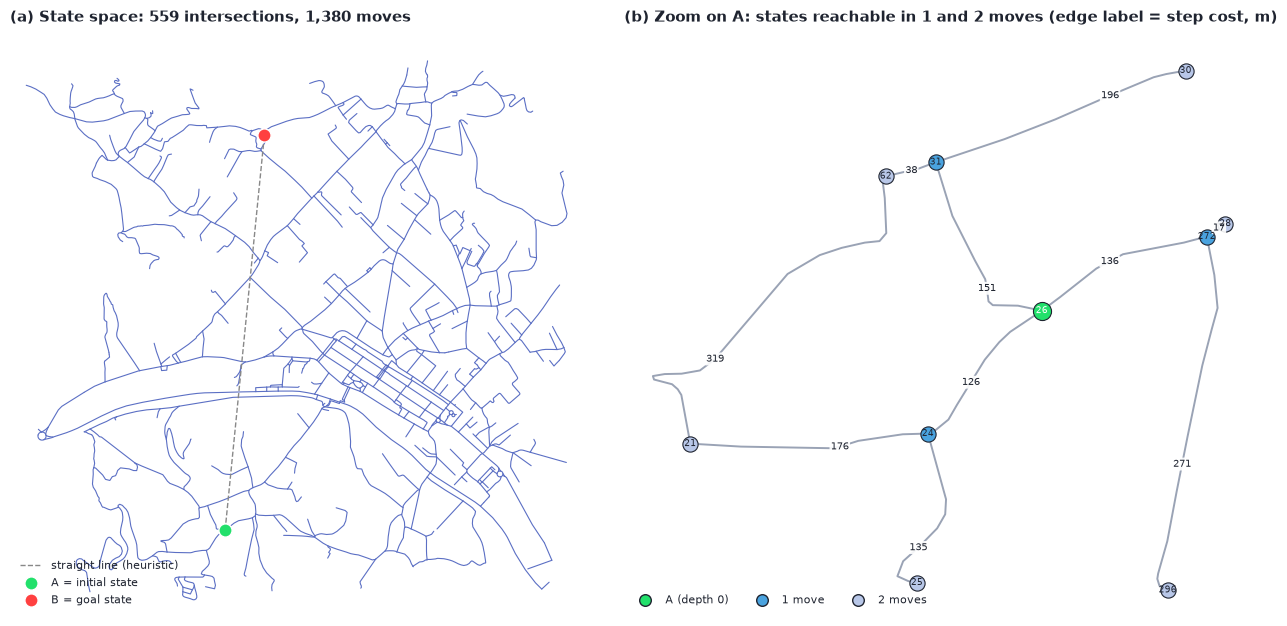

In [16]:
# Figure 1: the problem as a state-space graph. Left: all states. Right: the first two "layers" around A with step costs.
def hop_layers(problem, root, hops):
    seen, queue = {root: 0}, [root]
    for u in queue:
        if seen[u] == hops:
            continue
        for v, _ in problem.adj[u]:
            if v not in seen:
                seen[v] = seen[u] + 1
                queue.append(v)
    return seen


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.2), gridspec_kw={"width_ratios": [1, 1.05]})
fig.patch.set_facecolor("white")

# (a) the whole state space
draw_streets(ax1, range(len(PROBLEM.seg_pts)), "#5b6fc4", lw=0.8)
ax1.plot(*zip(PROBLEM.xy[SRC], PROBLEM.xy[DST]), ls="--", color="#888", lw=1, zorder=2, label="straight line (heuristic)")
ax1.scatter(*PROBLEM.xy[SRC], s=90, c=COLORS["start"], zorder=5, edgecolor="white", label="A = initial state")
ax1.scatter(*PROBLEM.xy[DST], s=90, c=COLORS["end"], zorder=5, edgecolor="white", label="B = goal state")
setup_map_axis(ax1, dark=False)
ax1.set_title(f"(a) State space: {INSTANCE['states']:,} intersections, {INSTANCE['actions']:,} moves")
ax1.legend(loc="lower left", frameon=False, fontsize=8)

# (b) zoom on A: states two moves away, each edge labelled with its step cost in metres
layers = hop_layers(PROBLEM, SRC, 2)
shades = {0: COLORS["start"], 1: "#4aa3df", 2: "#b8c7e8"}
drawn = set()
for u in layers:
    for (v, w), s in zip(PROBLEM.adj[u], PROBLEM.adj_seg[u]):
        if v in layers and (min(u, v), max(u, v)) not in drawn:
            drawn.add((min(u, v), max(u, v)))
            pts = PROBLEM.edge_pts[(u, v)]
            ax2.plot(pts[:, 0], pts[:, 1], color="#9aa3b5", lw=1.4, zorder=1)
            mid = pts[len(pts) // 2] if len(pts) % 2 else (pts[len(pts) // 2 - 1] + pts[len(pts) // 2]) / 2
            ax2.text(*mid, f"{w:.0f}", fontsize=7.5, ha="center", va="center", color=INK, zorder=4,
                     bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.9))
for u, d in layers.items():
    ax2.scatter(*PROBLEM.xy[u], s=170 if d == 0 else 120, c=shades[d], zorder=3, edgecolor=INK, linewidth=0.8)
    ax2.text(*PROBLEM.xy[u], str(u), fontsize=6.5, ha="center", va="center", color="white" if d == 0 else INK, zorder=5)
ax2.set_aspect("equal"); ax2.axis("off")
ax2.set_title("(b) Zoom on A: states reachable in 1 and 2 moves (edge label = step cost, m)")
for d, lab in [(0, "A (depth 0)"), (1, "1 move"), (2, "2 moves")]:
    ax2.scatter([], [], s=70, c=shades[d], edgecolor=INK, label=lab)
ax2.legend(loc="lower left", frameon=False, fontsize=8, ncol=3)
fig.tight_layout()
FIG_STATE = save_fig(fig, "fig01_state_space.png")
plt.show()


### 12.3 Search algorithm workflow / flowcharts
Figure 2 is Bidirectional Dijkstra (two frontiers and a meeting point), Figure 3 is A* (one frontier ordered by `f = g + h`) and Figure 4 is Hill Climbing.

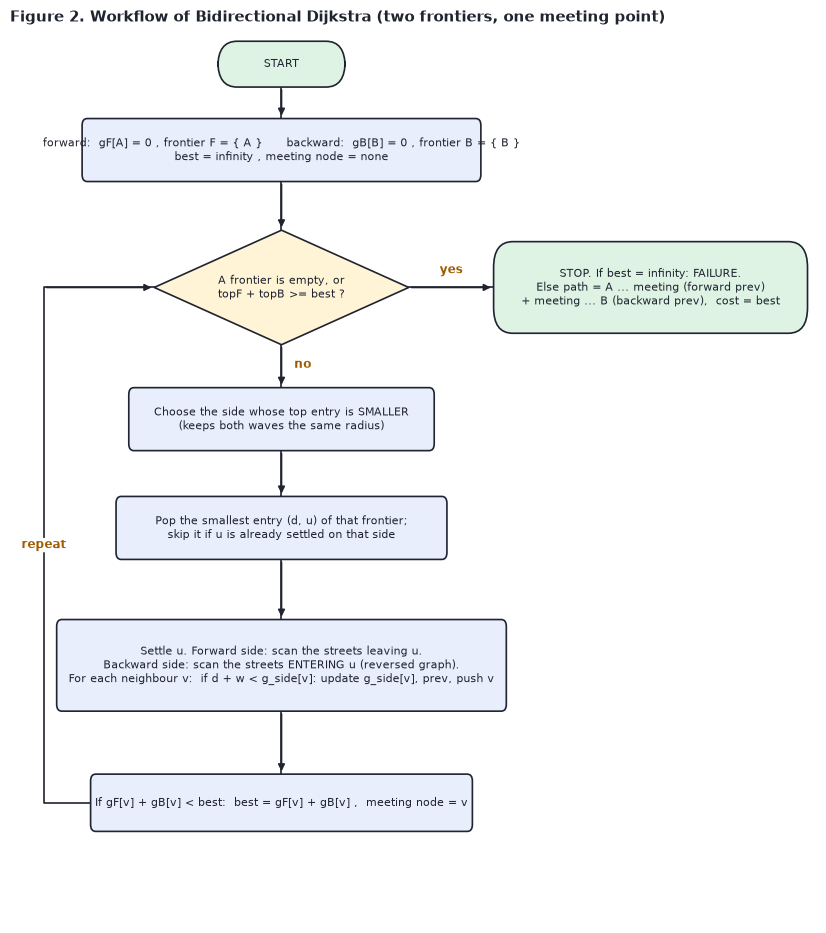

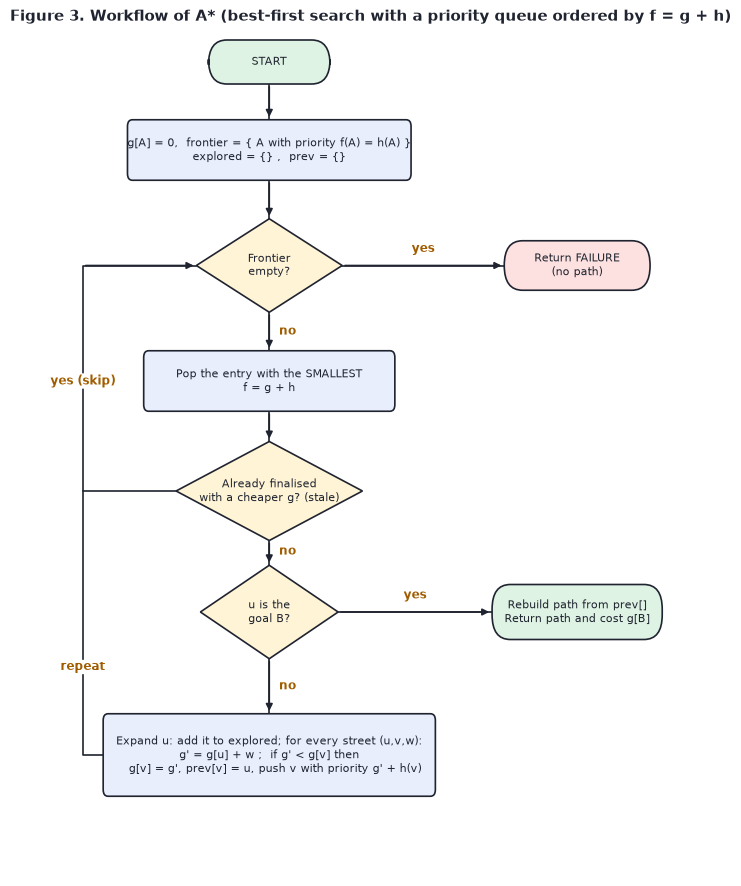

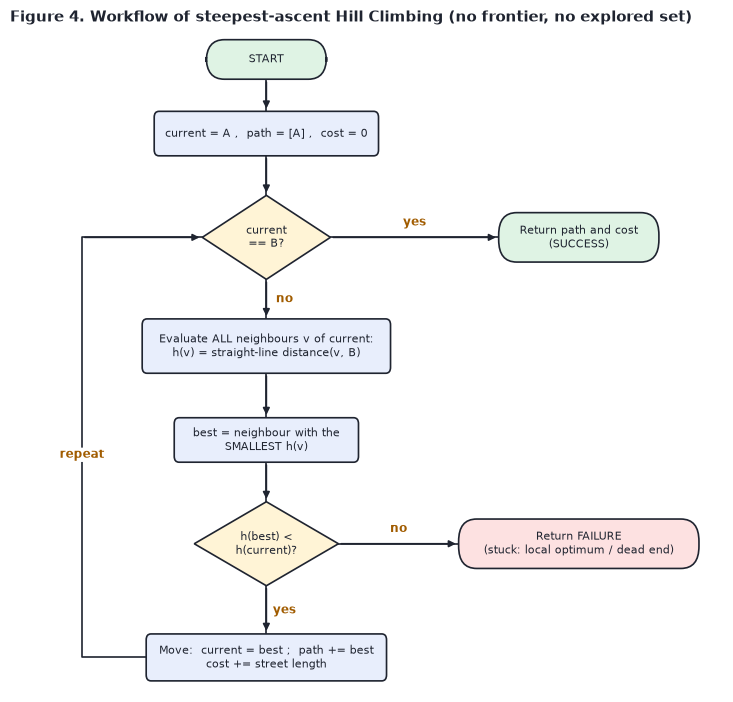

In [17]:
# Figures 2-3: workflow flowcharts (drawn with matplotlib so they live in the notebook AND as PNG files).
def fc_box(ax, x, y, text, kind="proc", w=4.6, h=1.1):
    if kind == "decision":
        ax.add_patch(Polygon([(x, y + h), (x + w / 2, y), (x, y - h), (x - w / 2, y)], closed=True,
                             fc="#fff4d6", ec=INK, lw=1.2, zorder=2))
    elif kind == "term":
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.45",
                                    fc="#dff3e4", ec=INK, lw=1.2, zorder=2))
    elif kind == "fail":
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.45",
                                    fc="#fde1e1", ec=INK, lw=1.2, zorder=2))
    else:
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.12",
                                    fc="#e8eefc", ec=INK, lw=1.2, zorder=2))
    ax.text(x, y, text, ha="center", va="center", fontsize=7.8, zorder=3)


def fc_arrow(ax, pts, label=None, lxy=None, head=True):
    xs, ys = zip(*pts)
    ax.plot(xs, ys, color=INK, lw=1.2, zorder=1)
    if head:
        ax.annotate("", xy=pts[-1], xytext=pts[-2], arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.2), zorder=1)
    if label:
        ax.text(*lxy, label, fontsize=8.5, color="#a15c00", fontweight="bold", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none"), zorder=4)


# ---------- Figure 2: Bidirectional Dijkstra ----------
fig, ax = plt.subplots(figsize=(10.4, 11.6))
ax.set_xlim(-6.4, 12.6); ax.set_ylim(1.4, 17.0); ax.axis("off")
fc_box(ax, 0, 16.4, "START", "term", w=3, h=0.8)
fc_box(ax, 0, 14.9, "forward:  gF[A] = 0 , frontier F = { A }      backward:  gB[B] = 0 , frontier B = { B }\nbest = infinity , meeting node = none", h=1.1, w=9.4)
fc_box(ax, 0, 12.5, "A frontier is empty, or\ntopF + topB >= best ?", "decision", w=6.0, h=1.0)
fc_box(ax, 0, 10.2, "Choose the side whose top entry is SMALLER\n(keeps both waves the same radius)", h=1.1, w=7.2)
fc_box(ax, 0, 8.3, "Pop the smallest entry (d, u) of that frontier;\nskip it if u is already settled on that side", h=1.1, w=7.8)
fc_box(ax, 0, 5.9, "Settle u. Forward side: scan the streets leaving u.\nBackward side: scan the streets ENTERING u (reversed graph).\nFor each neighbour v:  if d + w < g_side[v]: update g_side[v], prev, push v", h=1.6, w=10.6)
fc_box(ax, 0, 3.5, "If gF[v] + gB[v] < best:  best = gF[v] + gB[v] ,  meeting node = v", h=1.0, w=9.0)
fc_box(ax, 8.7, 12.5, "STOP. If best = infinity: FAILURE.\nElse path = A ... meeting (forward prev)\n+ meeting ... B (backward prev),  cost = best", "term", w=7.4, h=1.6)
fc_arrow(ax, [(0, 16.0), (0, 15.45)])
fc_arrow(ax, [(0, 14.35), (0, 13.5)])
fc_arrow(ax, [(0, 11.5), (0, 10.75)], "no", (0.5, 11.15))
fc_arrow(ax, [(0, 9.65), (0, 8.85)])
fc_arrow(ax, [(0, 7.75), (0, 6.7)])
fc_arrow(ax, [(0, 5.1), (0, 4.0)])
fc_arrow(ax, [(3.0, 12.5), (5.0, 12.5)], "yes", (4.0, 12.8))
fc_arrow(ax, [(-4.5, 3.5), (-5.6, 3.5), (-5.6, 12.5), (-3.0, 12.5)], "repeat", (-5.6, 8.0))
ax.set_title("Figure 2. Workflow of Bidirectional Dijkstra (two frontiers, one meeting point)", loc="left", fontsize=11)
FIG_FLOW_BI = save_fig(fig, "fig02_flowchart_bidirectional_dijkstra.png")
plt.show()

# ---------- Figure 3: A* (best-first search with f = g + h) ----------
fig, ax = plt.subplots(figsize=(9.2, 11))
ax.set_xlim(-6.4, 11.2); ax.set_ylim(1.2, 16.6); ax.axis("off")
fc_box(ax, 0, 16, "START", "term", w=3, h=0.8)
fc_box(ax, 0, 14.4, "g[A] = 0,  frontier = { A with priority f(A) = h(A) }\nexplored = {} ,  prev = {}", h=1.1, w=7.0)
fc_box(ax, 0, 12.3, "Frontier\nempty?", "decision", w=3.6, h=0.85)
fc_box(ax, 0, 10.2, "Pop the entry with the SMALLEST\nf = g + h", h=1.1, w=6.2)
fc_box(ax, 0, 8.2, "Already finalised\nwith a cheaper g? (stale)", "decision", w=4.6, h=0.9)
fc_box(ax, 0, 6.0, "u is the\ngoal B?", "decision", w=3.4, h=0.85)
fc_box(ax, 0, 3.4, "Expand u: add it to explored; for every street (u,v,w):\ng' = g[u] + w ;  if g' < g[v] then\n   g[v] = g', prev[v] = u, push v with priority g' + h(v)", h=1.5, w=8.2)
fc_box(ax, 7.6, 12.3, "Return FAILURE\n(no path)", "fail", w=3.6, h=0.9)
fc_box(ax, 7.6, 6.0, "Rebuild path from prev[]\nReturn path and cost g[B]", "term", w=4.2, h=1.0)
fc_arrow(ax, [(0, 15.6), (0, 14.95)])
fc_arrow(ax, [(0, 13.85), (0, 13.15)])
fc_arrow(ax, [(0, 11.45), (0, 10.75)], "no", (0.45, 11.1))
fc_arrow(ax, [(0, 9.65), (0, 9.1)])
fc_arrow(ax, [(0, 7.3), (0, 6.85)], "no", (0.45, 7.1))
fc_arrow(ax, [(0, 5.15), (0, 4.15)], "no", (0.45, 4.65))
fc_arrow(ax, [(1.8, 12.3), (5.8, 12.3)], "yes", (3.8, 12.6))
fc_arrow(ax, [(1.7, 6.0), (5.5, 6.0)], "yes", (3.6, 6.3))
fc_arrow(ax, [(-2.3, 8.2), (-4.6, 8.2), (-4.6, 12.3), (-1.8, 12.3)], "yes (skip)", (-4.6, 10.2))
fc_arrow(ax, [(-4.1, 3.4), (-4.6, 3.4), (-4.6, 8.2)], "repeat", (-4.6, 5.0), head=False)
ax.set_title("Figure 3. Workflow of A* (best-first search with a priority queue ordered by f = g + h)", loc="left", fontsize=11)
FIG_FLOW_ASTAR = save_fig(fig, "fig03_flowchart_astar.png")
plt.show()

# ---------- Figure 4: Hill climbing ----------
fig, ax = plt.subplots(figsize=(9.2, 8.6))
ax.set_xlim(-6.4, 11.4); ax.set_ylim(1.2, 14.6); ax.axis("off")
fc_box(ax, 0, 14, "START", "term", w=3, h=0.8)
fc_box(ax, 0, 12.5, "current = A ,  path = [A] ,  cost = 0", h=0.9, w=5.6)
fc_box(ax, 0, 10.4, "current\n== B?", "decision", w=3.2, h=0.85)
fc_box(ax, 0, 8.2, "Evaluate ALL neighbours v of current:\nh(v) = straight-line distance(v, B)", h=1.1, w=6.2)
fc_box(ax, 0, 6.3, "best = neighbour with the\nSMALLEST h(v)", h=0.9)
fc_box(ax, 0, 4.2, "h(best) <\nh(current)?", "decision", w=3.6, h=0.85)
fc_box(ax, 0, 1.9, "Move:  current = best ;  path += best\ncost += street length", h=0.95, w=6.0)
fc_box(ax, 7.8, 10.4, "Return path and cost\n(SUCCESS)", "term", w=4.0, h=1.0)
fc_box(ax, 7.8, 4.2, "Return FAILURE\n(stuck: local optimum / dead end)", "fail", w=6.0, h=1.0)
fc_arrow(ax, [(0, 13.6), (0, 12.95)])
fc_arrow(ax, [(0, 12.05), (0, 11.25)])
fc_arrow(ax, [(0, 9.55), (0, 8.75)], "no", (0.45, 9.15))
fc_arrow(ax, [(0, 7.65), (0, 6.75)])
fc_arrow(ax, [(0, 5.85), (0, 5.05)])
fc_arrow(ax, [(0, 3.35), (0, 2.38)], "yes", (0.45, 2.85))
fc_arrow(ax, [(1.6, 10.4), (5.8, 10.4)], "yes", (3.7, 10.7))
fc_arrow(ax, [(1.8, 4.2), (4.8, 4.2)], "no", (3.3, 4.5))
fc_arrow(ax, [(-3.0, 1.9), (-4.6, 1.9), (-4.6, 10.4), (-1.6, 10.4)], "repeat", (-4.6, 6.0))
ax.set_title("Figure 4. Workflow of steepest-ascent Hill Climbing (no frontier, no explored set)", loc="left", fontsize=11)
FIG_FLOW_HC = save_fig(fig, "fig04_flowchart_hill_climbing.png")
plt.show()


### 12.4 Search tree / state-space graph
Figure 5 expands the search tree of A* from A for three levels with the real `g`, `h`, `f` values and the order in which A* actually expanded those nodes. Figure 6 draws the complete search trees on the map: Bidirectional Dijkstra grows **two** trees (blue from A, purple from B), A* grows one.

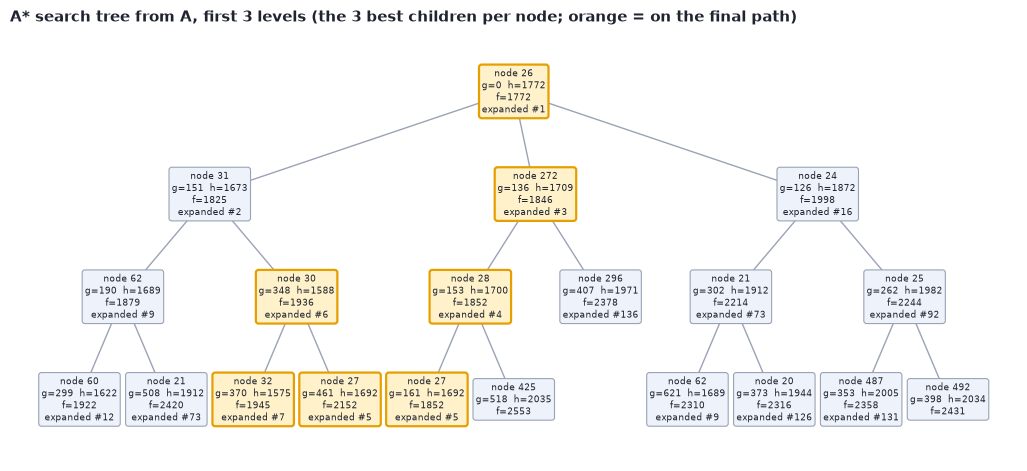

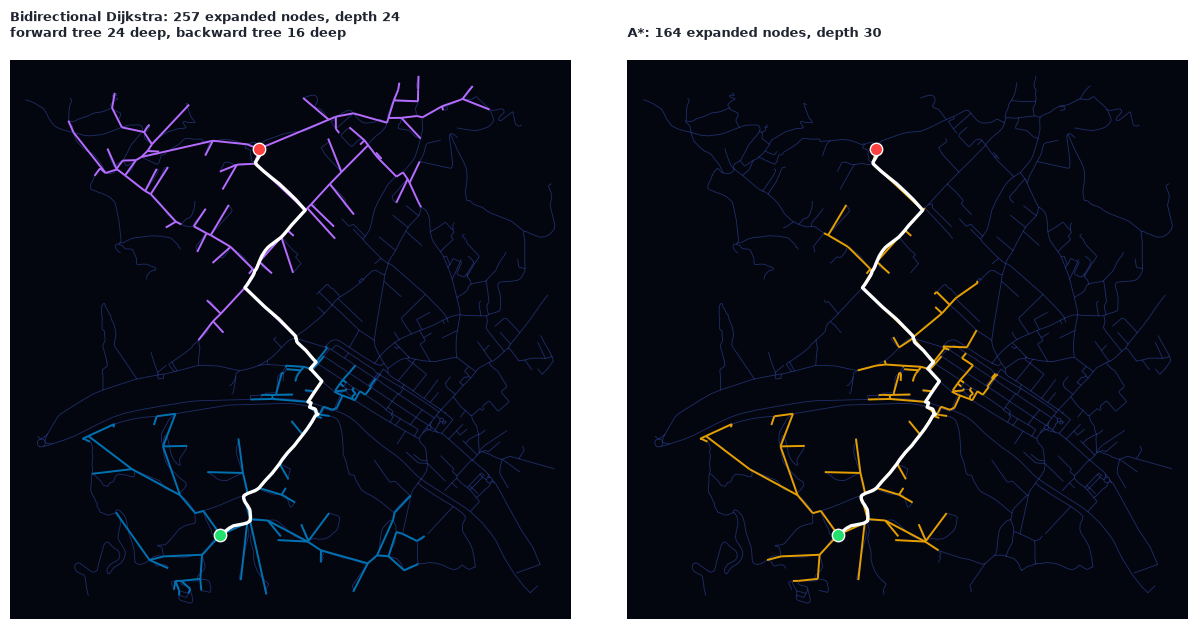

In [18]:
# Figure 5: a depth-limited slice of the A* search tree from A (labels: g, h, f).  Figure 6: the real search trees on the map.
_order = {}
for _k, (_node, _segs, _side) in enumerate(RUNS["A*"]["trace"].events, 1):
    _order.setdefault(_node, _k)
_final_path = set(RUNS["A*"]["result"].path)
MAX_DEPTH, MAX_CHILDREN = 3, 3


def build_tree(node, parent, g, depth, ancestors):
    f = g + H_TARGET[node]
    entry = {"node": node, "g": g, "f": f, "depth": depth, "children": []}
    if depth < MAX_DEPTH:
        kids = [(g + w + H_TARGET[v], v, w) for v, w in PROBLEM.adj[node] if v != parent and v not in ancestors]
        for _, v, w in sorted(kids)[:MAX_CHILDREN]:
            entry["children"].append(build_tree(v, node, g + w, depth + 1, ancestors | {node}))
    return entry


TREE = build_tree(SRC, -1, 0.0, 0, frozenset())
_leaf_x = [0]


def layout(t):
    if not t["children"]:
        t["x"] = _leaf_x[0]; _leaf_x[0] += 1
    else:
        for c in t["children"]:
            layout(c)
        t["x"] = (t["children"][0]["x"] + t["children"][-1]["x"]) / 2


layout(TREE)
fig, ax = plt.subplots(figsize=(13, 5.6))


def draw_tree(t):
    for c in t["children"]:
        ax.plot([t["x"], c["x"]], [-t["depth"], -c["depth"]], color="#9aa3b5", lw=1, zorder=1)
        draw_tree(c)
    on_path = t["node"] in _final_path
    k = _order.get(t["node"])
    label = f"node {t['node']}\ng={t['g']:.0f}  h={H_TARGET[t['node']]:.0f}\nf={t['f']:.0f}" + (f"\nexpanded #{k}" if k else "")
    ax.text(t["x"], -t["depth"], label, ha="center", va="center", fontsize=6.6, zorder=3,
            bbox=dict(boxstyle="round,pad=0.3", fc="#fff1c9" if on_path else "#eef2fb",
                      ec=ALGO_COLORS["A*"] if on_path else "#9aa3b5", lw=1.6 if on_path else 0.8))


draw_tree(TREE)
ax.set_xlim(-0.8, _leaf_x[0] - 0.2); ax.set_ylim(-MAX_DEPTH - 0.6, 0.6); ax.axis("off")
ax.set_title(f"A* search tree from A, first {MAX_DEPTH} levels (the {MAX_CHILDREN} best children per node; orange = on the final path)")
FIG_TREE = save_fig(fig, "fig05_search_tree_abstract.png")
plt.show()

# Search tree on the map: edge (parent -> child) for every expanded node.
# Bidirectional Dijkstra has TWO trees: one grown from A (forward wave) and one grown from B (backward wave).
def tree_edges(res, trace):
    prevs = res.prev if isinstance(res.prev, tuple) else (res.prev, None)
    lines, depth = ([], []), ({SRC: 0}, {DST: 0})
    for v, _, side in trace.events:
        p = prevs[side][v]
        if p >= 0:
            lines[side].append(np.vstack([PROBLEM.xy[p], PROBLEM.xy[v]]))
            depth[side][v] = depth[side].get(p, 0) + 1
    return lines, depth


TREE_STATS = {}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.2))
fig.patch.set_facecolor("white")
for ax, name in zip(axes, ["Bidirectional Dijkstra", "A*"]):
    res, tr = RUNS[name]["result"], RUNS[name]["trace"]
    lines, depth = tree_edges(res, tr)
    TREE_STATS[name] = {"tree_nodes": len(tr.events), "tree_depth": max(max(d.values()) for d in depth),
                        "fwd_nodes": sum(e[2] == 0 for e in tr.events), "bwd_nodes": sum(e[2] == 1 for e in tr.events),
                        "fwd_depth": max(depth[0].values()), "bwd_depth": max(depth[1].values()) if lines[1] else 0}
    draw_streets(ax, range(len(PROBLEM.seg_pts)), MAP_BASE, lw=0.6, alpha=0.7)
    ax.add_collection(LineCollection(lines[0], colors=ALGO_COLORS[name], linewidths=1.4, zorder=2))
    if lines[1]:
        ax.add_collection(LineCollection(lines[1], colors=BI_COLOR_BACK, linewidths=1.4, zorder=2))
    pxy = path_xy(res)
    ax.plot(pxy[:, 0], pxy[:, 1], color="white", lw=2.4, zorder=3)
    ax.scatter(*PROBLEM.xy[SRC], s=80, c=COLORS["start"], zorder=5, edgecolor="white")
    ax.scatter(*PROBLEM.xy[DST], s=80, c=COLORS["end"], zorder=5, edgecolor="white")
    setup_map_axis(ax, dark=True)
    extra = (f" (forward tree {TREE_STATS[name]['fwd_depth']} deep, backward tree {TREE_STATS[name]['bwd_depth']} deep)"
             if lines[1] else "")
    ax.set_title(f"{name}: {len(tr.events)} expanded nodes, depth {TREE_STATS[name]['tree_depth']}" + ("\n" + extra.strip(" ()") if extra else ""),
                 color=INK, loc="left", fontsize=9.5)
fig.tight_layout()
FIG_TREE_MAP = save_fig(fig, "fig06_search_tree_map.png")
plt.show()


### Algorithm-specific design and pseudocode
**Bidirectional Dijkstra: two Dijkstra waves, one from A over the streets and one from B over the reversed streets**
```text
BIDIRECTIONAL_DIJKSTRA(graph, A, B):
    gF[A] <- 0 ; gB[B] <- 0 ; all other distances <- infinity
    frontierF <- min-priority-queue { (0, A) }          # forward wave, follows streets
    frontierB <- min-priority-queue { (0, B) }          # backward wave, follows streets in reverse
    best <- infinity ; meeting <- none
    while frontierF and frontierB are not empty:
        if top(frontierF) + top(frontierB) >= best: break          # the waves have met, best is optimal
        side <- the frontier whose top entry is smaller             # keeps both waves the same radius
        (d, u) <- side.pop_min()
        if u is already settled on this side: continue              # stale entry
        settle u on this side
        for each neighbour v of u (forward: streets leaving u, backward: streets entering u) with length w:
            if d + w < g_side[v]:
                g_side[v] <- d + w ; prev_side[v] <- u ; side.push((d + w, v))
            if gF[v] + gB[v] < best:                                # a route A -> v -> B exists
                best <- gF[v] + gB[v] ; meeting <- v
    if meeting = none: return FAILURE
    return (A ... meeting via prevF) + (meeting ... B via prevB), best
```
**A\* : one best-first search ordered by f = g + h**
```text
ASTAR(graph, A, B):
    h(x) <- straight_line_distance(x, B)                # admissible heuristic
    g[A] <- 0 ; prev <- {}
    frontier <- min-priority-queue { (h(A), A) }        # ordered by f = g + h
    while frontier is not empty:
        (f, u) <- frontier.pop_min()
        if this entry is stale (g at push time > g[u]): continue
        if u = B: return RECONSTRUCT(prev, B), g[B]
        for each street (u, v) with length w:
            if g[u] + w < g[v]:                         # a closed node can be re-opened here
                g[v] <- g[u] + w ; prev[v] <- u
                frontier.push((g[v] + h(v), v))
    return FAILURE
```
**Hill Climbing (steepest ascent): always step to the neighbour closest to B**
```text
HILL_CLIMBING(graph, A, B):
    current <- A ; path <- [A]
    loop:
        if current = B: return path, SUCCESS
        best <- the neighbour v of current with the smallest h(v)
        if h(best) >= h(current): return path, FAILURE  # local optimum: no neighbour is better
        current <- best ; path.append(best)
```
| | Bidirectional Dijkstra | A* | Hill Climbing |
|---|---|---|---|
| Strategy | cheapest `g` first, from both ends, stop when the waves meet | cheapest `g + h` first | greedy on `h`, one state |
| Needs the goal known in advance | yes (starts a wave there) | yes | yes |
| Needs a heuristic | no | yes | yes |
| Complete | yes | yes | **no** (local optima) |
| Optimal | yes | yes (admissible `h`) | **no** |
| Time | O((V+E) log V), two searches of about half the radius | O((V+E) log V), usually far fewer nodes | O(b d) |
| Space | O(V) (two sets of arrays) | O(V) | O(1) extra |

### Frontier and explored-set representation
| | Bidirectional Dijkstra | A* | Hill Climbing |
|---|---|---|---|
| **Frontier** | **two** binary min-heaps (`heapq`) of `(g, node)`: forward from A, backward from B | one binary min-heap of `(f, g, node)` | none: only the single `current` node |
| **Priority** | `g(n)` = distance from the wave's own root | `f(n) = g(n) + h(n)` | `h(n)` of the neighbours (chosen greedily) |
| **Explored set** | one *settled* set per wave (the `done` flags); stale heap entries are skipped (lazy deletion) | `explored` = nodes popped & expanded; a node may be re-opened if a cheaper `g` appears | not kept (it cannot revisit a node anyway, `h` must strictly decrease) |
| **Bookkeeping** | `dist`/`prev` arrays for each wave (size V each), `best` cost and `meeting` node; the backward wave uses the **reversed adjacency** `radj` | `g[]`, `prev[]`, `h[]` (size V) | `path` list only |
| **Stop rule** | `top(F) + top(B) >= best` | goal popped from the heap | goal reached, or no better neighbour |

The tables below replay the first expansions and show exactly what the frontiers and explored sets contain.


Bidirectional Dijkstra: first expansion steps


,side,expand node,dist from its root m,frontier size (fwd + bwd),explored (fwd + bwd),best A-B cost so far m,next in this frontier (node:dist)
step,,,,,,,
1,forward,26,0.0,0 + 1,1 + 0,-,
2,backward,165,0.0,3 + 0,1 + 1,-,
3,backward,162,67.4,3 + 2,1 + 2,-,"164:73, 166:359"
4,backward,164,73.5,3 + 2,1 + 3,-,"163:74, 166:359"
5,backward,163,74.5,3 + 2,1 + 4,-,"436:234, 166:359"
6,forward,24,126.1,2 + 4,2 + 4,-,"272:136, 31:151"



A*: first expansion steps


,expand node,g m,h m,f m,frontier size,explored set size,next best in frontier (node:f)
step,,,,,,,
1,26,0.0,1772.1,1772.1,0,1,
2,31,151.5,1673.1,1824.6,2,2,"272:1846, 24:1998"
3,272,136.2,1709.5,1845.7,3,3,"62:1879, 30:1936, 24:1998"
4,28,152.8,1699.6,1852.4,4,4,"62:1879, 30:1936, 24:1998"
5,27,160.9,1691.6,1852.5,5,5,"62:1879, 30:1936, 24:1998"
6,30,273.6,1587.7,1861.3,6,6,"62:1879, 30:1936, 29:1940"



Hill Climbing: first expansion steps


,expand node,h(node) m,frontier,explored set size,neighbour h (m),decision
step,,,,,,
1,26,1772.1,- (single current state),1,"31:1673, 272:1709, 24:1872",move to 31
2,31,1673.1,- (single current state),1,"30:1588, 62:1689, 26:1772",move to 30
3,30,1587.7,- (single current state),1,"32:1575, 31:1673, 27:1692",move to 32
4,32,1574.8,- (single current state),1,"34:1482, 33:1549, 30:1588",move to 34
5,34,1482.3,- (single current state),1,"431:1327, 430:1495, 32:1575",move to 431
6,431,1326.9,- (single current state),1,34:1482,STOP (local optimum)


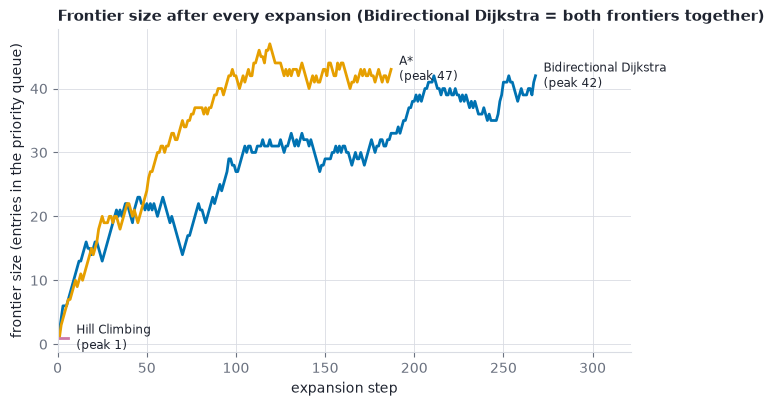

In [19]:
# Frontier / explored-set representation: replay each algorithm and record what the data structures contain.
def profile_search(problem, src, dst, name, snapshot_steps=6):
    """Return (per-step table rows for the first steps, frontier size after every expansion)."""
    n = len(problem.adj)
    rows, sizes = [], []
    if name == "Hill Climbing":
        h = H_TARGET
        current, explored = src, []
        for step in range(1, 10_000):
            nbrs = sorted(((h[v], v) for v, _ in problem.adj[current]))
            better = [(hv, v) for hv, v in nbrs if hv < h[current]]
            explored.append(current)
            sizes.append(1)
            if step <= snapshot_steps:
                rows.append({"step": step, "expand node": current, "h(node) m": round(h[current], 1),
                             "frontier": "- (single current state)", "explored set size": 1,
                             "neighbour h (m)": ", ".join(f"{v}:{hv:.0f}" for hv, v in nbrs[:4]),
                             "decision": f"move to {better[0][1]}" if better else "STOP (local optimum)"})
            if current == dst or not better:
                break
            current = better[0][1]
        return rows, sizes
    if name == "Bidirectional Dijkstra":
        adjs = (problem.adj, problem.radj)
        dist = ([math.inf] * n, [math.inf] * n)
        dist[0][src] = dist[1][dst] = 0.0
        heaps, explored, best = ([(0.0, src)], [(0.0, dst)]), (set(), set()), math.inf
        step = 0
        while heaps[0] and heaps[1]:
            if heaps[0][0][0] + heaps[1][0][0] >= best:
                break
            side = 0 if heaps[0][0][0] <= heaps[1][0][0] else 1
            sizes.append(len(heaps[0]) + len(heaps[1]))
            d, u = heapq.heappop(heaps[side])
            if u in explored[side]:
                continue
            step += 1
            explored[side].add(u)
            if step <= snapshot_steps:
                top = heapq.nsmallest(3, heaps[side])
                rows.append({"step": step, "side": "forward" if side == 0 else "backward", "expand node": u,
                             "dist from its root m": round(d, 1),
                             "frontier size (fwd + bwd)": f"{len(heaps[0])} + {len(heaps[1])}",
                             "explored (fwd + bwd)": f"{len(explored[0])} + {len(explored[1])}",
                             "best A-B cost so far m": round(best, 1) if best < math.inf else "-",
                             "next in this frontier (node:dist)": ", ".join(f"{v}:{dd:.0f}" for dd, v in top)})
            for v, w in adjs[side][u]:
                if d + w < dist[side][v]:
                    dist[side][v] = d + w
                    heapq.heappush(heaps[side], (d + w, v))
                best = min(best, dist[side][v] + dist[1 - side][v])
        return rows, sizes
    h = H_TARGET
    g = [math.inf] * n
    g[src] = 0.0
    heap, explored = [(h[src], 0.0, src)], set()
    step = 0
    while heap:
        sizes.append(len(heap))
        f, gu, u = heapq.heappop(heap)
        if gu > g[u]:
            continue
        step += 1
        explored.add(u)
        if step <= snapshot_steps:
            top = heapq.nsmallest(3, heap)
            rows.append({"step": step, "expand node": u, "g m": round(gu, 1), "h m": round(h[u], 1), "f m": round(f, 1),
                         "frontier size": len(heap), "explored set size": len(explored),
                         "next best in frontier (node:f)": ", ".join(f"{v}:{ff:.0f}" for ff, _, v in top)})
        if u == dst:
            break
        for v, w in problem.adj[u]:
            if gu + w < g[v]:
                g[v] = gu + w
                heapq.heappush(heap, (g[v] + h[v], g[v], v))
    return rows, sizes


FRONTIER_ROWS, FRONTIER_SIZES = {}, {}
for _name in COMPARE_ALGORITHMS:
    FRONTIER_ROWS[_name], FRONTIER_SIZES[_name] = profile_search(PROBLEM, SRC, DST, _name)
    print(f"\n{_name}: first expansion steps")
    display(pd.DataFrame(FRONTIER_ROWS[_name]).set_index("step"))

fig, ax = plt.subplots(figsize=(7.4, 4.2))
for _name in COMPARE_ALGORITHMS:
    ys = FRONTIER_SIZES[_name]
    ax.plot(range(1, len(ys) + 1), ys, color=ALGO_COLORS[_name], lw=2)
    ax.text(len(ys), ys[-1], f"  {_name}\n  (peak {max(ys)})", color=INK, fontsize=8.5, va="center")
ax.set_xlabel("expansion step"); ax.set_ylabel("frontier size (entries in the priority queue)")
ax.set_title("Frontier size after every expansion (Bidirectional Dijkstra = both frontiers together)")
ax.set_xlim(0, max(len(v) for v in FRONTIER_SIZES.values()) * 1.2)
ax.grid(color=GRID, lw=0.6)
FIG_FRONTIER = save_fig(fig, "fig07_frontier_growth.png")
plt.show()


### Heuristic function design
* **Function:** `h(n)` = straight-line (Euclidean) distance in metres between intersection `n` and the goal B, computed on the projected (UTM, metre) coordinates of the map. It is used by **A\*** (inside `f = g + h`) and by **Hill Climbing** (as its only guide). **Bidirectional Dijkstra is uninformed and does not use `h`**; it gets its speed-up from searching from both ends instead.
* **Why it is a good choice:** a street can never be shorter than the straight line between its two ends, so the true remaining cost `h*(n)` is always at least `h(n)`. That makes `h` **admissible** (never overestimates), which guarantees A* returns an optimal path. It is also cheap: one subtraction and one square root per node.
* **Consistency:** `h(u) <= w(u,v) + h(v)` holds on (almost) every edge (the triangle inequality). The few tiny violations measured below come from map-projection distortion (centimetres); A* is implemented so it stays optimal even then.
* **Relationship between the algorithms:** with `h = 0`, A* would turn into plain one-sided Dijkstra; Hill Climbing uses the same `h` but only as a local compass (it never looks at `g`).
* **Weakness:** the straight line ignores walls, rivers and one-way detours, so `h` is sometimes much smaller than `h*` in a medieval centre like Lucca. Hill Climbing is fooled by exactly those places.

Admissible  (h(n) <= h*(n) for every node)?  violations: 0 of 559 nodes   | max h/h* = 0.965
Informedness: on average h is 70% of the true remaining distance h*
Consistent  (h(u) <= cost(u,v) + h(v))?       violations: 2 of 1,380 edges (largest excess 6.90 cm, caused by map-projection distortion)
A* in this notebook allows re-opening a closed node, so it stays optimal even with such tiny inconsistencies.


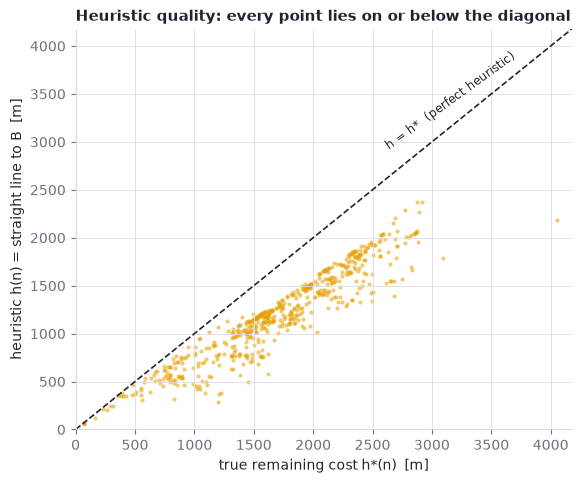

In [20]:
# Heuristic design: h(n) = straight-line distance to B.  Is it admissible / consistent on THIS graph?
_n = len(PROBLEM.adj)
_radj = [[] for _ in range(_n)]
for _u in range(_n):
    for _v, _w in PROBLEM.adj[_u]:
        _radj[_v].append((_u, _w))
H_STAR = [math.inf] * _n                      # true remaining cost h*(n): Dijkstra from B on the reversed graph (the same idea as the backward wave)
H_STAR[DST] = 0.0
_pq = [(0.0, DST)]
while _pq:
    _d, _u = heapq.heappop(_pq)
    if _d > H_STAR[_u]:
        continue
    for _v, _w in _radj[_u]:
        if _d + _w < H_STAR[_v]:
            H_STAR[_v] = _d + _w
            heapq.heappush(_pq, (_d + _w, _v))

_h, _hs = np.array(H_TARGET), np.array(H_STAR)
_mask = _hs > 0
_ratio = _h[_mask] / _hs[_mask]
_viol = [(_h[u] - (w + _h[v])) for u in range(_n) for v, w in PROBLEM.adj[u] if _h[u] > w + _h[v] + 1e-9]
HEUR = {
    "admissible_violations": int((_h > _hs + 1e-9).sum()),
    "max_ratio": float(_ratio.max()), "mean_ratio": float(_ratio.mean()),
    "consistency_violations": len(_viol), "edges": INSTANCE["actions"],
    "max_consistency_excess_m": float(max(_viol)) if _viol else 0.0,
}
print(f"Admissible  (h(n) <= h*(n) for every node)?  violations: {HEUR['admissible_violations']} of {_n:,} nodes   "
      f"| max h/h* = {HEUR['max_ratio']:.3f}")
print(f"Informedness: on average h is {HEUR['mean_ratio']:.0%} of the true remaining distance h*")
print(f"Consistent  (h(u) <= cost(u,v) + h(v))?       violations: {HEUR['consistency_violations']} of {HEUR['edges']:,} edges "
      f"(largest excess {HEUR['max_consistency_excess_m'] * 100:.2f} cm, caused by map-projection distortion)")
print("A* in this notebook allows re-opening a closed node, so it stays optimal even with such tiny inconsistencies.")

fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.scatter(_hs[_mask], _h[_mask], s=9, color=ALGO_COLORS["A*"], alpha=0.55, linewidths=0, label="intersections")
_lim = max(_hs[_mask].max(), _h.max()) * 1.03
ax.plot([0, _lim], [0, _lim], color=INK, lw=1.2, ls="--")
ax.text(_lim * 0.62, _lim * 0.70, "h = h*  (perfect heuristic)", rotation=36, color=INK, fontsize=8.5)
ax.set_xlim(0, _lim); ax.set_ylim(0, _lim)
ax.set_xlabel("true remaining cost h*(n)  [m]"); ax.set_ylabel("heuristic h(n) = straight line to B  [m]")
ax.set_title("Heuristic quality: every point lies on or below the diagonal")
ax.grid(color=GRID, lw=0.6)
FIG_HEUR = save_fig(fig, "fig08_heuristic.png")
plt.show()


## 13. Lab Report, Part B: Implementation
The algorithms themselves are in sections 5, 5b and 5c; this part documents the data pipeline and shows the key code.

### Dataset loading and preprocessing
This project has no tabular dataset: the data is a **street network from OpenStreetMap**, loaded and prepared by the notebook:

1. `load_graph`: geocode `PLACE` to a polygon (or fall back to a radius around it), download the walkable street network with OSMnx, shrink the area until it has at most `MAX_NODES` nodes, and cache it in `osm_cache/` so reruns are offline and instant.
2. `clean_graph`: project to the local UTM zone (metres), drop self-loops, keep the largest strongly-connected component (so every pair of nodes is mutually reachable), repair missing edge lengths.
3. `pick_endpoints`: pick A and B with a seeded RNG, far enough apart, and confirm a route exists.
4. `build_problem`: convert the graph to compact adjacency lists (`adj`, node coordinates `xy`, drawable segments) that every algorithm and renderer shares.

Resulting dataset:

In [21]:
# Dataset loading + preprocessing summary: OSM download -> cleaned graph -> compact SearchProblem.
_total_len_km = sum(w for adj in PROBLEM.adj for _, w in adj) / 2 / 1000
DATASET = {
    "place": PLACE, "network_type": NETWORK_TYPE, "source": FETCH_METHOD, "crs": str(G.graph.get("crs")),
    "raw_nodes": G_raw.number_of_nodes(), "raw_edges": G_raw.number_of_edges(),
    "clean_nodes": G.number_of_nodes(), "clean_edges": G.number_of_edges(),
    "directed_edges": INSTANCE["actions"], "segments": len(PROBLEM.seg_uv),
    "total_street_km": _total_len_km, "avg_edge_m": INSTANCE["actions"] and sum(w for a in PROBLEM.adj for _, w in a) / INSTANCE["actions"],
    "diag_m": AB_INFO["diag_m"],
}
_rows = [
    ("Place / network", f"{PLACE} / {NETWORK_TYPE}"),
    ("Data source", FETCH_METHOD),
    ("Raw OSM graph", f"{DATASET['raw_nodes']:,} nodes, {DATASET['raw_edges']:,} edges"),
    ("After cleaning (self-loops removed, largest strongly-connected component)",
     f"{DATASET['clean_nodes']:,} nodes, {DATASET['clean_edges']:,} edges"),
    ("Projected CRS (metres)", DATASET["crs"]),
    ("Search problem (parallel edges merged)", f"{DATASET['directed_edges']:,} directed moves, {DATASET['segments']:,} drawable street segments"),
    ("Total street length", f"{DATASET['total_street_km']:.1f} km (mean move {DATASET['avg_edge_m']:.1f} m)"),
    ("Map diagonal", f"{DATASET['diag_m']:,.0f} m"),
    ("Start / goal (seed %d)" % SEED, f"OSM {A_NODE} -> OSM {B_NODE}, {AB_INFO['straight_m']:,.0f} m apart in a straight line"),
]
display(pd.DataFrame(_rows, columns=["Item", "Value"]).set_index("Item"))


,Value
Item,
Place / network,"Centro Storico, Lucca, Italy / walk"
Data source,"address + 1,200 m radius [loaded from local ca..."
Raw OSM graph,"559 nodes, 1,408 edges"
"After cleaning (self-loops removed, largest strongly-connected component)","559 nodes, 1,404 edges"
Projected CRS (metres),EPSG:32632
Search problem (parallel edges merged),"1,380 directed moves, 690 drawable street segm..."
Total street length,58.3 km (mean move 84.5 m)
Map diagonal,"3,385 m"
Start / goal (seed 42),"OSM 620893001 -> OSM 402980103, 1,772 m apart ..."


### Model implementation and training
**Not applicable.** Bidirectional Dijkstra, A* and Hill Climbing are classical search algorithms: they have no learned parameters, so there is no training set, loss function or training loop. The "model" is the **problem model** (the state-space graph built above, including its reversed copy for the backward search) plus the hand-designed heuristic `h`. The algorithms are implemented from scratch with `heapq` and verified against `networkx.shortest_path_length` (see section 7).

### Prediction generation
For a search algorithm the "prediction" is the **solution path** it returns for the pair (A, B): the sequence of intersections, its length in metres and its number of steps. Bidirectional Dijkstra and A* are validated to equal the true shortest path; Hill Climbing returns either a path to B or the partial walk where it got stuck. Paths of this run:

### Code snippets for key functionalities
Pulled live from the functions defined in this notebook.

In [22]:
# Key code snippets, pulled live from the functions defined above (so they can never go stale).
def _src(fn):
    try:
        return inspect.getsource(fn).rstrip()
    except (OSError, TypeError):
        return f"# source of {fn.__name__} is not available in this environment (see the notebook cell)"


_SNIP = [
    ("Preprocessing - clean the raw OSM graph", clean_graph),
    ("Building the search problem (adjacency lists, coordinates)", build_problem),
    ("Bidirectional Dijkstra", bidirectional_dijkstra),
    ("Heuristic function", euclidean_heuristic),
    ("A*", astar),
    ("Hill Climbing", hill_climbing),
]
SNIPPETS_MD = "\n\n".join(f"#### {title}\n\n```python\n{_src(fn)}\n```" for title, fn in _SNIP)
display(Markdown(SNIPPETS_MD))


#### Preprocessing - clean the raw OSM graph

```python
def clean_graph(G_raw, network_type, log=print):
    """Project to metres, drop self-loops, keep the largest strongly connected component,
    and make sure every edge has a usable 'length' (metres)."""
    if G_raw.number_of_nodes() == 0:
        raise PipelineError(f"The downloaded graph is empty. {_advice(network_type)}")
    G = ox.project_graph(G_raw)                                   # local UTM zone, metres
    loops = list(nx.selfloop_edges(G, keys=True))
    G.remove_edges_from(loops)
    G = ox.truncate.largest_component(G, strongly=True)
    filled = 0
    for u, v, k, d in G.edges(keys=True, data=True):
        try:
            length = float(d.get("length"))
        except (TypeError, ValueError):
            length = float("nan")
        if not math.isfinite(length) or length < 0:
            geom = d.get("geometry")
            length = float(geom.length) if geom is not None else math.dist(
                (G.nodes[u]["x"], G.nodes[u]["y"]), (G.nodes[v]["x"], G.nodes[v]["y"]))
            filled += 1
        d["length"] = length
    if G.number_of_nodes() < 2 or G.number_of_edges() == 0:
        raise PipelineError(f"No usable roads: the largest strongly connected component has "
                            f"{G.number_of_nodes()} node(s). {_advice(network_type)}")
    log(f"  Cleaned graph: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges "
        f"(removed {len(loops)} self-loops, filled {filled} missing lengths, CRS {G.graph['crs']})")
    return G
```

#### Building the search problem (adjacency lists, coordinates)

```python
def build_problem(G) -> SearchProblem:
    """Convert the cleaned networkx MultiDiGraph into compact adjacency lists."""
    node_ids = list(G.nodes)
    index = {n: i for i, n in enumerate(node_ids)}
    xy = np.array([(G.nodes[n]["x"], G.nodes[n]["y"]) for n in node_ids], dtype=float)

    best = {}                                      # (u, v) -> (length, data): keep shortest parallel edge
    for u, v, d in G.edges(data=True):
        key = (index[u], index[v])
        if key not in best or d["length"] < best[key][0]:
            best[key] = (d["length"], d)

    adj = [[] for _ in node_ids]
    adj_seg = [[] for _ in node_ids]
    seg_of, seg_uv, seg_pts, seg_len, edge_pts = {}, [], [], [], {}
    for (ui, vi), (length, d) in best.items():
        pts = _edge_points(d, xy[ui], xy[vi])
        edge_pts[(ui, vi)] = pts
        und = (ui, vi) if ui < vi else (vi, ui)
        oriented = pts if ui == und[0] else pts[::-1]
        if und not in seg_of:                      # first time we see this street piece
            seg_of[und] = len(seg_uv)
            seg_uv.append(und)
            seg_pts.append(oriented)
            seg_len.append(length)
        elif length < seg_len[seg_of[und]]:        # the other direction is shorter: use its shape
            seg_pts[seg_of[und]] = oriented
            seg_len[seg_of[und]] = length
        adj[ui].append((vi, length))
        adj_seg[ui].append(seg_of[und])
    adj_seg = [tuple(s) for s in adj_seg]
    radj = [[] for _ in node_ids]                  # reversed adjacency: who can reach v in one step?
    radj_seg = [[] for _ in node_ids]
    for u in range(len(adj)):
        for (v, w), s in zip(adj[u], adj_seg[u]):
            radj[v].append((u, w))
            radj_seg[v].append(s)
    radj_seg = [tuple(s) for s in radj_seg]
    return SearchProblem(node_ids, index, xy, adj, adj_seg, seg_uv, seg_pts, edge_pts, radj, radj_seg)
```

#### Bidirectional Dijkstra

```python
def bidirectional_dijkstra(problem: SearchProblem, source: int, target: int, trace: Optional[Trace] = None) -> SearchResult:
    adjs = (problem.adj, problem.radj)             # side 0 follows streets, side 1 follows them backwards
    n = len(problem.adj)
    dist = ([math.inf] * n, [math.inf] * n)        # dist[0][x] = cost A -> x,  dist[1][x] = cost x -> B
    prev = ([-1] * n, [-1] * n)                    # prev[0][x] = node before x (towards A), prev[1][x] = node after x (towards B)
    done = (bytearray(n), bytearray(n))            # settled flags, one per search
    dist[0][source] = 0.0
    dist[1][target] = 0.0
    heaps = ([(0.0, source)], [(0.0, target)])     # the two frontiers
    best, meet = math.inf, -1                      # cheapest known A -> B cost and the node where the waves touch
    expanded = 0
    generated = max_front = 2
    if trace is not None:
        segs, record, stamp = (problem.adj_seg, problem.radj_seg), trace.events.append, trace.times.append
        clock = time.perf_counter
        t0 = clock()

    while heaps[0] and heaps[1]:
        if heaps[0][0][0] + heaps[1][0][0] >= best:        # the waves have met: no shorter route can exist
            break
        side = 0 if heaps[0][0][0] <= heaps[1][0][0] else 1   # advance the search with the smaller radius
        other = 1 - side
        if len(heaps[0]) + len(heaps[1]) > max_front:
            max_front = len(heaps[0]) + len(heaps[1])
        d, u = heapq.heappop(heaps[side])
        if done[side][u]:
            continue                                       # stale heap entry (lazy deletion)
        done[side][u] = 1
        expanded += 1
        if trace is not None:
            record((u, segs[side][u], side)); stamp(clock() - t0)
        for v, w in adjs[side][u]:
            nd = d + w
            if nd < dist[side][v]:
                dist[side][v] = nd
                prev[side][v] = u
                generated += 1
                heapq.heappush(heaps[side], (nd, v))
            total = dist[side][v] + dist[other][v]         # a route A -> v -> B through this node
            if total < best:
                best, meet = total, v

    if meet < 0:
        return SearchResult([], math.inf, expanded, False, generated, max_front, None)
    left = [meet]                                          # A ... meet, via the forward predecessors
    while left[-1] != source:
        left.append(prev[0][left[-1]])
    left.reverse()
    right, x = [], meet                                    # meet ... B, via the backward "successors"
    while x != target:
        x = prev[1][x]
        right.append(x)
    return SearchResult(left + right, best, expanded, True, generated, max_front, prev)
```

#### Heuristic function

```python
def euclidean_heuristic(problem: SearchProblem, target: int) -> list:
    """h[n] = straight-line distance in metres from every node to the target (projected coordinates)."""
    d = problem.xy - problem.xy[target]
    return np.hypot(d[:, 0], d[:, 1]).tolist()
```

#### A*

```python
def astar(problem: SearchProblem, source: int, target: int, trace: Optional[Trace] = None) -> SearchResult:
    adj = problem.adj
    n = len(adj)
    h = euclidean_heuristic(problem, target)
    g = [math.inf] * n             # best known cost from the source
    prev = [-1] * n
    g[source] = 0.0
    heap = [(h[source], 0.0, source)]   # frontier: (f = g + h, g at push time, node)
    expanded, generated, max_front = 0, 1, 1
    if trace is not None:
        adj_seg, record, stamp = problem.adj_seg, trace.events.append, trace.times.append
        clock = time.perf_counter
        t0 = clock()

    reached = False
    while heap:
        if len(heap) > max_front:
            max_front = len(heap)
        f, gu, u = heapq.heappop(heap)             # node with the smallest f
        if gu > g[u]:
            continue                               # stale entry: a cheaper route to u was found later
        expanded += 1
        if u == target:                            # goal popped -> optimal because h never overestimates
            reached = True
            if trace is not None:
                record((u, (), 0)); stamp(clock() - t0)
            break
        if trace is not None:
            record((u, adj_seg[u], 0)); stamp(clock() - t0)
        for v, w in adj[u]:
            ng = gu + w
            if ng < g[v]:                          # better route to v (a closed node may be re-opened)
                g[v] = ng
                prev[v] = u
                generated += 1
                heapq.heappush(heap, (ng + h[v], ng, v))

    if not reached:
        return SearchResult([], math.inf, expanded, False, generated, max_front, prev)
    path = [target]
    while path[-1] != source:
        path.append(prev[path[-1]])
    path.reverse()
    return SearchResult(path, g[target], expanded, True, generated, max_front, prev)
```

#### Hill Climbing

```python
def hill_climbing(problem: SearchProblem, source: int, target: int, trace: Optional[Trace] = None) -> SearchResult:
    adj = problem.adj
    h = euclidean_heuristic(problem, target)
    current, path, cost = source, [source], 0.0
    expanded = 0
    if trace is not None:
        adj_seg, record, stamp = problem.adj_seg, trace.events.append, trace.times.append
        clock = time.perf_counter
        t0 = clock()

    while True:
        expanded += 1
        if current == target:
            if trace is not None:
                record((current, (), 0)); stamp(clock() - t0)
            break
        if trace is not None:                      # all neighbours of `current` are evaluated below
            record((current, adj_seg[current], 0)); stamp(clock() - t0)
        best, best_w = -1, 0.0
        for v, w in adj[current]:
            if h[v] < h[current] and (best < 0 or h[v] < h[best]):
                best, best_w = v, w                # steepest ascent = smallest h among improving neighbours
        if best < 0:                               # no neighbour is better -> local optimum, give up
            break
        current = best
        path.append(current)
        cost += best_w

    return SearchResult(path, cost, expanded, current == target, expanded, 1, None)
```

## 14. Lab Report, Part C: Results

### 14.1 Performance evaluation: time, memory, nodes expanded, path cost, solution depth
All three algorithms solve the **same** instance (same A and B). Time is the median of clean (uninstrumented) runs; memory is the `tracemalloc` peak.

In [23]:
# Performance evaluation on THE instance: time, memory, nodes expanded, path cost, depth.
def measure(name, repeats=TIMING_REPEATS):
    fn = ALGORITHMS[name].fn
    times = []
    gc.collect(); gc.disable()                 # keep garbage-collector pauses out of the timings
    try:
        for _ in range(repeats):
            t0 = time.perf_counter(); fn(PROBLEM, SRC, DST); times.append((time.perf_counter() - t0) * 1000)
    finally:
        gc.enable()
    tracemalloc.start()
    fn(PROBLEM, SRC, DST)
    peak = tracemalloc.get_traced_memory()[1]
    tracemalloc.stop()
    return statistics.median(times), min(times), peak / 1024


BENCH = []
for _name in COMPARE_ALGORITHMS:
    r, tr = RUNS[_name]["result"], RUNS[_name]["trace"]
    t_med, t_min, mem_kib = measure(_name)
    stop = r.path[-1]
    BENCH.append({
        "Algorithm": _name,
        "Goal reached": "yes" if r.reached else "NO (stuck)",
        "Path cost (m)": round(r.distance, 1),
        "Cost vs optimal": f"{(r.distance / OPT_COST - 1) * 100:+.1f}%" if r.reached else
                           f"{H_TARGET[stop]:,.0f} m short of B",
        "Solution depth (edges)": len(r.path) - 1,
        "Nodes expanded": r.settled,
        "Nodes generated": r.generated,
        "Peak frontier": r.max_frontier,
        "Explored share": f"{r.settled / len(PROBLEM.adj):.1%}",
        "Streets scanned": len(scanned_segments(tr)),
        "Time (ms, median)": round(t_med, 3),
        "Peak memory (KiB)": round(mem_kib, 1),
    })
BENCH_DF = pd.DataFrame(BENCH).set_index("Algorithm")
print(f"Instance: {len(PROBLEM.adj):,} states, optimal cost {OPT_COST:,.1f} m "
      f"(median of {TIMING_REPEATS} clean runs; memory = tracemalloc peak of one run)")
display(BENCH_DF.T)


Instance: 559 states, optimal cost 2,426.5 m (median of 20 clean runs; memory = tracemalloc peak of one run)


Algorithm,Bidirectional Dijkstra,A*,Hill Climbing
Goal reached,yes,yes,NO (stuck)
Path cost (m),2426.5,2426.5,629.6
Cost vs optimal,+0.0%,+0.0%,"1,327 m short of B"
Solution depth (edges),30,30,5
Nodes expanded,257,164,6
Nodes generated,309,229,6
Peak frontier,42,47,1
Explored share,46.0%,29.3%,1.1%
Streets scanned,339,241,11
"Time (ms, median)",1.34,0.733,0.087


### 14.2 Search results and solution paths
Explored streets are coloured per algorithm, the final path is white. Hill Climbing marks where it got stuck.

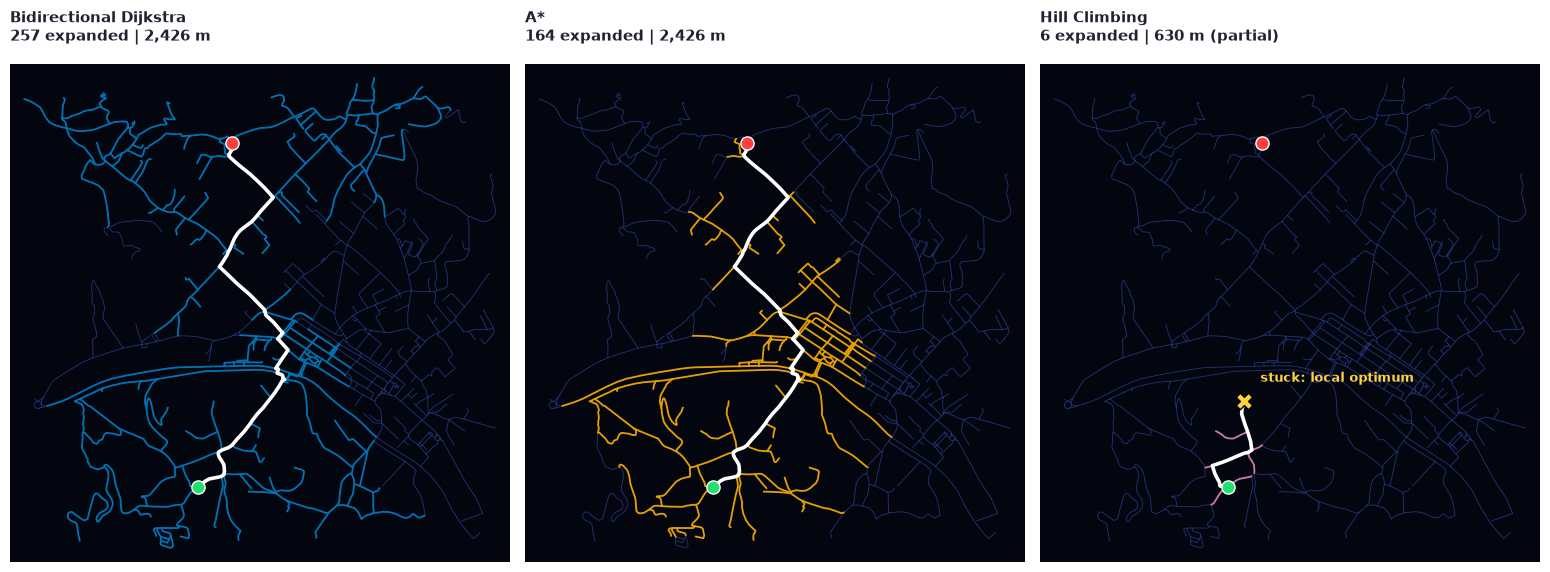

Bidirectional Dijkstra: reached B | 31 nodes, 30 edges, 2,426.5 m | OSM ids: 620893001 -> 849906847 -> 2574785532 -> 268101182 -> ... -> 2834816962 -> 402980028 -> 402980103
A*: reached B | 31 nodes, 30 edges, 2,426.5 m | OSM ids: 620893001 -> 849906847 -> 2574785532 -> 268101182 -> ... -> 2834816962 -> 402980028 -> 402980103
Hill Climbing: STOPPED before B | 6 nodes, 5 edges, 629.6 m | OSM ids: 620893001 -> 401837619 -> 268101193 -> 268101194 -> 2574785609 -> 2574785660


In [24]:
# Search results and solution paths (Figure 8) + textual path listing.
fig, axes = plt.subplots(1, len(COMPARE_ALGORITHMS), figsize=(5.2 * len(COMPARE_ALGORITHMS), 6.2))
fig.patch.set_facecolor("white")
for ax, name in zip(np.atleast_1d(axes), COMPARE_ALGORITHMS):
    r, tr = RUNS[name]["result"], RUNS[name]["trace"]
    draw_streets(ax, range(len(PROBLEM.seg_pts)), MAP_BASE, lw=0.6, alpha=0.8)
    draw_streets(ax, scanned_segments(tr), ALGO_COLORS[name], lw=1.3, zorder=2)
    pxy = path_xy(r)
    ax.plot(pxy[:, 0], pxy[:, 1], color="white", lw=2.6, zorder=3)
    ax.scatter(*PROBLEM.xy[SRC], s=90, c=COLORS["start"], zorder=5, edgecolor="white")
    ax.scatter(*PROBLEM.xy[DST], s=90, c=COLORS["end"], zorder=5, edgecolor="white")
    if not r.reached:
        ax.scatter(*PROBLEM.xy[r.path[-1]], s=140, marker="X", c="#ffd23f", zorder=6, edgecolor="black")
        ax.annotate("stuck: local optimum", PROBLEM.xy[r.path[-1]], xytext=(12, 14), textcoords="offset points",
                    color="#ffd23f", fontsize=9, fontweight="bold", zorder=7)
    setup_map_axis(ax, dark=True)
    sub = f"{r.settled} expanded | {r.distance:,.0f} m" + ("" if r.reached else " (partial)")
    ax.set_title(f"{name}\n{sub}", color=INK, loc="left")
fig.tight_layout()
FIG_PATHS = save_fig(fig, "fig10_solution_paths.png")
plt.show()

PATH_TEXT = {}
for name in COMPARE_ALGORITHMS:
    r = RUNS[name]["result"]
    ids = [PROBLEM.node_ids[i] for i in r.path]
    shown = ids if len(ids) <= 8 else ids[:4] + ["..."] + ids[-3:]
    PATH_TEXT[name] = (f"{name}: {'reached B' if r.reached else 'STOPPED before B'} | {len(r.path)} nodes, "
                       f"{len(r.path) - 1} edges, {r.distance:,.1f} m | OSM ids: " + " -> ".join(map(str, shown)))
    print(PATH_TEXT[name])


### 14.3 Performance charts

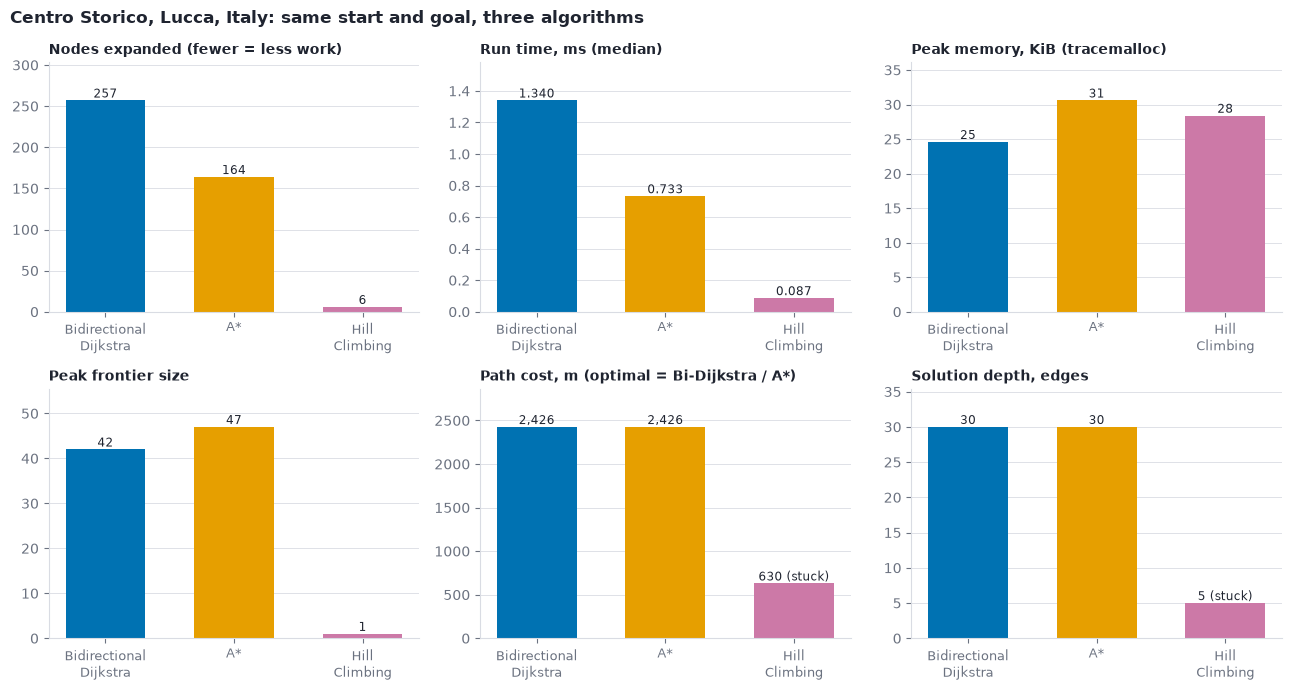

In [25]:
# Performance comparison charts (Figure 11): one small panel per metric, bars start at zero, values labelled directly.
_metrics = [
    ("Nodes expanded", "Nodes expanded (fewer = less work)", "{:,.0f}"),
    ("Time (ms, median)", "Run time, ms (median)", "{:.3f}"),
    ("Peak memory (KiB)", "Peak memory, KiB (tracemalloc)", "{:,.0f}"),
    ("Peak frontier", "Peak frontier size", "{:,.0f}"),
    ("Path cost (m)", "Path cost, m (optimal = Bi-Dijkstra / A*)", "{:,.0f}"),
    ("Solution depth (edges)", "Solution depth, edges", "{:,.0f}"),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (col, title, fmt) in zip(axes.ravel(), _metrics):
    vals = BENCH_DF[col].astype(float)
    bars = ax.bar(range(len(vals)), vals.values, color=[ALGO_COLORS[a] for a in vals.index], width=0.62)
    ax.set_xticks(range(len(vals))); ax.set_xticklabels([wrap(a) for a in vals.index])
    for b, a in zip(bars, vals.index):
        stuck = (not RUNS[a]["result"].reached) and col in ("Path cost (m)", "Solution depth (edges)")
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(b.get_height()) + (" (stuck)" if stuck else ""),
                ha="center", va="bottom", fontsize=8.5)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, vals.max() * 1.18 if vals.max() > 0 else 1)
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(axis="y", color=GRID, lw=0.6); ax.set_axisbelow(True)
fig.suptitle(f"{PLACE}: same start and goal, three algorithms", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
FIG_PERF = save_fig(fig, "fig11_performance.png")
plt.show()


### 14.4 Visualization of the search process
Snapshots of the explored region after 25 / 50 / 75 / 100 % of each run. Below, the combined interactive viewer and MP4 for all three algorithms (Bidirectional Dijkstra, A*, Hill Climbing), and the final frame of each video as the interface screenshot.

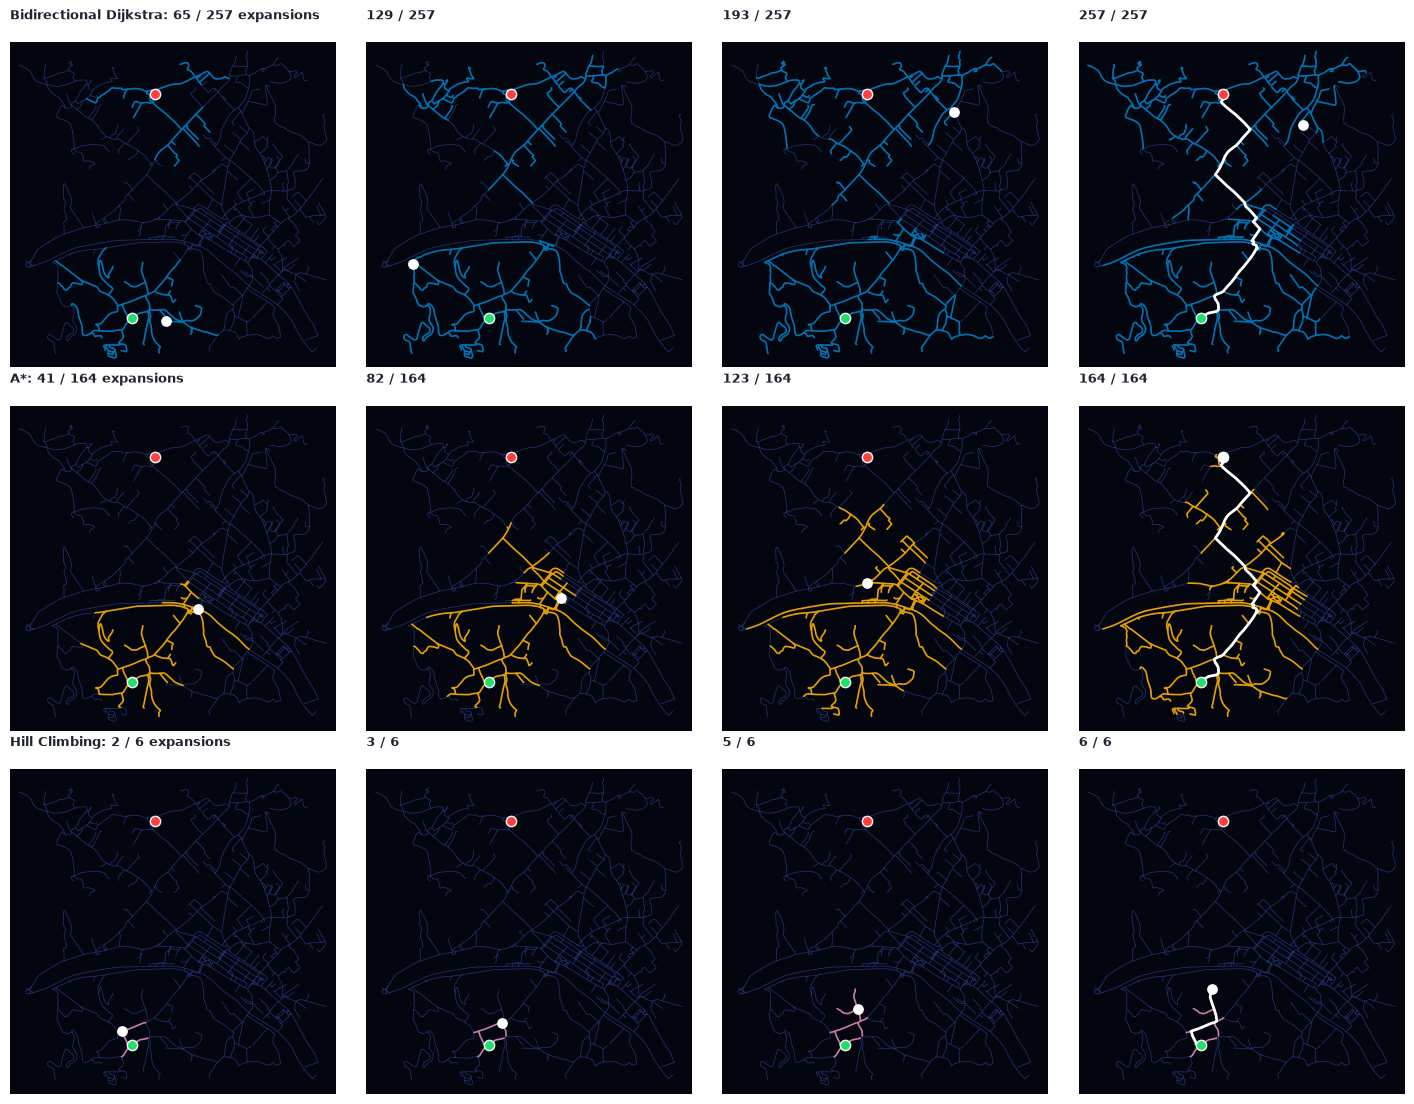

In [26]:
# Visualization of the search process: the explored region after 25 / 50 / 75 / 100 % of each run (Figure 9).
FRACS = [0.25, 0.5, 0.75, 1.0]
fig, axes = plt.subplots(len(COMPARE_ALGORITHMS), len(FRACS), figsize=(3.6 * len(FRACS), 3.7 * len(COMPARE_ALGORITHMS)))
fig.patch.set_facecolor("white")
for row, name in zip(np.atleast_2d(axes), COMPARE_ALGORITHMS):
    r, tr = RUNS[name]["result"], RUNS[name]["trace"]
    n_ev = len(tr.events)
    for ax, fr in zip(row, FRACS):
        k = max(1, math.ceil(fr * n_ev))
        draw_streets(ax, range(len(PROBLEM.seg_pts)), MAP_BASE, lw=0.5, alpha=0.8)
        draw_streets(ax, scanned_segments(tr, k), ALGO_COLORS[name], lw=1.2, zorder=2)
        ax.scatter(*PROBLEM.xy[tr.events[k - 1][0]], s=45, c="white", zorder=6)
        ax.scatter(*PROBLEM.xy[SRC], s=55, c=COLORS["start"], zorder=5, edgecolor="white")
        ax.scatter(*PROBLEM.xy[DST], s=55, c=COLORS["end"], zorder=5, edgecolor="white")
        if fr == 1.0:
            pxy = path_xy(r); ax.plot(pxy[:, 0], pxy[:, 1], color="white", lw=2, zorder=4)
        setup_map_axis(ax, dark=True)
        ax.set_title(f"{name}: {k} / {n_ev} expansions" if fr == FRACS[0] else f"{k} / {n_ev}", color=INK, loc="left", fontsize=9)
fig.tight_layout()
FIG_PROGRESS = save_fig(fig, "fig12_search_progress.png")
plt.show()


Bidirectional Dijkstra html: exports\bidirectional-dijkstra-e76453_centro-storico-lucca-italy-e9cb17.html   mp4: exports\bidirectional-dijkstra-e76453_centro-storico-lucca-italy-e9cb17.mp4
A*             html: exports\a-4cac2d_centro-storico-lucca-italy-e9cb17.html   mp4: exports\a-4cac2d_centro-storico-lucca-italy-e9cb17.mp4
Hill Climbing  html: exports\hill-climbing-3b0983_centro-storico-lucca-italy-e9cb17.html   mp4: exports\hill-climbing-3b0983_centro-storico-lucca-italy-e9cb17.mp4


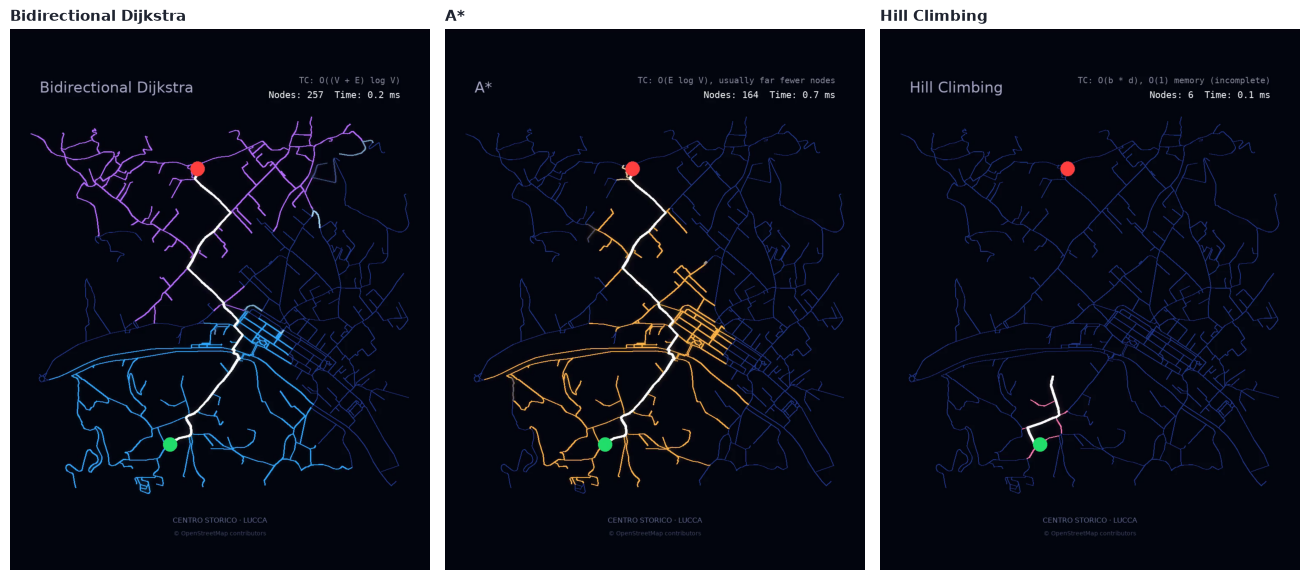

In [27]:
from PIL import Image
# Interface: an animation (HTML5 + MP4) for every compared algorithm, plus a screenshot of the finished interface.
ANIM = {}


def last_video_frame(mp4_path):
    import imageio_ffmpeg
    gen = imageio_ffmpeg.read_frames(str(mp4_path))
    w, h = next(gen)["size"]
    last = None
    for frame in gen:
        last = frame
    return np.frombuffer(last, np.uint8).reshape(h, w, 3)


for _name in COMPARE_ALGORITHMS:
    if _name == ALGORITHM:                          # already exported in sections 8-10
        ANIM[_name] = {"payload": PAYLOAD, "json": PAYLOAD_JSON, "html": ANIMATION_FILE, "mp4": MP4_FILE if RENDER_MP4 else None}
        continue
    if not EXPORT_ALL_ANIMATIONS or len(RUNS[_name]["result"].path) < 2:
        continue
    _bench_ms = BENCH_DF.loc[_name, "Time (ms, median)"]
    _payload, _json, _info = build_payload(PROBLEM, RUNS[_name]["result"], RUNS[_name]["trace"],
                                           {"clean_ms": float(_bench_ms)}, SRC, DST, _name, PLACE)
    (EXPORT_DIR / f"{_payload['file_stem']}.json").write_text(_json, encoding="utf-8")
    _html_file = EXPORT_DIR / f"{_payload['file_stem']}.html"
    _html_file.write_text(
        ANIMATION_TEMPLATE.replace("__MAXW__", "720").replace("__CW__", f"{_payload['canvas']['w']:g}")
        .replace("__CH__", f"{_payload['canvas']['h']:g}").replace("__BG__", _payload["style"]["bg"])
        .replace("__PAYLOAD__", _json.replace("</", "<\\/")), encoding="utf-8")
    _mp4 = render_mp4(_payload, fps=MP4_FPS, height=MP4_HEIGHT) if RENDER_MP4 else None
    ANIM[_name] = {"payload": _payload, "json": _json, "html": _html_file, "mp4": _mp4}

SCREENSHOTS = {}
for _name, _a in ANIM.items():
    if _a["mp4"] is not None:
        _img = last_video_frame(_a["mp4"])
        _p = RES / f"interface_{slugify(_name)}.png"
        Image.fromarray(_img).save(_p)
        SCREENSHOTS[_name] = _p
    print(f"{_name:14s} html: {_a['html']}   mp4: {_a['mp4']}")

if SCREENSHOTS:
    fig, axes = plt.subplots(1, len(SCREENSHOTS), figsize=(4.4 * len(SCREENSHOTS), 7.2))
    for ax, (nm, p) in zip(np.atleast_1d(axes), SCREENSHOTS.items()):
        ax.imshow(Image.open(p)); ax.axis("off"); ax.set_title(nm, loc="left")
    fig.tight_layout()
    FIG_UI = save_fig(fig, "fig09_interface_screenshots.png")
    plt.show()


In [28]:
import subprocess, base64
# Merge the per-algorithm MP4s into ONE video (ffmpeg concat, stream-copy; all three share codec/fps/size
# because render_mp4 always encodes at MP4_FPS/MP4_HEIGHT), then wrap it as a single self-contained HTML file.

def merge_videos(mp4_paths, out_mp4):
    import imageio_ffmpeg
    ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()
    list_file = EXPORT_DIR / "_concat_list.txt"
    lines = ["file '%s'" % Path(p).resolve().as_posix() for p in mp4_paths]
    list_file.write_text(chr(10).join(lines) + chr(10), encoding="utf-8")
    subprocess.run([ffmpeg, "-y", "-f", "concat", "-safe", "0", "-i", str(list_file),
                    "-c", "copy", str(out_mp4)], check=True, capture_output=True)
    list_file.unlink()
    return Path(out_mp4)


def _video_data_uri(mp4_path):
    return "data:video/mp4;base64," + base64.b64encode(Path(mp4_path).read_bytes()).decode("ascii")


def video_tag_html(data_uri, max_w="720px"):
    """Inline <video> snippet (for display() inside the already-open notebook page)."""
    return ("<video controls autoplay loop muted playsinline "
            "style=\"width:100%;max-width:" + max_w + ";display:block;margin:0 auto;background:#04060f;\">"
            "<source src=\"" + data_uri + "\" type=\"video/mp4\"></video>")


def standalone_video_doc(data_uri):
    """Full, dependency-free HTML page (for opening the exported .html file directly in a browser)."""
    return ("<!DOCTYPE html><html><head><meta charset=\"utf-8\">"
            "<title>Combined Algorithm Visualization</title>"
            "<style>html,body{margin:0;padding:0;background:#04060f;height:100%;"
            "display:flex;align-items:center;justify-content:center;}"
            "video{max-width:100%;max-height:100vh;}</style></head><body>"
            "<video controls autoplay loop muted playsinline><source src=\"" + data_uri + "\" type=\"video/mp4\"></video>"
            "</body></html>")


_merge_order = [n for n in COMPARE_ALGORITHMS if n in ANIM and ANIM[n]["mp4"]]
if len(_merge_order) == len(COMPARE_ALGORITHMS):
    COMBINED_MP4 = merge_videos([ANIM[n]["mp4"] for n in _merge_order], EXPORT_DIR / f"{slugify(PLACE)}_combined.mp4")
    COMBINED_URI = _video_data_uri(COMBINED_MP4)
    COMBINED_HTML = EXPORT_DIR / f"{slugify(PLACE)}_combined.html"
    COMBINED_HTML.write_text(standalone_video_doc(COMBINED_URI), encoding="utf-8")
    print(f"Merged video ({' -> '.join(_merge_order)}): {COMBINED_MP4}")
    print(f"Single combined HTML (one <video>, no separate players): {COMBINED_HTML}")
else:
    COMBINED_MP4 = COMBINED_URI = COMBINED_HTML = None
    print("Skipping merged video: not all three algorithms rendered an MP4.")


Merged video (Bidirectional Dijkstra -> A* -> Hill Climbing): exports\centro-storico-lucca-italy-e9cb17_combined.mp4
Single combined HTML (one <video>, no separate players): exports\centro-storico-lucca-italy-e9cb17_combined.html


In [29]:
# Combined viewer: all three algorithms merged into ONE video (not separate players).
if COMBINED_URI is not None:
    display(HTML(video_tag_html(COMBINED_URI)))
else:
    for _name, _a in ANIM.items():
        display(Markdown(f'**{_name}**'))
        display(HTML(animation_html(_a['payload'], _a['json'])))


### 14.5 Statistical comparison over many random start/goal pairs
One instance can be lucky or unlucky, so the same three algorithms are run on many random pairs of the same map.

200 random A-B pairs (straight-line distance >= 30% of the map diagonal)


,Bidirectional Dijkstra,A*,Hill Climbing
Success rate,100.0%,100.0%,10.5%
Mean nodes expanded,283.2,130.8,10.1
Median nodes expanded,289.0,115.0,8.0
Mean time (ms),2.324,1.116,0.18
Mean cost / optimal (solved),1.0,1.0,1.0637
Optimal when solved,100.0%,100.0%,4.8%


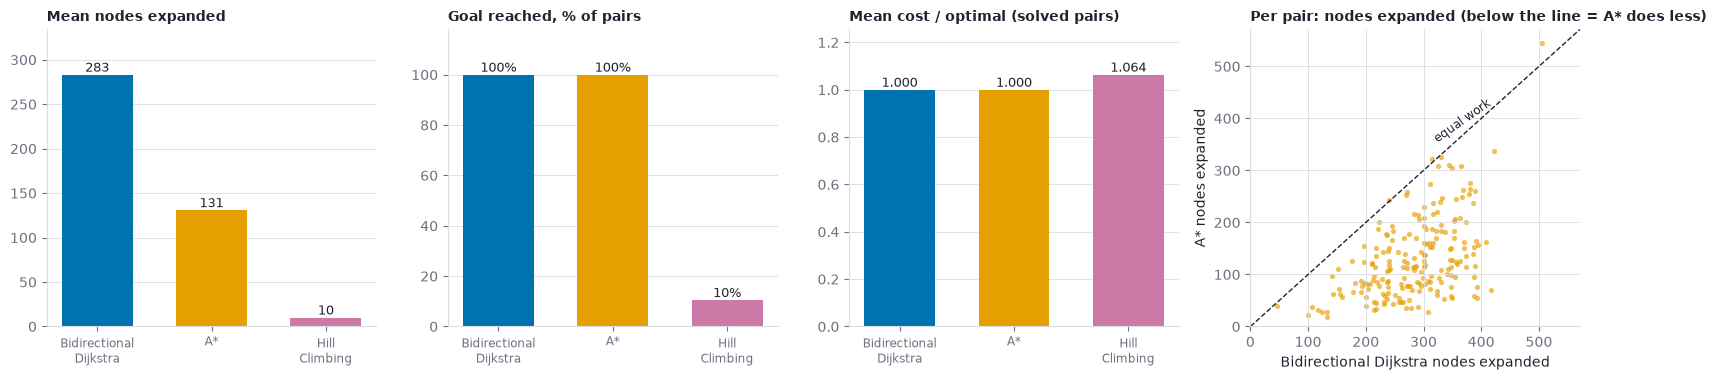

In [30]:
# Statistical comparison over many random start/goal pairs on the same map (not just one lucky instance).
# The optimal cost of every pair comes from networkx, so both Bidirectional Dijkstra and A* are checked as well.
def sample_pairs(problem, count, seed, min_fraction=0.3):
    rng = random.Random(seed)
    xy = problem.xy
    n = len(xy)
    diag = float(np.hypot(*(xy.max(axis=0) - xy.min(axis=0))))
    pairs = []
    while len(pairs) < count:
        i = rng.randrange(n)
        d = np.hypot(*(xy - xy[i]).T)
        far = np.flatnonzero(d >= min_fraction * diag)
        if far.size:
            pairs.append((i, int(far[rng.randrange(far.size)])))
    return pairs


PAIRS = sample_pairs(PROBLEM, N_RANDOM_PAIRS, SEED + 1)
_acc = {name: {"reached": [], "expanded": [], "ms": [], "ratio": []} for name in COMPARE_ALGORITHMS}
for _s, _t in PAIRS:
    _opt = nx.shortest_path_length(G, PROBLEM.node_ids[_s], PROBLEM.node_ids[_t], weight="length")   # networkx reference
    for _name in COMPARE_ALGORITHMS:
        t0 = time.perf_counter()
        _r = ALGORITHMS[_name].fn(PROBLEM, _s, _t)
        _ms = (time.perf_counter() - t0) * 1000
        _acc[_name]["reached"].append(_r.reached)
        _acc[_name]["expanded"].append(_r.settled)
        _acc[_name]["ms"].append(_ms)
        if _r.reached:
            _acc[_name]["ratio"].append(_r.distance / _opt)

PAIR_STATS = {}
for _name, _a in _acc.items():
    ok = np.array(_a["reached"])
    PAIR_STATS[_name] = {
        "Success rate": f"{ok.mean():.1%}",
        "Mean nodes expanded": round(float(np.mean(_a["expanded"])), 1),
        "Median nodes expanded": round(float(np.median(_a["expanded"])), 1),
        "Mean time (ms)": round(float(np.mean(_a["ms"])), 3),
        "Mean cost / optimal (solved)": round(float(np.mean(_a["ratio"])), 4) if _a["ratio"] else float("nan"),
        "Optimal when solved": f"{np.mean(np.isclose(_a['ratio'], 1.0, atol=1e-6)):.1%}" if _a["ratio"] else "-",
    }
PAIR_DF = pd.DataFrame(PAIR_STATS)
print(f"{N_RANDOM_PAIRS} random A-B pairs (straight-line distance >= 30% of the map diagonal)")
display(PAIR_DF)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
_labels = list(COMPARE_ALGORITHMS)
_cols = [ALGO_COLORS[a] for a in _labels]
_panels = [
    ("Mean nodes expanded", [np.mean(_acc[a]["expanded"]) for a in _labels], "{:,.0f}"),
    ("Goal reached, % of pairs", [100 * np.mean(_acc[a]["reached"]) for a in _labels], "{:.0f}%"),
    ("Mean cost / optimal (solved pairs)", [np.mean(_acc[a]["ratio"]) if _acc[a]["ratio"] else 0 for a in _labels], "{:.3f}"),
]
for ax, (title, vals, fmt) in zip(axes[:3], _panels):
    bars = ax.bar(range(len(_labels)), vals, color=_cols, width=0.62)
    ax.set_xticks(range(len(_labels))); ax.set_xticklabels([wrap(a) for a in _labels])
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(b.get_height()), ha="center", va="bottom", fontsize=9)
    ax.set_title(title, fontsize=10); ax.set_ylim(0, max(vals) * 1.18)
    ax.tick_params(axis="x", labelsize=8.5); ax.grid(axis="y", color=GRID, lw=0.6); ax.set_axisbelow(True)
ax = axes[3]
ax.scatter(_acc["Bidirectional Dijkstra"]["expanded"], _acc["A*"]["expanded"], s=14, color=ALGO_COLORS["A*"], alpha=0.65, linewidths=0)
_m = max(max(_acc["Bidirectional Dijkstra"]["expanded"]), max(_acc["A*"]["expanded"])) * 1.05
ax.plot([0, _m], [0, _m], color=INK, ls="--", lw=1)
ax.text(_m * 0.55, _m * 0.62, "equal work", rotation=35, fontsize=8.5)
ax.set_xlim(0, _m); ax.set_ylim(0, _m)
ax.set_xlabel("Bidirectional Dijkstra nodes expanded"); ax.set_ylabel("A* nodes expanded")
ax.set_title("Per pair: nodes expanded (below the line = A* does less)", fontsize=10); ax.grid(color=GRID, lw=0.6)
fig.tight_layout()
FIG_PAIRS = save_fig(fig, "fig13_random_pairs.png")
plt.show()


### 14.6 Comparison across towns
The same experiment on the other cached towns (Hill Climbing is expected to fail on some).

,Nodes,Optimal cost (m),Bi-Dijkstra expanded,A* expanded,A* / Bi-Dijkstra,Same cost (A*),Hill Climbing,HC expanded
Town,,,,,,,,
Centro Storico,559,2426.5,257,164,64%,yes,"stuck, 1,327 m from B",6
Bruges,3119,2475.1,1993,1303,65%,yes,"stuck, 1,722 m from B",8
Chefchaouen,1071,2324.2,858,557,65%,yes,"stuck, 1,680 m from B",2
Sidi Bou Said,292,1736.5,189,103,54%,yes,"stuck, 928 m from B",8
Hallstatt,29,2175.3,14,10,71%,yes,"stuck, 1,067 m from B",4


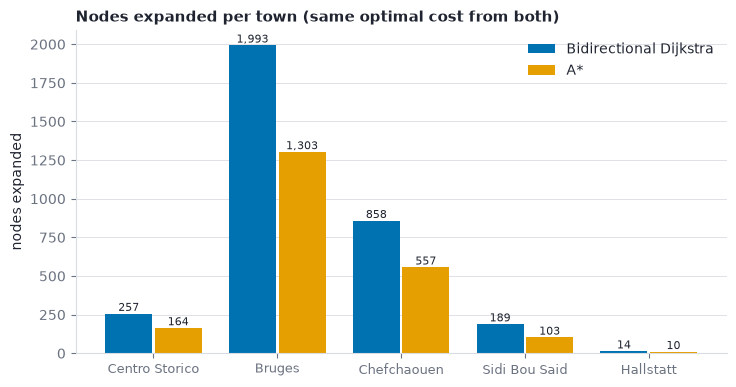

In [31]:
# Same comparison on several different towns (reuses the cached maps of the smoke test).
TOWN_ROWS = []
_quiet = lambda *a, **k: None
for _place in dict.fromkeys([PLACE] + (SMOKE_TEST_PLACES if RUN_SMOKE_TEST else [])):
    try:
        if _place == PLACE:
            _G, _prob, _a, _b = G, PROBLEM, A_NODE, B_NODE
        else:
            _raw, _, _ = load_graph(_place, NETWORK_TYPE, FALLBACK_RADIUS_M, MAX_NODES, log=_quiet)
            _G = clean_graph(_raw, NETWORK_TYPE, log=_quiet)
            _a, _b, _ = pick_endpoints(_G, SEED, MIN_AB_DISTANCE_FRACTION, log=_quiet)
            _prob = build_problem(_G)
        _s, _t = _prob.index[_a], _prob.index[_b]
        _out = {n: ALGORITHMS[n].fn(_prob, _s, _t) for n in COMPARE_ALGORITHMS}
        _hxy = np.hypot(*(_prob.xy - _prob.xy[_t]).T)
        _hc = _out["Hill Climbing"]
        TOWN_ROWS.append({
            "Town": _place.split(",")[0], "Nodes": len(_prob.adj),
            "Optimal cost (m)": round(_out["Bidirectional Dijkstra"].distance, 1),
            "Bi-Dijkstra expanded": _out["Bidirectional Dijkstra"].settled, "A* expanded": _out["A*"].settled,
            "A* / Bi-Dijkstra": f"{_out['A*'].settled / _out['Bidirectional Dijkstra'].settled:.0%}",
            "Same cost (A*)": "yes" if math.isclose(_out["A*"].distance, _out["Bidirectional Dijkstra"].distance, rel_tol=1e-9) else "NO",
            "Hill Climbing": "reached B" if _hc.reached else f"stuck, {_hxy[_hc.path[-1]]:,.0f} m from B",
            "HC expanded": _hc.settled,
        })
    except Exception as exc:                          # keep the report going if a map is unavailable offline
        print(f"  skipped {_place}: {exc}")
TOWN_DF = pd.DataFrame(TOWN_ROWS).set_index("Town")
display(TOWN_DF)

FIG_TOWNS = None
if len(TOWN_DF) > 1:
    fig, ax = plt.subplots(figsize=(8.4, 4.2))
    x = np.arange(len(TOWN_DF))
    ax.bar(x - 0.2, TOWN_DF["Bi-Dijkstra expanded"], 0.38, color=ALGO_COLORS["Bidirectional Dijkstra"], label="Bidirectional Dijkstra")
    ax.bar(x + 0.2, TOWN_DF["A* expanded"], 0.38, color=ALGO_COLORS["A*"], label="A*")
    for xi, d, a in zip(x, TOWN_DF["Bi-Dijkstra expanded"], TOWN_DF["A* expanded"]):
        ax.text(xi - 0.2, d, f"{d:,}", ha="center", va="bottom", fontsize=8)
        ax.text(xi + 0.2, a, f"{a:,}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(TOWN_DF.index, fontsize=9)
    ax.set_ylabel("nodes expanded"); ax.legend(frameon=False)
    ax.set_title("Nodes expanded per town (same optimal cost from both)")
    ax.grid(axis="y", color=GRID, lw=0.6); ax.set_axisbelow(True)
    FIG_TOWNS = save_fig(fig, "fig14_towns.png")
    plt.show()


### 14.7 Comparative analysis

### Comparative analysis of the search algorithms
| Property | Bidirectional Dijkstra | A* | Hill Climbing |
|---|---|---|---|
| Uses heuristic | no | yes | yes |
| Complete | yes | yes | no |
| Optimal | yes | yes (if `h` admissible) | no |
| Time complexity | O((V+E) log V), two half-radius waves | O((V+E) log V) worst case, usually far less | O(b d) |
| Space complexity | O(V) | O(V) | O(1) extra |
| Exploration shape | two circles that grow towards each other | stretched towards B | a single thin line |
| Needs | reversible graph + known goal | good admissible heuristic | good heuristic, luck |
| Weakness | blind: explores in every direction | needs a good heuristic, memory heavy | stuck in dead ends |

In [32]:
# Comparative analysis: every sentence below is computed from the measurements above.
BI = "Bidirectional Dijkstra"
_b, _a, _h = (BENCH_DF.loc[k] for k in (BI, "A*", "Hill Climbing"))
_hc_res = RUNS["Hill Climbing"]["result"]
_pb, _pa, _ph = (PAIR_STATS[k] for k in (BI, "A*", "Hill Climbing"))


def _rel(x, y):
    """'34% fewer' / '12% more' for x compared with y."""
    return f"{abs(1 - x / y):.0%} {'fewer' if x < y else 'more'}"


_pair_x, _pair_y = PAIR_STATS["A*"]["Mean nodes expanded"], PAIR_STATS[BI]["Mean nodes expanded"]
_fw, _bw = TREE_STATS[BI]["fwd_nodes"], TREE_STATS[BI]["bwd_nodes"]
_lines = [
    f"- **Optimality.** Bidirectional Dijkstra and A* both returned {_b['Path cost (m)']:,.1f} m, identical to the networkx optimum "
    f"({OPT_COST:,.1f} m). Over {N_RANDOM_PAIRS} random pairs both matched the networkx optimum in "
    f"{_pb['Optimal when solved']} (Bidirectional Dijkstra) and {_pa['Optimal when solved']} (A*) of their solved pairs.",
    f"- **Search effort.** Bidirectional Dijkstra expanded **{_b['Nodes expanded']} nodes** ({_fw} from A + {_bw} from B) and A* "
    f"**{_a['Nodes expanded']}**, i.e. A* did {_rel(_a['Nodes expanded'], _b['Nodes expanded'])} expansions on this instance "
    f"({_a['Streets scanned']} vs {_b['Streets scanned']} streets scanned). Averaged over {N_RANDOM_PAIRS} pairs A* expanded "
    f"{_pair_x} nodes vs {_pair_y} for Bidirectional Dijkstra ({_rel(_pair_x, _pair_y)}). "
    f"Both waves of Bidirectional Dijkstra stay small, but it cannot aim at B, while A* can.",
    f"- **Time.** The median run took {_b['Time (ms, median)']:.3f} ms (Bidirectional Dijkstra), {_a['Time (ms, median)']:.3f} ms (A*) and "
    f"{_h['Time (ms, median)']:.3f} ms (Hill Climbing). A* pays a small per-node cost for the heuristic, and Bidirectional Dijkstra "
    f"runs two heaps; on a graph this small both effects are tiny.",
    f"- **Memory.** Peak traced memory: Bidirectional Dijkstra {_b['Peak memory (KiB)']:,.1f} KiB (two sets of `dist`/`prev` arrays), "
    f"A* {_a['Peak memory (KiB)']:,.1f} KiB (it stores the heuristic table), Hill Climbing {_h['Peak memory (KiB)']:,.1f} KiB. "
    f"Peak frontier (both heaps together): {_b['Peak frontier']} (Bidirectional Dijkstra), {_a['Peak frontier']} (A*), "
    f"{_h['Peak frontier']} (Hill Climbing).",
    (f"- **Hill Climbing failed on this instance:** it stopped after {_hc_res.settled} nodes, {H_TARGET[_hc_res.path[-1]]:,.0f} m "
     f"(straight line) short of B, because no neighbour was closer to B than the node it stood on (a local optimum). "
     if not _hc_res.reached else
     f"- **Hill Climbing reached B** on this instance with a path {(_hc_res.distance / OPT_COST - 1):+.1%} longer than optimal. ")
    + f"Over {N_RANDOM_PAIRS} random pairs it reached the goal in only **{_ph['Success rate']}** of the pairs, "
      f"but it expanded just {_ph['Mean nodes expanded']} nodes on average.",
    f"- **Heuristic quality.** h was admissible on all {len(PROBLEM.adj):,} nodes (largest h/h* = {HEUR['max_ratio']:.2f}) and on average "
    f"{HEUR['mean_ratio']:.0%} of the true remaining distance, which is why A* is optimal and focused on B. "
    f"Bidirectional Dijkstra needs no heuristic at all: its saving comes from meeting in the middle.",
]
ANALYSIS_MD = "\n".join(_lines)
display(Markdown("#### Observed on this project\n\n" + ANALYSIS_MD))


#### Observed on this project

- **Optimality.** Bidirectional Dijkstra and A* both returned 2,426.5 m, identical to the networkx optimum (2,426.5 m). Over 200 random pairs both matched the networkx optimum in 100.0% (Bidirectional Dijkstra) and 100.0% (A*) of their solved pairs.
- **Search effort.** Bidirectional Dijkstra expanded **257 nodes** (143 from A + 114 from B) and A* **164**, i.e. A* did 36% fewer expansions on this instance (241 vs 339 streets scanned). Averaged over 200 pairs A* expanded 130.8 nodes vs 283.2 for Bidirectional Dijkstra (54% fewer). Both waves of Bidirectional Dijkstra stay small, but it cannot aim at B, while A* can.
- **Time.** The median run took 1.340 ms (Bidirectional Dijkstra), 0.733 ms (A*) and 0.087 ms (Hill Climbing). A* pays a small per-node cost for the heuristic, and Bidirectional Dijkstra runs two heaps; on a graph this small both effects are tiny.
- **Memory.** Peak traced memory: Bidirectional Dijkstra 24.6 KiB (two sets of `dist`/`prev` arrays), A* 30.6 KiB (it stores the heuristic table), Hill Climbing 28.4 KiB. Peak frontier (both heaps together): 42 (Bidirectional Dijkstra), 47 (A*), 1 (Hill Climbing).
- **Hill Climbing failed on this instance:** it stopped after 6 nodes, 1,327 m (straight line) short of B, because no neighbour was closer to B than the node it stood on (a local optimum). Over 200 random pairs it reached the goal in only **10.5%** of the pairs, but it expanded just 10.1 nodes on average.
- **Heuristic quality.** h was admissible on all 559 nodes (largest h/h* = 0.96) and on average 70% of the true remaining distance, which is why A* is optimal and focused on B. Bidirectional Dijkstra needs no heuristic at all: its saving comes from meeting in the middle.

### 14.8 Generate `RESULTS.md`
Writes the complete report (all tables, figures and analysis above) to `RESULTS.md`.

In [33]:
# Writes RESULTS.md: every number and figure of the report, regenerated from this run.
import datetime as _dt


def md_table(df, index=True, index_label=""):
    d = df.reset_index() if index else df
    if index and index_label:
        d = d.rename(columns={d.columns[0]: index_label})
    head = "| " + " | ".join(str(c) for c in d.columns) + " |"
    sep = "|" + "|".join("---" for _ in d.columns) + "|"
    body = ["| " + " | ".join(str(v) for v in row) + " |" for row in d.itertuples(index=False)]
    return "\n".join([head, sep, *body])


def _static_md():
    """Static explanatory text lives in the notebook's own markdown cells (tagged with metadata 'report')."""
    for candidate in [Path("dijkstra_osm_visualizer.ipynb"), *sorted(Path(".").glob("*.ipynb"))]:
        if candidate.exists():
            cells = json.loads(candidate.read_text(encoding="utf-8"))["cells"]
            found = {c["metadata"]["report"]: "".join(c["source"]) for c in cells if "report" in c.get("metadata", {})}
            if found:
                return found
    return {}


TXT = _static_md()


def block(key):
    t = TXT.get(key, "")
    return "\n".join(l for l in t.splitlines() if not l.startswith("### ") and not l.startswith("## ")).strip()


def fig(path, caption):
    return f"![{caption}]({Path(path).as_posix()})\n\n*{caption}*"


_ui = (fig(FIG_UI, "Figure 9. Interface: final frame of each algorithm's animation (also saved one by one as results/interface_*.png)")
       if SCREENSHOTS else "_MP4 rendering is disabled (`RENDER_MP4 = False`), so no interface screenshots were produced._")
_anim = "\n".join(f"- **{n}**: `{a['html'].as_posix()}` (interactive HTML5)" + (f", `{Path(a['mp4']).as_posix()}` (video)" if a["mp4"] else "")
                  for n, a in ANIM.items())
_front = "\n\n".join(f"**{n}** - first expansion steps\n\n{md_table(pd.DataFrame(FRONTIER_ROWS[n]), index=False)}"
                     for n in COMPARE_ALGORITHMS)
_bench_cols = ["Goal reached", "Path cost (m)", "Cost vs optimal", "Solution depth (edges)"]
_towns = md_table(TOWN_DF, index_label="Town") if len(TOWN_DF) else "_not available_"

RESULTS_MD = f"""# Lab Report: Bidirectional Dijkstra, A* and Hill Climbing on OpenStreetMap

*Generated automatically by `dijkstra_osm_visualizer.ipynb` on {_dt.date.today().isoformat()}. Re-run the notebook to refresh every number and figure.*

**Instance:** {PLACE} ({NETWORK_TYPE} network), seed {SEED}. Start A = OSM node {A_NODE}, goal B = OSM node {B_NODE}, {AB_INFO['straight_m']:,.0f} m apart in a straight line, optimal walking distance {OPT_COST:,.1f} m.

---

# 1. Design

## 1.1 Problem formulation

{block('problem')}

Concrete instance: {INSTANCE['states']:,} states, {INSTANCE['actions']:,} actions, mean branching factor {INSTANCE['avg_branching']:.2f} (max {INSTANCE['max_branching']}).

## 1.2 Problem state-space diagram

{fig(FIG_STATE, 'Figure 1. State space of the problem: all intersections (left) and the first two layers around A with step costs (right)')}

## 1.3 Search algorithm workflow / flowcharts

{fig(FIG_FLOW_BI, 'Figure 2. Workflow of Bidirectional Dijkstra')}

{fig(FIG_FLOW_ASTAR, 'Figure 3. Workflow of A*')}

{fig(FIG_FLOW_HC, 'Figure 4. Workflow of Hill Climbing')}

## 1.4 Search tree / state-space graph

{fig(FIG_TREE, 'Figure 5. First levels of the A* search tree with g, h and f values and the order in which A* expanded the nodes')}

{fig(FIG_TREE_MAP, 'Figure 6. Search trees drawn on the map (edge = parent -> child of every expanded node; Bidirectional Dijkstra has a blue tree grown from A and a purple tree grown from B)')}

Search-tree size: Bidirectional Dijkstra {TREE_STATS['Bidirectional Dijkstra']['tree_nodes']} nodes ({TREE_STATS['Bidirectional Dijkstra']['fwd_nodes']} forward, depth {TREE_STATS['Bidirectional Dijkstra']['fwd_depth']}; {TREE_STATS['Bidirectional Dijkstra']['bwd_nodes']} backward, depth {TREE_STATS['Bidirectional Dijkstra']['bwd_depth']}); A* {TREE_STATS['A*']['tree_nodes']} nodes / depth {TREE_STATS['A*']['tree_depth']}.

## 1.5 Algorithm-specific design and pseudocode

{block('pseudocode')}

## 1.6 Frontier and explored-set representation

{block('frontier')}

{_front}

{fig(FIG_FRONTIER, 'Figure 7. Frontier size after every expansion')}

## 1.7 Heuristic function design

{block('heuristic')}

| Property | Measured on this map |
|---|---|
| Admissible (h <= h*) | violations: {HEUR['admissible_violations']} of {len(PROBLEM.adj):,} nodes; largest h/h* = {HEUR['max_ratio']:.3f} |
| Informedness | mean h/h* = {HEUR['mean_ratio']:.1%} |
| Consistent (h(u) <= w(u,v) + h(v)) | violations: {HEUR['consistency_violations']} of {HEUR['edges']:,} edges (largest excess {HEUR['max_consistency_excess_m'] * 100:.2f} cm, from map-projection distortion; A* re-opens closed nodes so optimality is unaffected) |

{fig(FIG_HEUR, 'Figure 8. Heuristic h versus true remaining cost h*')}

---

# 2. Implementation

## 2.1 Dataset loading and preprocessing

{block('dataset')}

{md_table(pd.DataFrame(_rows, columns=['Item', 'Value']), index=False)}

## 2.2 Model implementation and training

{block('model')}

## 2.3 Prediction generation

{block('prediction')}

{chr(10).join('- ' + t for t in PATH_TEXT.values())}

## 2.4 Code snippets for key functionalities

{SNIPPETS_MD}

---

# 3. Results

## 3.1 Project interface screenshots

The interface of this project is the animated search viewer (HTML5 canvas, plus an MP4 export of the same animation). Blue = streets explored by the forward wave of Bidirectional Dijkstra and purple = its backward wave, amber = A*, pink = Hill Climbing, white = final path, green = A, red = B, the header shows the live node counter and time.

{_ui}

Animation files:

{_anim}

## 3.2 Search results and solution paths

{fig(FIG_PATHS, 'Figure 10. Explored streets and solution path of each algorithm (X marks where Hill Climbing got stuck)')}

{chr(10).join('- ' + t for t in PATH_TEXT.values())}

## 3.3 Performance evaluation: execution time, memory usage and nodes expanded

{md_table(BENCH_DF.T, index_label='Metric')}

Time = median of {TIMING_REPEATS} uninstrumented runs; memory = `tracemalloc` peak of one run (includes the heuristic table, `g`/`prev` arrays and the priority queue); "Nodes expanded" counts nodes removed from the frontier and processed (for Hill Climbing: states visited).

> **Timing caveat:** absolute milliseconds depend on the machine and on how Python is run (a Jupyter kernel can be several times slower than a plain `python` process), and the timings in 3.6 were taken in a different cell, so compare the **ratios between algorithms**, not the absolute values, and do not compare numbers across tables.

## 3.4 Path cost and solution depth

{md_table(BENCH_DF[_bench_cols], index_label='Algorithm')}

Optimal cost (networkx reference): **{OPT_COST:,.1f} m**. Solution depth = number of street segments walked.

{fig(FIG_PERF, 'Figure 11. Performance comparison on the main instance')}

## 3.5 Visualization of the search process

{fig(FIG_PROGRESS, 'Figure 12. Explored region after 25 / 50 / 75 / 100 % of each search (the white dot is the node being expanded)')}

## 3.6 Statistical comparison over {N_RANDOM_PAIRS} random start/goal pairs

{md_table(PAIR_DF, index_label='Metric')}

{fig(FIG_PAIRS, 'Figure 13. Averages over random start/goal pairs, and per-pair work of A* versus Bidirectional Dijkstra')}

## 3.7 Comparison across towns

{_towns}

{fig(FIG_TOWNS, 'Figure 14. Nodes expanded by Bidirectional Dijkstra and A* in different towns') if FIG_TOWNS else ''}

## 3.8 Comparative analysis of the search algorithms

{block('theory')}

#### Observed on this project

{ANALYSIS_MD}

## 3.9 Conclusion

* Use the algorithm A* when a good admissible heuristic exists (here: straight-line distance): it is optimal and steers the search towards B.
* Use **Bidirectional Dijkstra** when no heuristic is available (or it is weak) but the goal is known and the graph can be searched backwards: it is optimal and its two small waves explore far less than one big wave.
* **Hill Climbing** is the cheapest but unreliable: it only works while the heuristic keeps pointing the right way, so use it only when speed and memory matter more than success.
"""
Path("RESULTS.md").write_text(RESULTS_MD, encoding="utf-8")
print(f"Wrote RESULTS.md ({len(RESULTS_MD):,} characters) and {len(list(RES.glob('*.png')))} images in {RES}/")


Wrote RESULTS.md (32,462 characters) and 18 images in results/
